In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import os
import sklearn
import umap.umap_ as umap
from scipy.stats import gaussian_kde
from tqdm.notebook import tqdm

In [58]:
import h5py
dt_params_rubsov_approximation_list = []
dt_params_list = []
h5_path = '/home3/rfit/Telescope_Array/phd_work/data/normed/Ivan_Kharuk_pr_ga_all_0001_eq_eff_normed_one_work_rubsov_approx.h5'
with h5py.File(h5_path, 'r') as f:
    print(f.keys())
    print(f['norm_param'].keys())
    print(f['norm_param']['recos'].keys())
    mean_recos = f['norm_param']['recos']['mean'][:]
    std_recos = f['norm_param']['recos']['std'][:]
    mc_params = f['test']['mc_params'][:]

    mean_dt_params = f['norm_param']['dt_params']['mean'][:]
    std_dt_params = f['norm_param']['dt_params']['std'][:]
    if 'dt_params_rubsov_approximation' in f['test'].keys():
        dt_params_rubsov_approximation = f['test']['dt_params_rubsov_approximation'][:]
        ev_start = f['test']['ev_starts'][:]
        dt_params = f['test']['dt_params'][:]
        real_dt_params = dt_params * std_dt_params + mean_dt_params
        real_dt_params = dt_params[:,-1] + dt_params[:,-2]
        mean_Time = real_dt_params.mean()
        std_Time = real_dt_params.std()
        real_dt_params = (real_dt_params - mean_Time) / std_Time
        dt_params = np.concatenate([dt_params[:,:], real_dt_params[:,None]], axis=1)

        dt_params_rubsov_approximation_realtime = dt_params_rubsov_approximation * std_dt_params + mean_dt_params
        dt_params_rubsov_approximation_realtime = dt_params_rubsov_approximation[:,-1] + dt_params_rubsov_approximation[:,-2]
        dt_params_rubsov_approximation_realtime = (dt_params_rubsov_approximation_realtime - mean_Time) / std_Time
        dt_params_rubsov_approximation = np.concatenate([dt_params_rubsov_approximation[:,:], dt_params_rubsov_approximation_realtime[:,None]], axis=1)
        # dt_params_rubsov_approximation = (dt_params_rubsov_approximation - f['norm_param']['dt_params']['mean'][:])/f['norm_param']['dt_params']['std'][:]
        
        for i in range(1, len(ev_start)):
            dt_params_rubsov_approximation_list.append(dt_params_rubsov_approximation[ev_start[i-1]:ev_start[i]])
            dt_params_list.append(dt_params[ev_start[i-1]:ev_start[i]])
    else:
        dt_params_rubsov_approximation = None
    print(mean_recos.shape, std_recos.shape, dt_params_rubsov_approximation.shape)
    print(ev_start.shape, dt_params.shape, dt_params_rubsov_approximation.shape)
    dt_params = dt_params_list
    dt_params_rubsov_approximation = dt_params_rubsov_approximation_list
    print(len(dt_params), len(dt_params_rubsov_approximation))

<KeysViewHDF5 ['norm_param', 'test', 'train', 'val']>
<KeysViewHDF5 ['dt_bundle', 'dt_params', 'dt_params_rubsov_approximation', 'recos', 'wfs_flat']>
<KeysViewHDF5 ['mean', 'std']>
(15,) (15,) (4593680, 7)
(421167,) (4593680, 7) (4593680, 7)
421166 421166


In [59]:
mean_dt_params, std_dt_params

(array([-6.9209188e-03,  1.2555914e-03,  1.1519995e-02,  1.9771105e+01,
        -6.8014187e-01,  2.1187034e+00], dtype=float32),
 array([1.1933613e+00, 1.1956286e+00, 2.0338846e-02, 3.9020176e+01,
        3.4595509e+00, 2.3166947e+00], dtype=float32))

In [60]:
dt_params_pr = [dt_params_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 14]
dt_params_ph = [dt_params_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 1]
dt_params_rubsov_approximation_pr = [dt_params_rubsov_approximation_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 14]
dt_params_rubsov_approximation_ph = [dt_params_rubsov_approximation_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 1]

print(len(dt_params_pr), len(dt_params_ph), len(dt_params_rubsov_approximation_pr), len(dt_params_rubsov_approximation_ph))



210315 210851 210315 210851


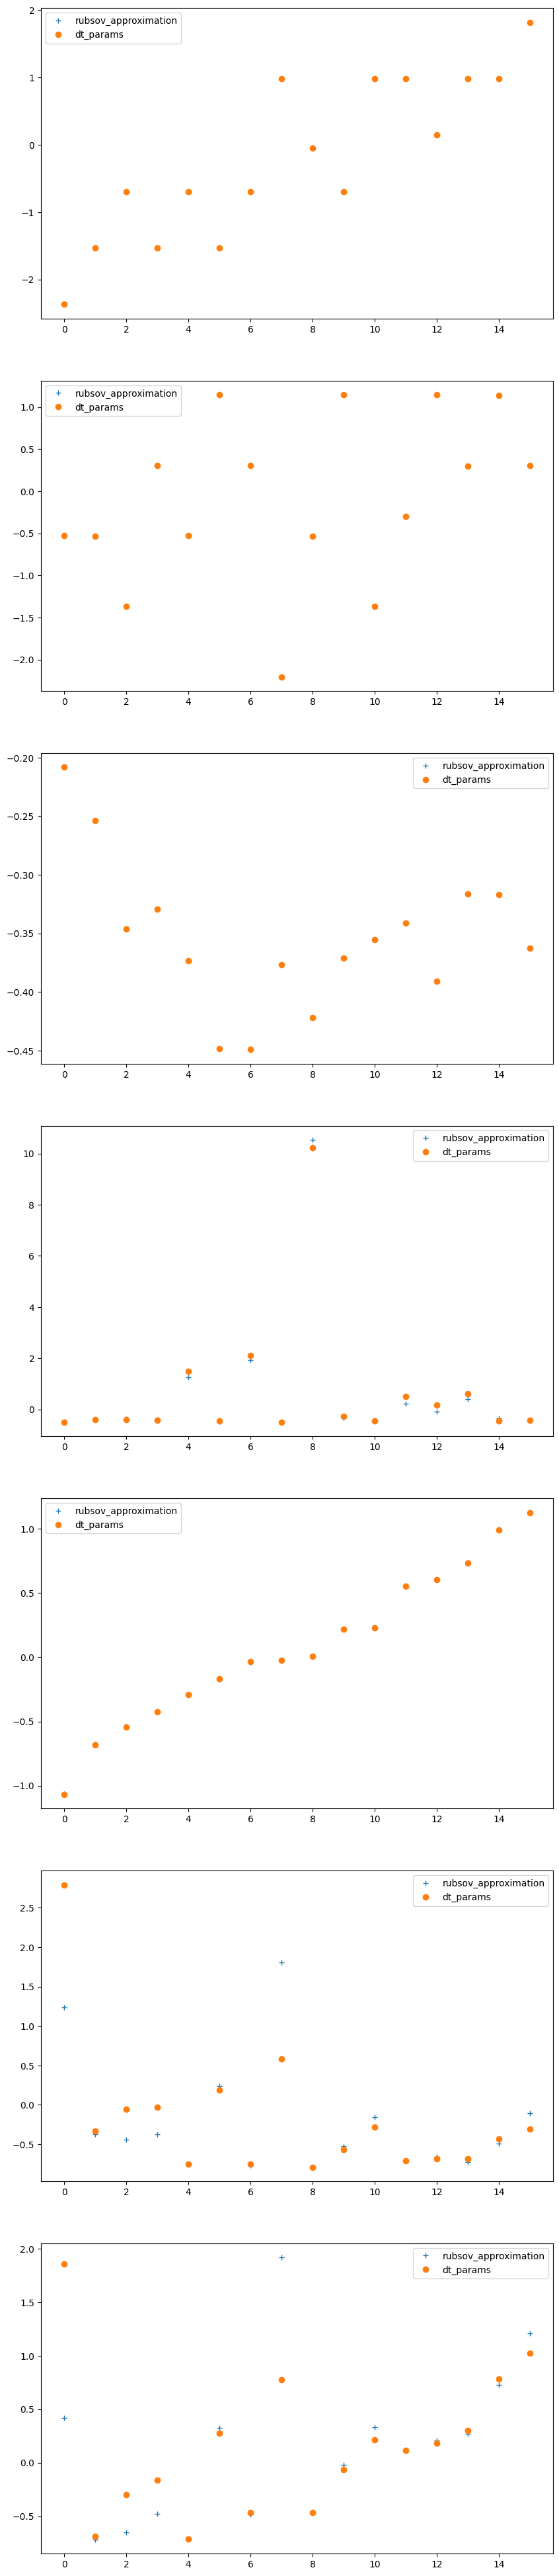

In [61]:
# show dt_params_rubsov_approximation

i = 20
fig, ax = plt.subplots(7,1, figsize=(10, 50))
for j in range(7):
    ax[j].plot(dt_params_rubsov_approximation_pr[i][:,j], '+', label='rubsov_approximation')
    ax[j].plot(dt_params_pr[i][:,j], 'o', label='dt_params')
    ax[j].legend()
plt.show()


In [62]:
path_save = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/runs_tests_Kharuk_one_work'
path_save = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/info_Transfoemr_Kharuk_one_work_photon_0.01'
path_save = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/info_Transfoemr_Kharuk_one_work_photon_0.01_FullyConnected_dim_6'
path_save_or = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/Original_VAE_dim_5_norm'
# path_save = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/Original_VAE_dim_5_norm_0.0_photon_GRID_Max_4_det'
path_save_sr = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/Original_VAE_dim_5_norm_0.0_photon_SR_Kharuk'

In [63]:
os.listdir(path_save)

['photon', 'pr']

In [64]:
os.listdir(os.path.join(path_save, 'pr'))

['recos.npy',
 'reconstruction_data.npy',
 'preds_num_det.npy',
 'num_det.npy',
 'recon_loss.npy',
 'original_data.npy',
 'embading.npy',
 'preds_log_var.npy',
 'loss_num_det.npy']

In [65]:
reconstruction_data_pr_or = np.load(os.path.join(path_save_or, 'pr', 'reconstruction_data.npy'), allow_pickle = True)
reconstruction_data_photon_or = np.load(os.path.join(path_save_or, 'photon', 'reconstruction_data.npy'), allow_pickle = True)

reconstruction_data_pr_sr = np.load(os.path.join(path_save_sr, 'pr', 'reconstruction_data.npy'), allow_pickle = True)
reconstruction_data_photon_sr = np.load(os.path.join(path_save_sr, 'photon', 'reconstruction_data.npy'), allow_pickle = True)


In [66]:
print(len(dt_params_pr), len(dt_params_ph), len(dt_params_rubsov_approximation_pr), len(dt_params_rubsov_approximation_ph))
print(len(dt_params_pr), len(dt_params_ph), len(dt_params_rubsov_approximation_pr), len(dt_params_rubsov_approximation_ph))


210315 210851 210315 210851
210315 210851 210315 210851


In [67]:
n=36
index_list=[]
for i in range(len(dt_params_pr)):
    if len(dt_params_pr[i]) ==n:
        print(i)
        index_list.append(i)
print(index_list)


62196
90766
143540
169931
180321
[62196, 90766, 143540, 169931, 180321]


In [68]:
def find_closes__detector(dt_params):
    '''
    dt_params - shape (N, 5) или 6 если плоский фронт
    '''
    # norm_param_dt_params = self.norm_param['dt_params']mean
    norm_param_dt_params_mean = torch.tensor(mean_dt_params[:2])
    norm_param_dt_params_std = torch.tensor(std_dt_params[:2])
    dt_params = torch.tensor(dt_params)


    coordinates = dt_params[:, :2]
    # делаем переномировку 
    coordinates = coordinates*norm_param_dt_params_std.unsqueeze(0) + norm_param_dt_params_mean.unsqueeze(0)
    distant = torch.sum(torch.pow(coordinates, 2), dim =1) # shape N
    argmin = torch.argmin(distant) # индекс самого ближайшего детектора
    # print('argmin', argmin)
    coordinates_from_armin = coordinates - coordinates[argmin] # координаты относительно самого ближнего
    # шаг сетки относительно постоянный и равен около 
    # print('coordinates_from_armin', coordinates_from_armin)
    coordinates_from_armin = torch.round(coordinates_from_armin)

    # print('coordinates_from_armin', coordinates_from_armin)
    index = torch.where((coordinates_from_armin[:,0]%2==0) * (coordinates_from_armin[:,1]%2==0))
    # print(index)
    # print(coordinates[index])
    return index[0], dt_params[index]
find_closes__detector(dt_params_pr[180321])

(tensor([ 4,  5, 11, 17, 19, 25, 33]),
 tensor([[ 0.5720, -3.1969,  0.4356, -0.4933, -2.9029, -0.2632, -2.6832],
         [ 2.2537, -1.5262,  0.0635, -0.4561, -2.5980, -0.3560, -2.4860],
         [ 0.5118, -1.5607,  1.0124, -0.0311, -1.4845, -0.6978, -1.7686],
         [-1.0986, -1.5205,  1.4273, -0.4881, -0.3873, -0.2213, -0.3053],
         [ 0.5789,  0.1497,  0.7725,  3.6198, -0.0760, -0.7812, -0.5364],
         [-1.0991,  0.1537,  1.0734,  0.1146,  1.0372, -0.7427,  0.5343],
         [-1.0960,  1.8270,  1.4508, -0.3257,  2.4478, -0.6996,  1.8859]]))

In [69]:
indexes_4_det = []
for i in range(len(dt_params_pr)):
    index, dt_params_pr_close = find_closes__detector(dt_params_pr[i])
    if len(index) >= 4:
        indexes_4_det.append(i)
print(len(indexes_4_det), indexes_4_det[:3], len(reconstruction_data_pr_or), len(reconstruction_data_pr_sr))

96074 [11, 12, 13] 210315 96074


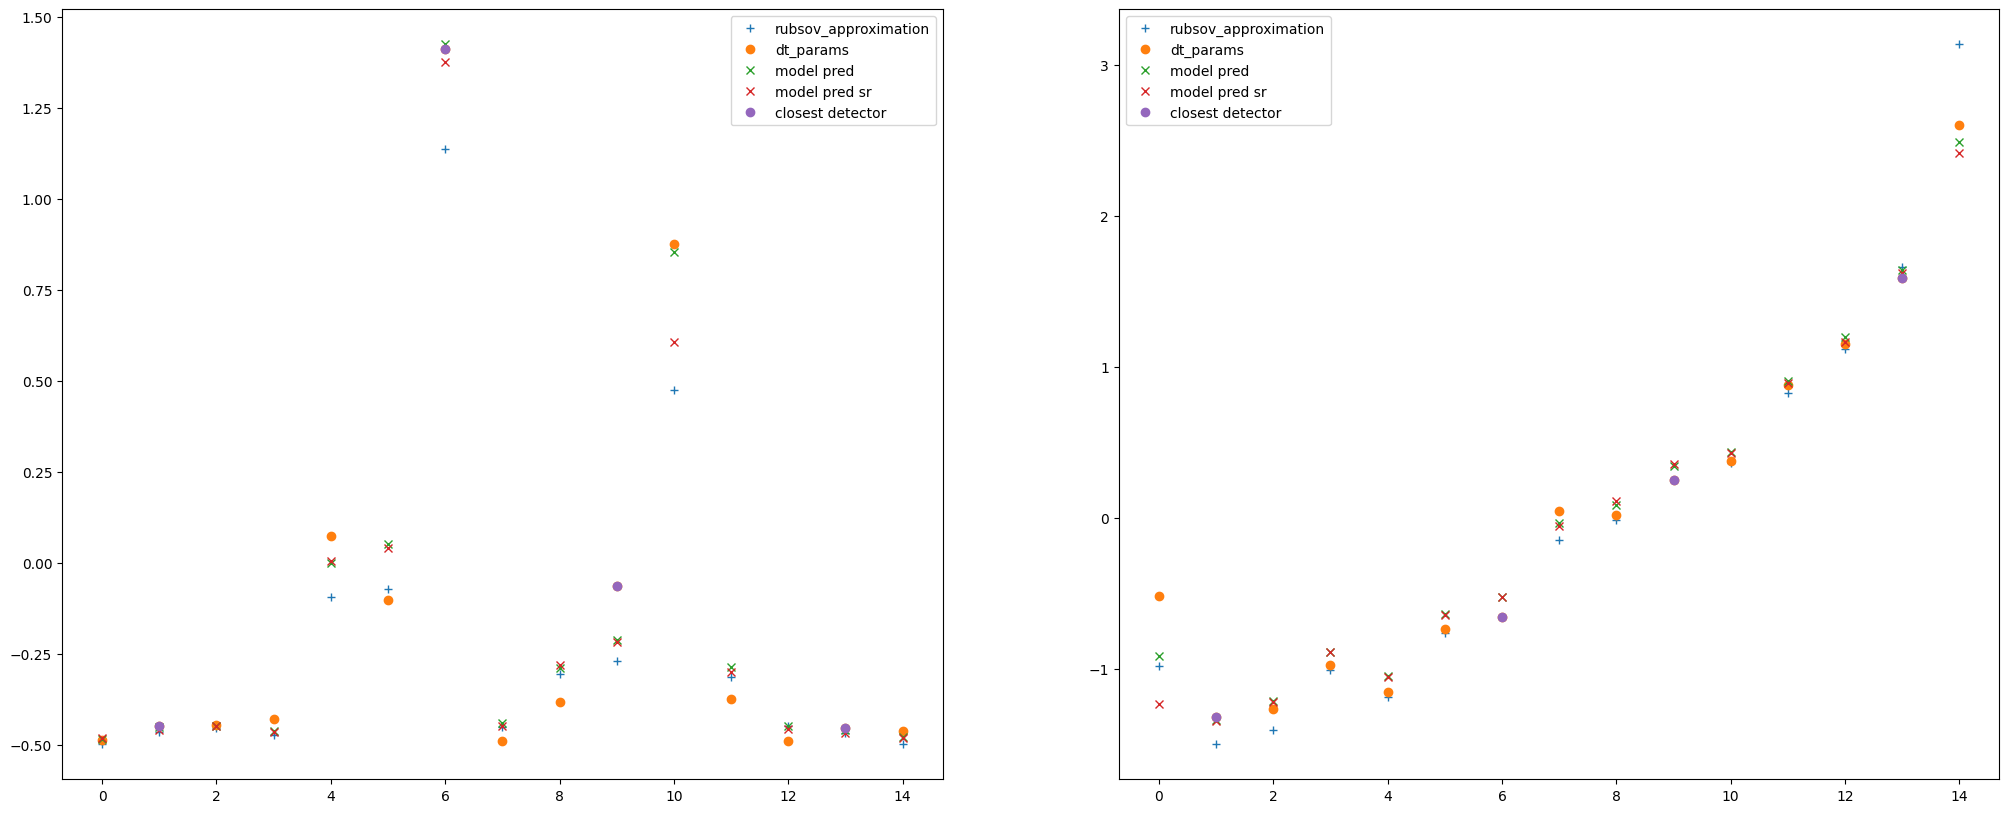

In [70]:
k = 960
i = indexes_4_det[k]

fig, ax = plt.subplots(1,2, figsize=(25, 10))
index, dt_params_pr_close = find_closes__detector(dt_params_pr[i])
for j in range(2):
    if j == 0:

        ax[j].plot(dt_params_rubsov_approximation_pr[i][:,3], '+', label='rubsov_approximation')
        ax[j].plot(dt_params_pr[i][:,3], 'o', label='dt_params')
        ax[j].plot(reconstruction_data_pr_or[i][:,3], 'x', label='model pred')
        ax[j].plot(reconstruction_data_pr_sr[k][:,3], 'x', label='model pred sr')

        if index is not None:
            ax[j].plot(index, dt_params_pr_close[:,3], 'o', label='closest detector')
        ax[j].legend()
    if j == 1:
        ax[j].plot(dt_params_rubsov_approximation_pr[i][:,6], '+', label='rubsov_approximation')
        ax[j].plot(dt_params_pr[i][:,6], 'o', label='dt_params')
        ax[j].plot(reconstruction_data_pr_or[i][:,4], 'x', label='model pred')
        ax[j].plot(reconstruction_data_pr_sr[k][:,4], 'x', label='model pred sr')
        if index is not None:
            ax[j].plot(index, dt_params_pr_close[:,6], 'o', label='closest detector')
        ax[j].legend()
        # print(len(dt_params_pr[i][:,j]), len(dt_params_rubsov_approximation_pr[i][:,j]), len(reconstruction_data_pr[k][:,j]))
plt.show()

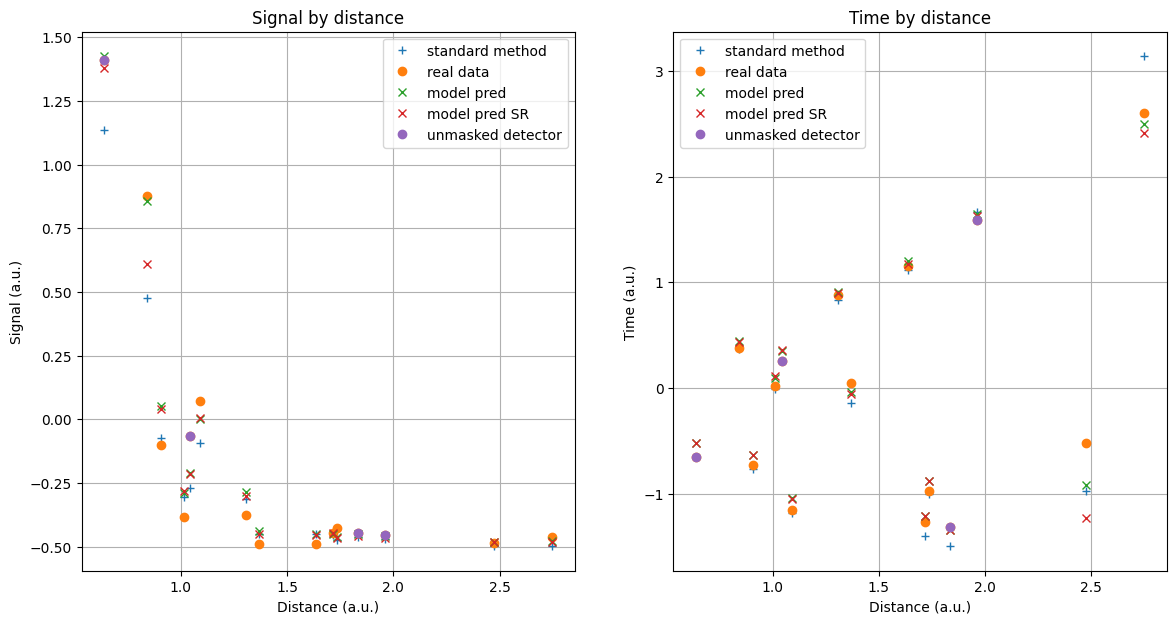

In [71]:
k = 960
i = indexes_4_det[k]

fig, ax = plt.subplots(1,2, figsize=(14, 7))
index, dt_params_pr_close = find_closes__detector(dt_params_pr[i])

coordinates = dt_params_pr[i][:,:2]
radius = np.sqrt(np.sum(coordinates**2, axis=1))

name_rub = 'standard method'
name_dt = 'real data'
name_or = 'model pred'
name_sr = 'model pred SR'
name_cd = 'unmasked detector'
for j in range(2):
    if j == 0:

        ax[j].plot(radius,dt_params_rubsov_approximation_pr[i][:,3], '+', label=name_rub)
        ax[j].plot(radius,dt_params_pr[i][:,3], 'o', label=name_dt)
        ax[j].plot(radius,reconstruction_data_pr_or[i][:,3], 'x', label=name_or)
        ax[j].plot(radius,reconstruction_data_pr_sr[k][:,3], 'x', label=name_sr)

        if index is not None:
            ax[j].plot(radius[index], dt_params_pr_close[:,3], 'o', label=name_cd)
        ax[j].legend()
    if j == 1:
        ax[j].plot(radius,dt_params_rubsov_approximation_pr[i][:,6], '+', label=name_rub)
        ax[j].plot(radius,dt_params_pr[i][:,6], 'o', label=name_dt)
        ax[j].plot(radius,reconstruction_data_pr_or[i][:,4], 'x', label=name_or)
        ax[j].plot(radius,reconstruction_data_pr_sr[k][:,4], 'x', label=name_sr)
        if index is not None:
            ax[j].plot(radius[index], dt_params_pr_close[:,6], 'o', label=name_cd)
        ax[j].legend()
ax[0].set_xlabel('Distance (a.u.)')

ax[1].set_xlabel('Distance (a.u.)')


ax[0].set_ylabel('Signal (a.u.)')

ax[1].set_ylabel('Time (a.u.)')
ax[0].set_title("Signal by distance")
ax[1].set_title("Time by distance")
ax[0].grid()
ax[1].grid()
        # print(len(dt_params_pr[i][:,j]), len(dt_params_rubsov_approximation_pr[i][:,j]), len(reconstruction_data_pr[k][:,j]))
plt.show()

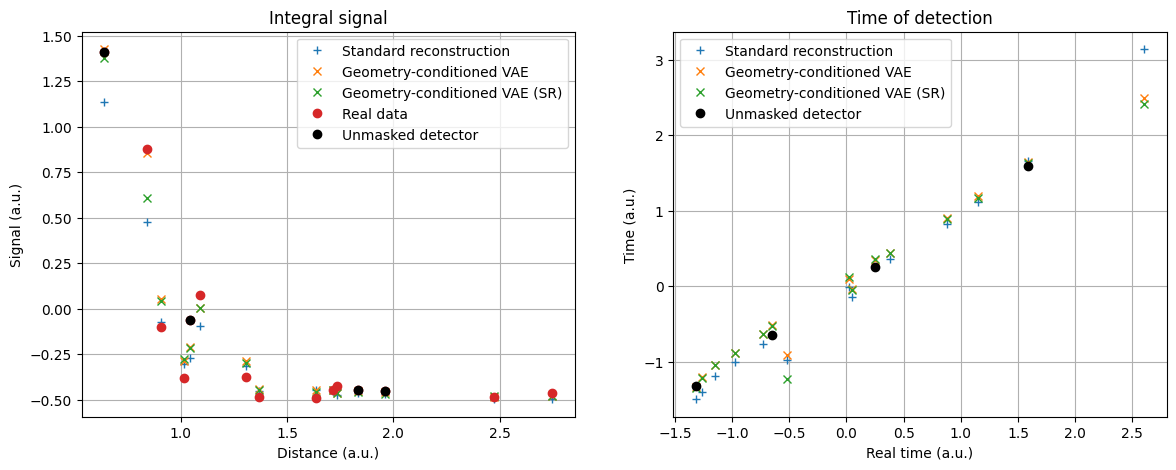

In [72]:
k = 960
i = indexes_4_det[k]

fig, ax = plt.subplots(1,2, figsize=(14, 5))
index, dt_params_pr_close = find_closes__detector(dt_params_pr[i])

coordinates = dt_params_pr[i][:,:2]
radius = np.sqrt(np.sum(coordinates**2, axis=1))

name_rub = 'Standard reconstruction'
name_dt = 'Real data'
name_or = 'Geometry-conditioned VAE'
name_sr = 'Geometry-conditioned VAE (SR)'
name_cd = 'Unmasked detector'
color = 'black'
for j in range(2):
    if j == 0:

        ax[j].plot(radius,dt_params_rubsov_approximation_pr[i][:,3], '+', label=name_rub)
        ax[j].plot(radius,reconstruction_data_pr_or[i][:,3], 'x', label=name_or)
        ax[j].plot(radius,reconstruction_data_pr_sr[k][:,3], 'x', label=name_sr)

        # if index is not None:
        #     ax[j].plot(radius[index], dt_params_pr_close[:,3], 'o', label=name_cd)
        ax[j].plot(radius,dt_params_pr[i][:,3], 'o', label=name_dt)
        
        ax[j].legend()
    if j == 1:
        ax[j].plot(dt_params_pr[i][:,6],dt_params_rubsov_approximation_pr[i][:,6], '+', label=name_rub)
        # ax[j].plot(dt_params_pr[i][:,6],dt_params_pr[i][:,6], 'o', label=name_dt)
        ax[j].plot(dt_params_pr[i][:,6],reconstruction_data_pr_or[i][:,4], 'x', label=name_or)
        ax[j].plot(dt_params_pr[i][:,6],reconstruction_data_pr_sr[k][:,4], 'x', label=name_sr)
        # if index is not None:
        #     ax[j].plot(dt_params_pr[i][:,6][index], dt_params_pr_close[:,6], 'o', label=name_cd)
        ax[j].legend()
ax[0].set_xlabel('Distance (a.u.)')

ax[1].set_xlabel('Real time (a.u.)')

if index is not None:
    ax[1].plot(dt_params_pr[i][:,6][index], dt_params_pr_close[:,6], 'o',  color = 'black', label=name_cd)

    ax[0].plot(radius[index], dt_params_pr_close[:,3], 'o', color = 'black', label=name_cd)
ax[1].legend()
ax[0].legend()
# if index is not None:
        #     ax[j].plot(dt_params_pr[i][:,6][index], dt_params_pr_close[:,6], 'o', label=name_cd)
        
ax[0].set_ylabel('Signal (a.u.)')

ax[1].set_ylabel('Time (a.u.)')
ax[0].set_title("Integral signal")
ax[1].set_title("Time of detection")
ax[0].grid()
ax[1].grid()
        # print(len(dt_params_pr[i][:,j]), len(dt_params_rubsov_approximation_pr[i][:,j]), len(reconstruction_data_pr[k][:,j]))
plt.show()

In [73]:
mse_all = []
mse_unvision = []
mse_vision = []
reconstruction_data_pr = reconstruction_data_pr_sr
rubsov_mse_all = []
rubsov_mse_unvision = []
rubsov_mse_vision = []

for i in tqdm(range(len(indexes_4_det))):
    index, dt_params_pr_close = find_closes__detector(dt_params_pr[indexes_4_det[i]])
    
    orig_data = dt_params_pr[indexes_4_det[i]][:,-2:]
    rubsov_data = dt_params_rubsov_approximation_pr[indexes_4_det[i]][:,-2:]
    predict_data = reconstruction_data_pr[i][:,-2:]
    mask = torch.zeros(len(orig_data), dtype=torch.bool)
    mask[index] = True
    

    mse_all.append(np.mean((orig_data - predict_data)**2))
    rubsov_mse_all.append(np.mean((orig_data - rubsov_data)**2))
    vision_orig_data = orig_data[mask]
    vision_predict_data = predict_data[mask]
    mse_vision.append(np.mean((vision_orig_data - vision_predict_data)**2))
    rubsov_mse_vision.append(np.mean((vision_orig_data - rubsov_data[mask])**2))
    unvision_orig_data = orig_data[~mask]
    unvision_predict_data = predict_data[~mask]
    mse_unvision.append(np.mean((unvision_orig_data - unvision_predict_data)**2))
    rubsov_mse_unvision.append(np.mean((unvision_orig_data - rubsov_data[~mask])**2))
print('orig', (orig_data - predict_data)**2)
print('vision', (vision_orig_data - vision_predict_data)**2)
print('unvision', (unvision_orig_data - unvision_predict_data)**2)

print(index, mask, ~mask)






  0%|          | 0/96074 [00:00<?, ?it/s]

orig [[1.40019879e-03 4.14054003e-03]
 [1.91362866e-03 1.08192209e-03]
 [1.00047275e-01 1.06083220e-02]
 [2.12242194e-02 1.41041225e-03]
 [3.53323460e-01 3.13268905e-03]
 [1.86158985e-01 1.70930997e-02]
 [1.18246362e-01 2.37418693e-02]
 [3.96815985e-02 5.11344969e-02]
 [9.94869024e-02 2.21053306e-02]
 [1.16161489e+00 4.97717783e-03]
 [1.99297976e+00 1.04614422e-02]
 [1.03790753e-01 1.42363608e-02]
 [2.69768238e-02 1.57687973e-04]
 [2.83262867e-04 2.49150135e-02]
 [1.24620602e-01 3.00855609e-04]
 [5.23926914e-02 8.31006946e-06]
 [4.50120382e-02 9.42157209e-02]]
vision [[1.4001988e-03 4.1405400e-03]
 [2.1224219e-02 1.4104123e-03]
 [1.8615898e-01 1.7093100e-02]
 [1.1616149e+00 4.9771778e-03]
 [1.0379075e-01 1.4236361e-02]
 [1.2462060e-01 3.0085561e-04]]
unvision [[1.91362866e-03 1.08192209e-03]
 [1.00047275e-01 1.06083220e-02]
 [3.53323460e-01 3.13268905e-03]
 [1.18246362e-01 2.37418693e-02]
 [3.96815985e-02 5.11344969e-02]
 [9.94869024e-02 2.21053306e-02]
 [1.99297976e+00 1.04614422e-02]

In [74]:
orig_data

array([[-0.49238402, -2.3072405 ],
       [-0.49540555, -1.8297865 ],
       [-0.63267004, -1.7375699 ],
       [-0.32619894, -1.1865566 ],
       [-0.659864  , -1.2887721 ],
       [-0.7038922 , -1.1034173 ],
       [-0.7293595 , -0.85323596],
       [-0.24159564,  0.02758973],
       [-0.16260381,  0.14295939],
       [-0.7474888 , -0.18154462],
       [-0.766913  ,  0.01647356],
       [-0.15267587,  0.76441133],
       [-0.600728  ,  0.8737782 ],
       [-0.43281633,  1.4037337 ],
       [-0.6874895 ,  1.2717608 ],
       [-0.67022353,  1.7718401 ],
       [-0.25799832,  2.8552172 ]], dtype=float32)

In [75]:
rubsov_data

array([[-0.48232776, -2.300272  ],
       [-0.48771355, -1.8304715 ],
       [-0.6823248 , -1.7857412 ],
       [-0.16174427, -1.045161  ],
       [-0.7384102 , -1.3523918 ],
       [-0.7054626 , -1.1095431 ],
       [-0.64539236, -0.7711267 ],
       [-0.58862466, -0.30128244],
       [-0.13687737,  0.15706417],
       [-0.76331145, -0.20307258],
       [-0.766913  ,  0.01647356],
       [-0.20627593,  0.7078444 ],
       [-0.61636263,  0.8550769 ],
       [-0.5379698 ,  1.2972579 ],
       [-0.7009435 ,  1.2598809 ],
       [-0.58674616,  1.8413645 ],
       [-0.30128396,  2.8078701 ]], dtype=float32)

In [76]:
predict_data

array([[-0.4549648 , -2.2428935 ],
       [-0.4516605 , -1.796894  ],
       [-0.31636754, -1.6345732 ],
       [-0.47188428, -1.1490011 ],
       [-0.0654538 , -1.2328017 ],
       [-0.27243072, -0.9726767 ],
       [-0.38548982, -0.699152  ],
       [-0.44079804, -0.19853966],
       [-0.47801927, -0.00571923],
       [ 0.33029363, -0.1109955 ],
       [ 0.6448164 ,  0.11875474],
       [-0.4748416 ,  0.6450951 ],
       [-0.43648174,  0.8863356 ],
       [-0.44964674,  1.2458888 ],
       [-0.33447307,  1.289106  ],
       [-0.44132903,  1.7689574 ],
       [-0.47015873,  2.5482714 ]], dtype=float32)

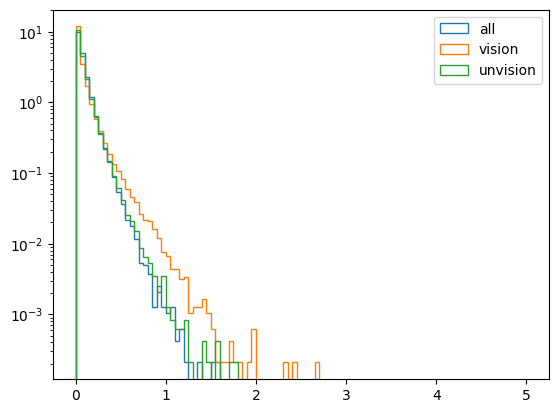

In [77]:
plt.hist(rubsov_mse_all, log=True, bins=100, density=True, range= (0,5), histtype='step', label='all')
# plt.show()
plt.hist(rubsov_mse_vision, log=True, bins=100, density=True, range= (0,5), histtype='step', label='vision')
# plt.show()
plt.hist(rubsov_mse_unvision, log=True, bins=100, density=True, range= (0,5), histtype='step', label='unvision')
plt.legend()
plt.show()


In [78]:
mse_all_norm = []
mse_unvision_norm = []
mse_vision_norm = []

rubsov_mse_all_norm = []
rubsov_mse_unvision_norm = []
rubsov_mse_vision_norm = []

for i in tqdm(range(len(indexes_4_det))):
    index, dt_params_pr_close = find_closes__detector(dt_params_pr[indexes_4_det[i]])
    orig_data = dt_params_pr[indexes_4_det[i]][:,-2:]
    predict_data = reconstruction_data_pr[i][:,-2:]
    rubsov_data = dt_params_rubsov_approximation_pr[indexes_4_det[i]][:,-2:]
    mask = torch.zeros(len(orig_data), dtype=torch.bool)
    mask[index] = True

    mse_all_norm.append(np.mean(((orig_data - predict_data)/orig_data)**2))
    rubsov_mse_all_norm.append(np.mean(((orig_data - rubsov_data)/orig_data)**2))
    vision_orig_data = orig_data[mask]
    vision_predict_data = predict_data[mask]
    mse_vision_norm.append(np.mean(((vision_orig_data - vision_predict_data)/vision_orig_data)**2))
    rubsov_mse_vision_norm.append(np.mean(((vision_orig_data - rubsov_data[mask])/vision_orig_data)**2))
    unvision_orig_data = orig_data[~mask]
    unvision_predict_data = predict_data[~mask]
    mse_unvision_norm.append(np.mean(((unvision_orig_data - unvision_predict_data)/unvision_orig_data)**2))
    rubsov_mse_unvision_norm.append(np.mean(((unvision_orig_data - rubsov_data[~mask])/unvision_orig_data)**2))

  0%|          | 0/96074 [00:00<?, ?it/s]

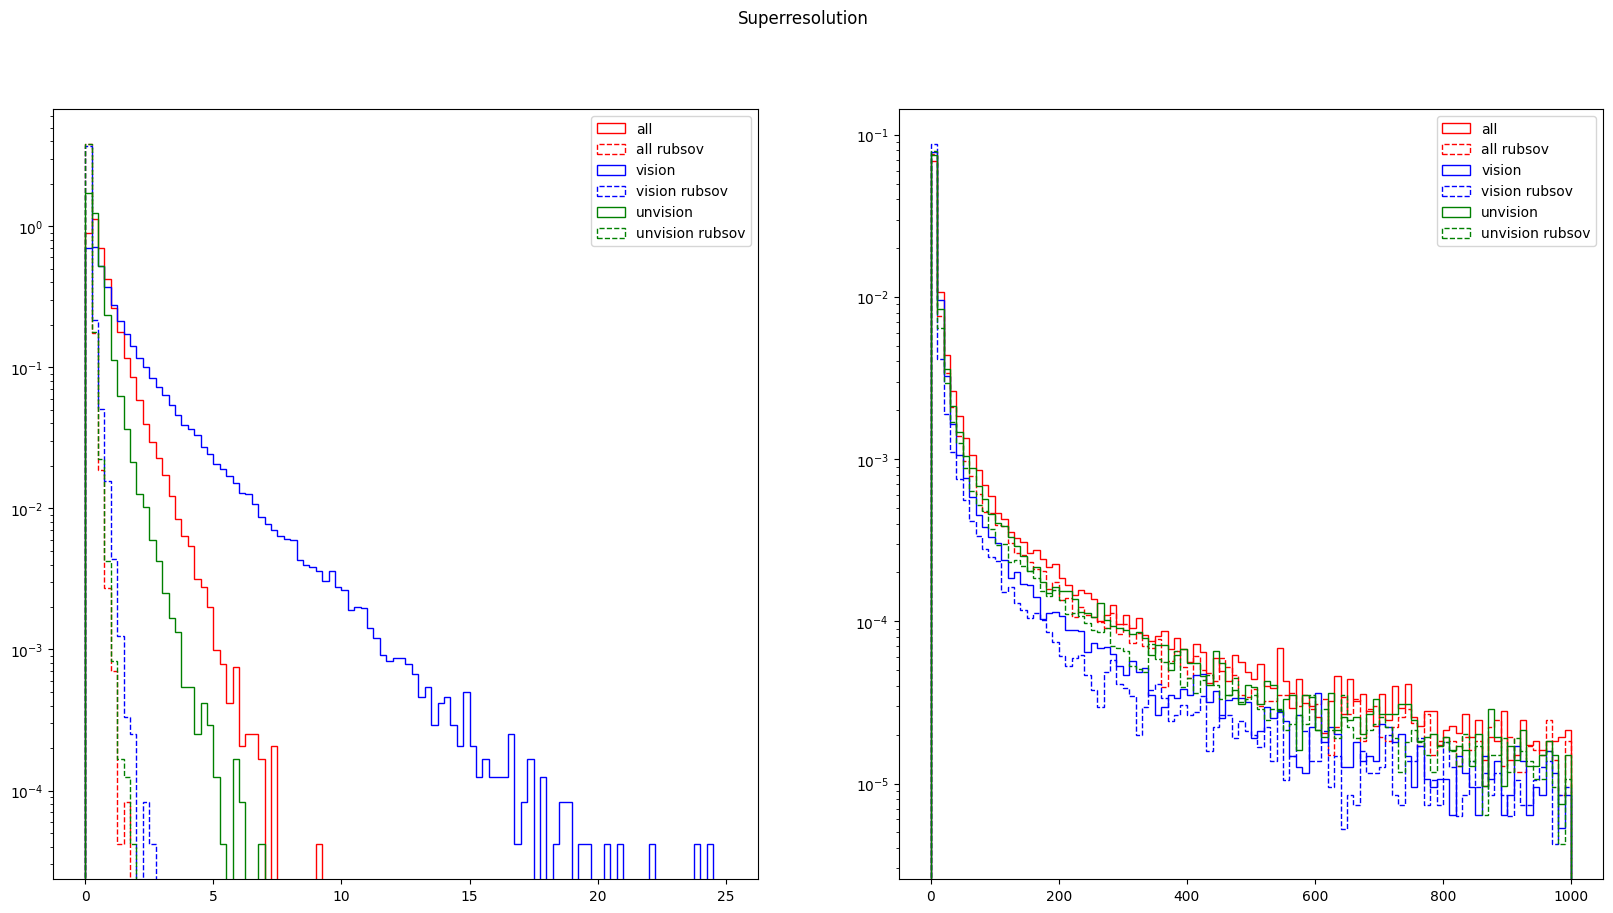

In [79]:
fig, ax = plt.subplots(1,2, figsize=(20, 10))
fig.suptitle('Superresolution')
ax[0].hist(mse_all, log=True, bins=100, density=True, range= (0,25), histtype='step', label='all', color = 'red', linestyle = '-')
ax[0].hist(rubsov_mse_all, log=True, bins=100, density=True, range= (0,25), histtype='step', label='all rubsov', color = 'red', linestyle = '--')

ax[0].hist(mse_vision, log=True, bins=100, density=True, range= (0,25), histtype='step', label='vision', color = 'blue', linestyle = '-')
ax[0].hist(rubsov_mse_vision, log=True, bins=100, density=True, range= (0,25), histtype='step', label='vision rubsov', color = 'blue', linestyle = '--')
ax[0].hist(mse_unvision, log=True, bins=100, density=True, range= (0,25), histtype='step', label='unvision', color = 'green', linestyle = '-')
ax[0].hist(rubsov_mse_unvision, log=True, bins=100, density=True, range= (0,25), histtype='step', label='unvision rubsov', color = 'green', linestyle = '--')
ax[0].legend()

ax[1].hist(mse_all_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='all', color = 'red', linestyle = '-')
ax[1].hist(rubsov_mse_all_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='all rubsov', color = 'red', linestyle = '--')
ax[1].hist(mse_vision_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='vision', color = 'blue', linestyle = '-')
ax[1].hist(rubsov_mse_vision_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='vision rubsov', color = 'blue', linestyle = '--')
ax[1].hist(mse_unvision_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='unvision', color = 'green', linestyle = '-')
ax[1].hist(rubsov_mse_unvision_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='unvision rubsov', color = 'green', linestyle = '--')
ax[1].legend()
plt.show()



In [80]:
original_mse_all = []
original_mse_unvision = []
original_mse_vision = []

for i in tqdm(range(len(indexes_4_det))):
    index, dt_params_pr_close = find_closes__detector(dt_params_pr[indexes_4_det[i]])
    orig_data = dt_params_pr[indexes_4_det[i]][:,-2:]
    predict_data = reconstruction_data_pr[indexes_4_det[i]][:,-2:]

    mask = torch.zeros(len(orig_data), dtype=torch.bool)
    mask[index] = True
    original_mse_all.append(np.mean((orig_data - predict_data)**2))
    vision_orig_data = orig_data[mask]
    vision_predict_data = predict_data[mask]
    original_mse_vision.append(np.mean((vision_orig_data - vision_predict_data)**2))
    unvision_orig_data = orig_data[~mask]
    unvision_predict_data = predict_data[~mask]
    original_mse_unvision.append(np.mean((unvision_orig_data - unvision_predict_data)**2))

  0%|          | 0/96074 [00:00<?, ?it/s]

ValueError: operands could not be broadcast together with shapes (19,2) (16,2) 

In [ ]:
original_mse_all_norm = []
original_mse_unvision_norm = []
original_mse_vision_norm = []
for i in tqdm(range(len(indexes_4_det))):
    index, dt_params_pr_close = find_closes__detector(dt_params_pr[indexes_4_det[i]])
    orig_data = dt_params_pr[indexes_4_det[i]][:,-2:]
    predict_data = reconstruction_data_pr[indexes_4_det[i]][:,-2:]


    mask = torch.zeros(len(orig_data), dtype=torch.bool)
    mask[index] = True
    original_mse_all_norm.append(np.mean(((orig_data - predict_data)/orig_data)**2))
    vision_orig_data = orig_data[mask]
    vision_predict_data = predict_data[mask]
    original_mse_vision_norm.append(np.mean(((vision_orig_data - vision_predict_data)/vision_orig_data)**2))
    unvision_orig_data = orig_data[~mask]
    unvision_predict_data = predict_data[~mask]
    original_mse_unvision_norm.append(np.mean(((unvision_orig_data - unvision_predict_data)/unvision_orig_data)**2))

  0%|          | 0/96074 [00:00<?, ?it/s]

ValueError: operands could not be broadcast together with shapes (19,2) (16,2) 

/home/rfit/miniconda3/envs/python39/lib/python3.9/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges
/home/rfit/miniconda3/envs/python39/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  fig.canvas.print_figure(bytes_io, **kw)


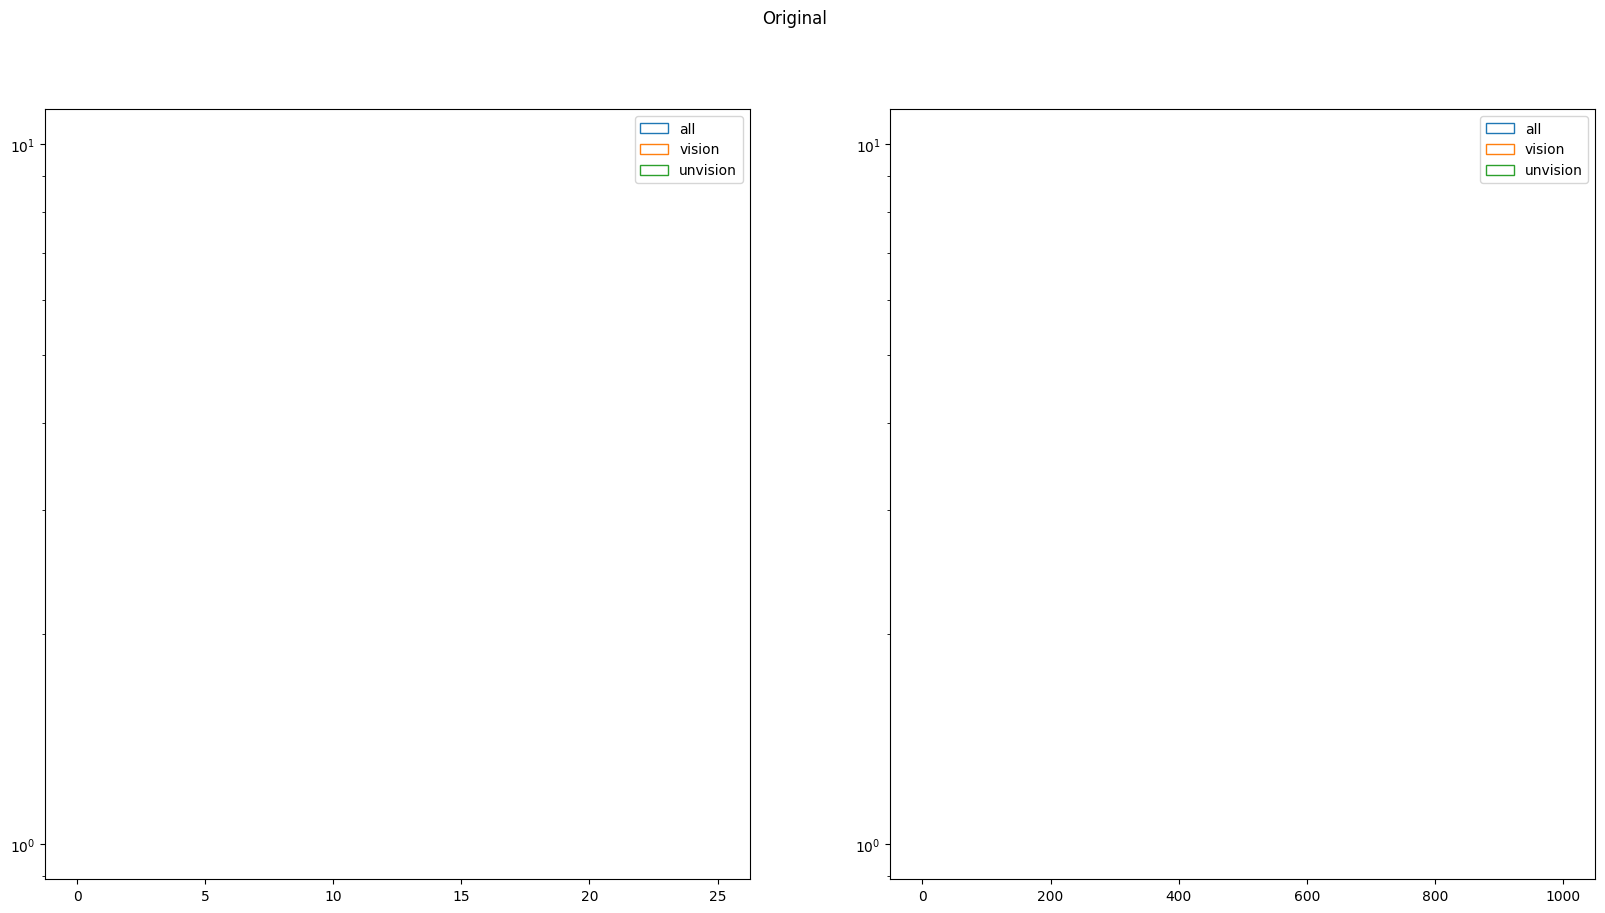

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(20, 10))
fig.suptitle('Original')
ax[0].hist(original_mse_all, log=True, bins=100, density=True, range= (0,25), histtype='step', label='all')
# plt.show()
ax[0].hist(original_mse_vision, log=True, bins=100, density=True, range= (0,25), histtype='step', label='vision')
# plt.show()
ax[0].hist(original_mse_unvision, log=True, bins=100, density=True, range= (0,25), histtype='step', label='unvision')
ax[0].legend()

ax[1].hist(original_mse_all_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='all')
ax[1].hist(original_mse_vision_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='vision')
ax[1].hist(original_mse_unvision_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='unvision')
ax[1].legend()
plt.show()


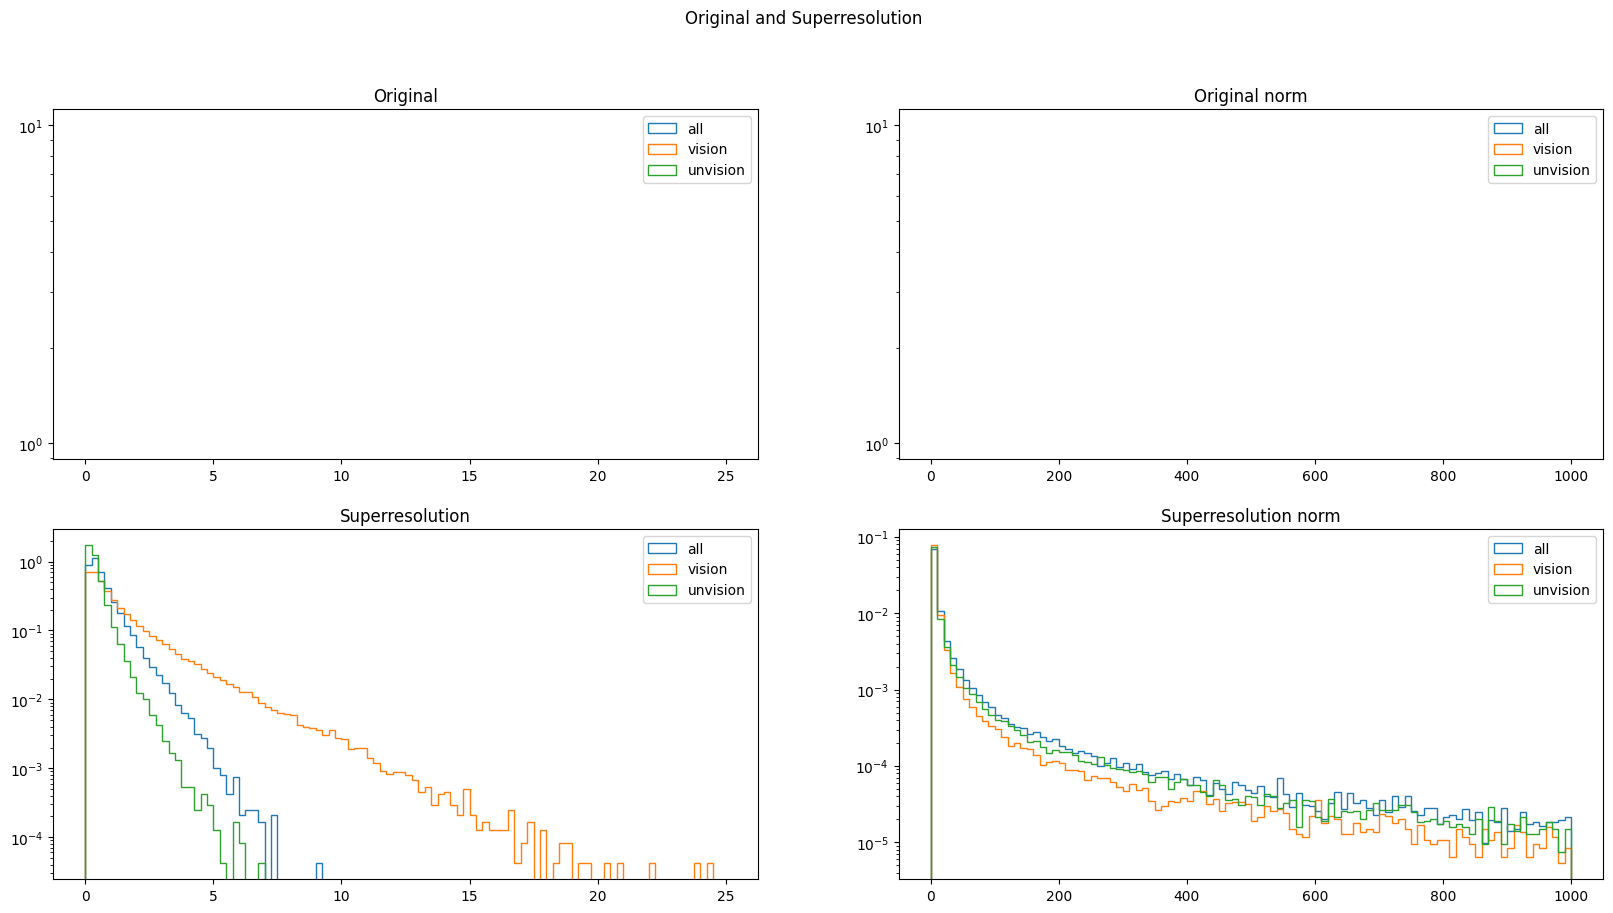

In [ ]:
fig, ax = plt.subplots(2,2, figsize=(20, 10))
fig.suptitle('Original and Superresolution')
ax[0,0].hist(original_mse_all, log=True, bins=100, density=True, range= (0,25), histtype='step', label='all')
# plt.show()
ax[0,0].hist(original_mse_vision, log=True, bins=100, density=True, range= (0,25), histtype='step', label='vision')
# plt.show()
ax[0,0].hist(original_mse_unvision, log=True, bins=100, density=True, range= (0,25), histtype='step', label='unvision')
ax[0,0].legend()

ax[0,1].hist(original_mse_all_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='all')
ax[0,1].hist(original_mse_vision_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='vision')
ax[0,1].hist(original_mse_unvision_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='unvision')
ax[0,1].legend()

ax[1,0].hist(mse_all, log=True, bins=100, density=True, range= (0,25), histtype='step', label='all')
# plt.show()
ax[1,0].hist(mse_vision, log=True, bins=100, density=True, range= (0,25), histtype='step', label='vision')
# plt.show()
ax[1,0].hist(mse_unvision, log=True, bins=100, density=True, range= (0,25), histtype='step', label='unvision')
ax[1,0].legend()

ax[1,1].hist(mse_all_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='all')
ax[1,1].hist(mse_vision_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='vision')
ax[1,1].hist(mse_unvision_norm, log=True, bins=100, density=True, range= (0,1000), histtype='step', label='unvision')
ax[1,1].legend()

# title
ax[0,0].set_title('Original')
ax[0,1].set_title('Original norm')
ax[1,0].set_title('Superresolution')
ax[1,1].set_title('Superresolution norm')
plt.show()

In [81]:
# dt_params_pr = [dt_params_pr[i] for i in indexes_4_det]
# dt_params_rubsov_approximation_pr = [dt_params_rubsov_approximation_pr[i] for i in indexes_4_det]
# reconstruction_data_pr_or = [reconstruction_data_pr_or[i] for i in indexes_4_det]

dt_params_pr_signal = [d[:,3:4] for d in dt_params_pr]
dt_params_pr_time = [d[:,-1:] for d in dt_params_pr]
dt_params_pr_signal_rubsov = [d[:,3:4] for d in dt_params_rubsov_approximation_pr]
dt_params_pr_time_rubsov = [d[:,-1:] for d in dt_params_rubsov_approximation_pr]
dt_params_pr_signal_model_or = [d[:,3:4] for d in reconstruction_data_pr_or]
dt_params_pr_time_model_or = [d[:,4:] for d in reconstruction_data_pr_or]
# dt_params_pr_signal_model_sr = [d[:,3:4] for d in reconstruction_data_pr_sr]
# dt_params_pr_time_model_sr = [d[:,4:] for d in reconstruction_data_pr_sr]

dt_params_pr_sig_time = [np.concatenate([dt_params_pr_signal[i], dt_params_pr_time[i]], axis=1) for i in range(len(dt_params_pr_signal))]
dt_params_pr_sig_time_rubsov = [np.concatenate([dt_params_pr_signal_rubsov[i], dt_params_pr_time_rubsov[i]], axis=1) for i in range(len(dt_params_pr_signal_rubsov))]
dt_params_pr_sig_time_model_or = [np.concatenate([dt_params_pr_signal_model_or[i], dt_params_pr_time_model_or[i]], axis=1) for i in range(len(dt_params_pr_signal_model_or))]
# dt_params_pr_sig_time_model_sr = [np.concatenate([dt_params_pr_signal_model_sr[i], dt_params_pr_time_model_sr[i]], axis=1) for i in range(len(dt_params_pr_signal_model_sr))]
print(dt_params_pr_sig_time[0].shape, dt_params_pr_sig_time_rubsov[0].shape, dt_params_pr_sig_time_model_or[0].shape, dt_params_pr_sig_time_model_sr[0].shape)




(8, 2) (8, 2) (8, 2) (19, 2)


In [82]:
num_det_pr = np.load(os.path.join(path_save, 'pr', 'num_det.npy'))
num_det_photon = np.load(os.path.join(path_save, 'photon', 'num_det.npy'))
num_det_pr.shape, num_det_photon.shape, num_det_pr[:20]

((210315,),
 (210851,),
 array([ 8.,  9., 15.,  9., 13., 10.,  7.,  7.,  9., 11., 12., 19., 10.,
        13., 12.,  7., 12., 12.,  8., 17.]))

In [83]:
recon_loss_pr = np.load(os.path.join(path_save, 'pr', 'recon_loss.npy'))
recon_loss_photon = np.load(os.path.join(path_save, 'photon', 'recon_loss.npy'))
recon_loss_pr.shape, recon_loss_photon.shape, recon_loss_pr[:20]

((210315,),
 (210851,),
 array([0.00090756, 0.00095764, 0.00150498, 0.00074701, 0.0009131 ,
        0.00225859, 0.00560411, 0.0034145 , 0.00097191, 0.01965867,
        0.00854211, 0.00240549, 0.00226458, 0.00677564, 0.00608478,
        0.00147268, 0.00128959, 0.00386558, 0.00149079, 0.00311781]))

In [84]:
mean_losses_pr = {}
mean_losses_ph = {}
std_losses_pr = {}
std_losses_ph = {}

for d, errors_dict in losses_dict_pr.items():
    mean_losses_pr[d] = {}
    std_losses_pr[d] = {}
    for num_det, errors in errors_dict.items():
        errors = np.array(errors)
        mean_losses_pr[d][num_det] = errors.mean(axis=0)
        std_losses_pr[d][num_det] = errors.std(axis=0)

# for d, errors_dict in losses_dict_ph.items():
#     mean_losses_ph[d] = {}
#     std_losses_ph[d] = {}
#     for num_det, errors in errors_dict.items():
#         errors = np.array(errors)
#         mean_losses_ph[d][num_det] = errors.mean(axis=0)
#         std_losses_ph[d][num_det] = errors.std(axis=0)

In [86]:
def error_recon(x, label):
    # shape x [num_det, chanals]
    return np.sqrt(np.sum((x - label)**2, axis=0))
# protons_datasets = [reconstruction_data_pr, dt_params_rubsov_approximation_pr]
# photons_datasets = [reconstruction_data_photon, dt_params_rubsov_approximation_ph]

protons_datasets = [dt_params_pr_sig_time_model_or, dt_params_pr_sig_time_rubsov]
# photons_datasets = [dt_params_ph_sig_time_model, dt_params_ph_sig_time_rubsov]

target_datasets_pr = dt_params_pr_sig_time
# target_datasets_ph = dt_params_ph_sig_time
print([len(dt) for dt in protons_datasets], len(target_datasets_pr))
losses_dict_pr = {}
losses_dict_ph = {}
for j, d in enumerate(protons_datasets):
    losses_dict_pr[j] = {}
    losses_dict_ph[j] = {}
for i in tqdm(range(len(dt_params_pr_sig_time_model_or))):
    for j, d in enumerate(protons_datasets):
        if len(target_datasets_pr[i]) != len(d[i]):
            raise ValueError(f'len(target_datasets_pr[i]) != len(d[i])')
        num_det = len(target_datasets_pr[i])
        error = error_recon(d[i], target_datasets_pr[i])
        if num_det not in losses_dict_pr[j]:
            losses_dict_pr[j][num_det] = []
        losses_dict_pr[j][num_det].append(error)
# for i in tqdm(range(len(reconstruction_data_photon))):
#     for j, d in enumerate(photons_datasets):
#         if len(target_datasets_ph[i]) != len(d[i]):
#             raise ValueError(f'len(target_datasets_ph[i]) != len(d[i])')
#         num_det = len(target_datasets_ph[i])
#         error = error_recon(d[i], target_datasets_ph[i])
#         if num_det not in losses_dict_ph[j]:
#             losses_dict_ph[j][num_det] = []
#         losses_dict_ph[j][num_det].append(error)

[210315, 210315] 210315


  0%|          | 0/210315 [00:00<?, ?it/s]

[ 1  3  5  7  8 12 14 15 19 20 22 23 25 27 28 31 32] [19 10 13 12 17 16 15 18 14 21  9 23 24 25 20 22 11 27 29 32 26 31 28  8
  7 30 33  6 34 37 35 38 36 39  5]
(14,) (14,) Geometry-conditioned VAE
(14,) (14,) Geometry-conditioned VAE
[ 1  3  5  7  8 12 14 15 19 20 22 23 25 27 28 31 32] [19 10 13 12 17 16 15 18 14 21  9 23 24 25 20 22 11 27 29 32 26 31 28  8
  7 30 33  6 34 37 35 38 36 39  5]
(14,) (14,) Standard reconstruction
(14,) (14,) Standard reconstruction


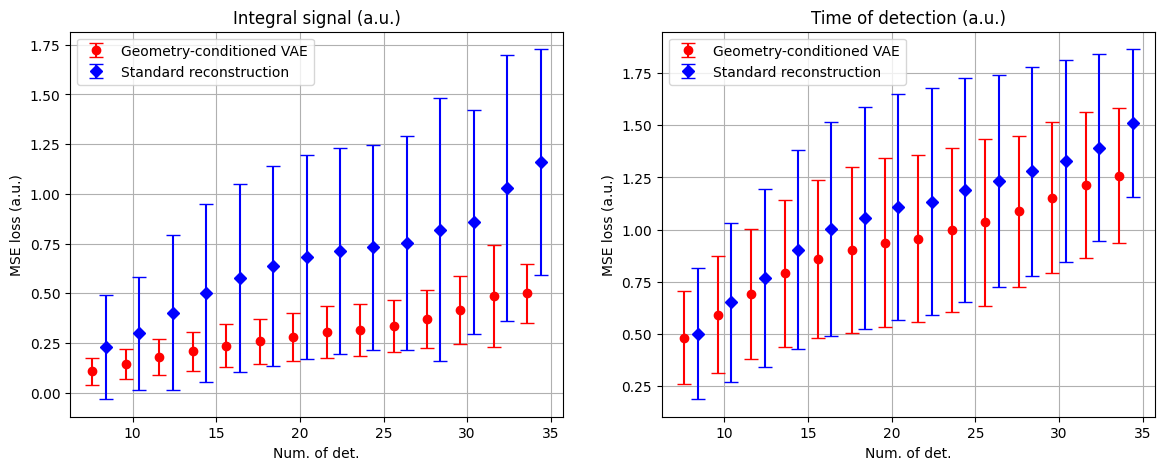

In [88]:
fig, ax = plt.subplots(1,2, figsize=(14, 5))
y_lim = [3,0.4,3]
names = ['Integral signal (a.u.)', 'Time of detection (a.u.)']
names_datasets = ['Geometry-conditioned VAE', 'Geometry-conditioned VAE (SR)', 'Standard reconstruction']
colors = ['r', 'g', 'b']
simbols = ['o', 's', 'D']
st =7
fn=35
# sorted(mean_losses_pr)
for d in mean_losses_pr.keys():
    if d==1:
        continue
    # mean_losses_pr[j] - словарь с коль-вом сработавших детекторов и ошибкой поканальной
    num_det_list = np.array(list(mean_losses_pr[d].keys()))
    mean_lists = np.array(list(mean_losses_pr[d].values()))
    std_lists = np.array(list(std_losses_pr[d].values()))

    index = np.where(num_det_list % 2 == 0)[0]
    print(index, num_det_list)

    num_det_list = num_det_list[index]
    mean_lists = mean_lists[index]
    std_lists = std_lists[index]

    index = np.where((num_det_list>st) & (num_det_list<fn))[0]
    num_det_list = num_det_list[index]
    mean_lists = mean_lists[index]
    std_lists = std_lists[index]
    for i in range(2):
        # ax[i].plot(num_det_list, mean_lists[:,i+3], label=f'{d} pr')
        # ax[i].plot(num_det_list, mean_lists[:,i+3] + std_lists[:,i+3], label=f'{d} pr+ std')
        # ax[i].plot(num_det_list, mean_lists[:,i+3] - std_lists[:,i+3], label=f'{d} pr-std')
        print(mean_lists[:,i].shape, std_lists[:,i].shape, names_datasets[d])
        ax[i].errorbar(num_det_list + 0.4*(d-1), mean_lists[:,i], yerr=std_lists[:,i],
                       marker=simbols[d], color=colors[d], linestyle='none',capsize = 5, label=names_datasets[d])
        ax[i].legend()
        # ax[i].set_ylim(0, y_lim[i])
        ax[i].set_xlabel('Num. of det.')
        ax[i].set_ylabel('MSE loss (a.u.)')
        ax[i].set_title(names[i])
        # ax[i].set_ylim(0, y_lim[i])
# fig.suptitle("Protons", fontsize=16)
ax[0].grid()
ax[1].grid()
plt.show()

In [45]:
dt_params_pr = [dt_params_pr[i] for i in indexes_4_det]
dt_params_rubsov_approximation_pr = [dt_params_rubsov_approximation_pr[i] for i in indexes_4_det]
reconstruction_data_pr_or = [reconstruction_data_pr_or[i] for i in indexes_4_det]

dt_params_pr_signal = [d[:,3:4] for d in dt_params_pr]
dt_params_pr_time = [d[:,-1:] for d in dt_params_pr]
dt_params_pr_signal_rubsov = [d[:,3:4] for d in dt_params_rubsov_approximation_pr]
dt_params_pr_time_rubsov = [d[:,-1:] for d in dt_params_rubsov_approximation_pr]
dt_params_pr_signal_model_or = [d[:,3:4] for d in reconstruction_data_pr_or]
dt_params_pr_time_model_or = [d[:,4:] for d in reconstruction_data_pr_or]
dt_params_pr_signal_model_sr = [d[:,3:4] for d in reconstruction_data_pr_sr]
dt_params_pr_time_model_sr = [d[:,4:] for d in reconstruction_data_pr_sr]

dt_params_pr_sig_time = [np.concatenate([dt_params_pr_signal[i], dt_params_pr_time[i]], axis=1) for i in range(len(dt_params_pr_signal))]
dt_params_pr_sig_time_rubsov = [np.concatenate([dt_params_pr_signal_rubsov[i], dt_params_pr_time_rubsov[i]], axis=1) for i in range(len(dt_params_pr_signal_rubsov))]
dt_params_pr_sig_time_model_or = [np.concatenate([dt_params_pr_signal_model_or[i], dt_params_pr_time_model_or[i]], axis=1) for i in range(len(dt_params_pr_signal_model_or))]
dt_params_pr_sig_time_model_sr = [np.concatenate([dt_params_pr_signal_model_sr[i], dt_params_pr_time_model_sr[i]], axis=1) for i in range(len(dt_params_pr_signal_model_sr))]
print(dt_params_pr_sig_time[0].shape, dt_params_pr_sig_time_rubsov[0].shape, dt_params_pr_sig_time_model_or[0].shape, dt_params_pr_sig_time_model_sr[0].shape)







(19, 2) (19, 2) (19, 2) (19, 2)


In [42]:
# dt_params_ph_signal = [d[:,3:4] for d in dt_params_ph]
# dt_params_ph_time = [d[:,-1:] for d in dt_params_ph]
# dt_params_ph_signal_rubsov = [d[:,3:4] for d in dt_params_rubsov_approximation_ph]
# dt_params_ph_time_rubsov = [d[:,-1:] for d in dt_params_rubsov_approximation_ph]
# dt_params_ph_signal_model_or = [d[:,3:4] for d in reconstruction_data_photon]
# dt_params_ph_time_model_or = [d[:,4:] for d in reconstruction_data_photon]
# dt_params_ph_signal_model_sr = [d[:,3:4] for d in reconstruction_data_photon_sr]
# dt_params_ph_time_model_sr = [d[:,4:] for d in reconstruction_data_photon_sr]

# dt_params_ph_sig_time = [np.concatenate([dt_params_ph_signal[i], dt_params_ph_time[i]], axis=1) for i in range(len(dt_params_ph_signal))]
# dt_params_ph_sig_time_rubsov = [np.concatenate([dt_params_ph_signal_rubsov[i], dt_params_ph_time_rubsov[i]], axis=1) for i in range(len(dt_params_ph_signal_rubsov))]
# dt_params_ph_sig_time_model_or = [np.concatenate([dt_params_ph_signal_model_or[i], dt_params_ph_time_model_or[i]], axis=1) for i in range(len(dt_params_ph_signal_model_or))]
# dt_params_ph_sig_time_model_sr = [np.concatenate([dt_params_ph_signal_model_sr[i], dt_params_ph_time_model_sr[i]], axis=1) for i in range(len(dt_params_ph_signal_model_sr))]
# print(dt_params_ph_sig_time[0].shape, dt_params_ph_sig_time_rubsov[0].shape, dt_params_ph_sig_time_model_or[0].shape, dt_params_ph_sig_time_model_sr[0].shape)





In [46]:
num_det_pr = np.load(os.path.join(path_save, 'pr', 'num_det.npy'))
num_det_photon = np.load(os.path.join(path_save, 'photon', 'num_det.npy'))
num_det_pr.shape, num_det_photon.shape, num_det_pr[:20]

((210315,),
 (210851,),
 array([ 8.,  9., 15.,  9., 13., 10.,  7.,  7.,  9., 11., 12., 19., 10.,
        13., 12.,  7., 12., 12.,  8., 17.]))

In [47]:
recon_loss_pr = np.load(os.path.join(path_save, 'pr', 'recon_loss.npy'))
recon_loss_photon = np.load(os.path.join(path_save, 'photon', 'recon_loss.npy'))
recon_loss_pr.shape, recon_loss_photon.shape, recon_loss_pr[:20]

((210315,),
 (210851,),
 array([0.00090756, 0.00095764, 0.00150498, 0.00074701, 0.0009131 ,
        0.00225859, 0.00560411, 0.0034145 , 0.00097191, 0.01965867,
        0.00854211, 0.00240549, 0.00226458, 0.00677564, 0.00608478,
        0.00147268, 0.00128959, 0.00386558, 0.00149079, 0.00311781]))

In [48]:
def error_recon(x, label):
    # shape x [num_det, chanals]
    return np.sqrt(np.sum((x - label)**2, axis=0))
# protons_datasets = [reconstruction_data_pr, dt_params_rubsov_approximation_pr]
# photons_datasets = [reconstruction_data_photon, dt_params_rubsov_approximation_ph]

protons_datasets = [dt_params_pr_sig_time_model_or, dt_params_pr_sig_time_model_sr, dt_params_pr_sig_time_rubsov]
# photons_datasets = [dt_params_ph_sig_time_model, dt_params_ph_sig_time_rubsov]

target_datasets_pr = dt_params_pr_sig_time
# target_datasets_ph = dt_params_ph_sig_time
print([len(dt) for dt in protons_datasets], len(target_datasets_pr))
losses_dict_pr = {}
losses_dict_ph = {}
for j, d in enumerate(protons_datasets):
    losses_dict_pr[j] = {}
    losses_dict_ph[j] = {}
for i in tqdm(range(len(dt_params_pr_sig_time_model_or))):
    for j, d in enumerate(protons_datasets):
        if len(target_datasets_pr[i]) != len(d[i]):
            raise ValueError(f'len(target_datasets_pr[i]) != len(d[i])')
        num_det = len(target_datasets_pr[i])
        error = error_recon(d[i], target_datasets_pr[i])
        if num_det not in losses_dict_pr[j]:
            losses_dict_pr[j][num_det] = []
        losses_dict_pr[j][num_det].append(error)
# for i in tqdm(range(len(reconstruction_data_photon))):
#     for j, d in enumerate(photons_datasets):
#         if len(target_datasets_ph[i]) != len(d[i]):
#             raise ValueError(f'len(target_datasets_ph[i]) != len(d[i])')
#         num_det = len(target_datasets_ph[i])
#         error = error_recon(d[i], target_datasets_ph[i])
#         if num_det not in losses_dict_ph[j]:
#             losses_dict_ph[j][num_det] = []
#         losses_dict_ph[j][num_det].append(error)

[96074, 96074, 96074] 96074


  0%|          | 0/96074 [00:00<?, ?it/s]

In [49]:
mean_losses_pr = {}
mean_losses_ph = {}
std_losses_pr = {}
std_losses_ph = {}

for d, errors_dict in losses_dict_pr.items():
    mean_losses_pr[d] = {}
    std_losses_pr[d] = {}
    for num_det, errors in errors_dict.items():
        errors = np.array(errors)
        mean_losses_pr[d][num_det] = errors.mean(axis=0)
        std_losses_pr[d][num_det] = errors.std(axis=0)

# for d, errors_dict in losses_dict_ph.items():
#     mean_losses_ph[d] = {}
#     std_losses_ph[d] = {}
#     for num_det, errors in errors_dict.items():
#         errors = np.array(errors)
#         mean_losses_ph[d][num_det] = errors.mean(axis=0)
#         std_losses_ph[d][num_det] = errors.std(axis=0)


In [50]:
mean_losses_pr, mean_losses_pr.keys()

({0: {19: array([0.27015603, 0.92637753], dtype=float32),
   10: array([0.1430701 , 0.59342945], dtype=float32),
   13: array([0.19273171, 0.7475709 ], dtype=float32),
   12: array([0.17913973, 0.69076097], dtype=float32),
   17: array([0.24829614, 0.8870879 ], dtype=float32),
   16: array([0.23758374, 0.86034864], dtype=float32),
   15: array([0.22404791, 0.8276704 ], dtype=float32),
   18: array([0.2584522, 0.9033264], dtype=float32),
   14: array([0.2084721, 0.7904108], dtype=float32),
   21: array([0.2911596, 0.9524169], dtype=float32),
   9: array([0.1303975 , 0.54371446], dtype=float32),
   23: array([0.30793518, 0.9834985 ], dtype=float32),
   24: array([0.31613672, 0.99738604], dtype=float32),
   25: array([0.32760942, 1.0109974 ], dtype=float32),
   20: array([0.28092948, 0.93828905], dtype=float32),
   22: array([0.30330196, 0.9560732 ], dtype=float32),
   11: array([0.16208333, 0.64501643], dtype=float32),
   27: array([0.3575066, 1.0452446], dtype=float32),
   29: array([0.

In [51]:
mean_losses_pr[2]

{19: array([0.6567604, 1.0901918], dtype=float32),
 10: array([0.29916298, 0.6514081 ], dtype=float32),
 13: array([0.44729128, 0.84111893], dtype=float32),
 12: array([0.40278265, 0.767961  ], dtype=float32),
 17: array([0.5997389, 1.0343152], dtype=float32),
 16: array([0.5778867, 1.0018605], dtype=float32),
 15: array([0.5442296, 0.9530662], dtype=float32),
 18: array([0.6376607, 1.0561877], dtype=float32),
 14: array([0.500767 , 0.9044365], dtype=float32),
 21: array([0.7063274, 1.1245406], dtype=float32),
 9: array([0.2699904, 0.5788096], dtype=float32),
 23: array([0.71125764, 1.1561435 ], dtype=float32),
 24: array([0.7307876, 1.1908277], dtype=float32),
 25: array([0.7318445, 1.2113595], dtype=float32),
 20: array([0.6824823, 1.1087385], dtype=float32),
 22: array([0.7126906, 1.1330589], dtype=float32),
 11: array([0.3610029, 0.7147218], dtype=float32),
 27: array([0.7690586, 1.2384053], dtype=float32),
 29: array([0.7669514, 1.3344784], dtype=float32),
 32: array([1.031249 , 1

In [52]:
mean_losses_pr[0]

{19: array([0.27015603, 0.92637753], dtype=float32),
 10: array([0.1430701 , 0.59342945], dtype=float32),
 13: array([0.19273171, 0.7475709 ], dtype=float32),
 12: array([0.17913973, 0.69076097], dtype=float32),
 17: array([0.24829614, 0.8870879 ], dtype=float32),
 16: array([0.23758374, 0.86034864], dtype=float32),
 15: array([0.22404791, 0.8276704 ], dtype=float32),
 18: array([0.2584522, 0.9033264], dtype=float32),
 14: array([0.2084721, 0.7904108], dtype=float32),
 21: array([0.2911596, 0.9524169], dtype=float32),
 9: array([0.1303975 , 0.54371446], dtype=float32),
 23: array([0.30793518, 0.9834985 ], dtype=float32),
 24: array([0.31613672, 0.99738604], dtype=float32),
 25: array([0.32760942, 1.0109974 ], dtype=float32),
 20: array([0.28092948, 0.93828905], dtype=float32),
 22: array([0.30330196, 0.9560732 ], dtype=float32),
 11: array([0.16208333, 0.64501643], dtype=float32),
 27: array([0.3575066, 1.0452446], dtype=float32),
 29: array([0.38845456, 1.1021541 ], dtype=float32),
 3

[ 1  3  5  7  8 12 14 15 19 20 22 23 25 27 28 31 32] [19 10 13 12 17 16 15 18 14 21  9 23 24 25 20 22 11 27 29 32 26 31 28  8
  7 30 33  6 34 37 35 38 36 39  5]
(14,) (14,) Geometry-conditioned VAE
(14,) (14,) Geometry-conditioned VAE
[ 1  3  5  7  8 12 14 15 19 20 22 23 25 27 28 31 32] [19 10 13 12 17 16 15 18 14 21  9 23 24 25 20 22 11 27 29 32 26 31 28  8
  7 30 33  6 34 37 35 38 36 39  5]
(14,) (14,) Geometry-conditioned VAE (SR)
(14,) (14,) Geometry-conditioned VAE (SR)
[ 1  3  5  7  8 12 14 15 19 20 22 23 25 27 28 31 32] [19 10 13 12 17 16 15 18 14 21  9 23 24 25 20 22 11 27 29 32 26 31 28  8
  7 30 33  6 34 37 35 38 36 39  5]
(14,) (14,) Standard reconstruction
(14,) (14,) Standard reconstruction


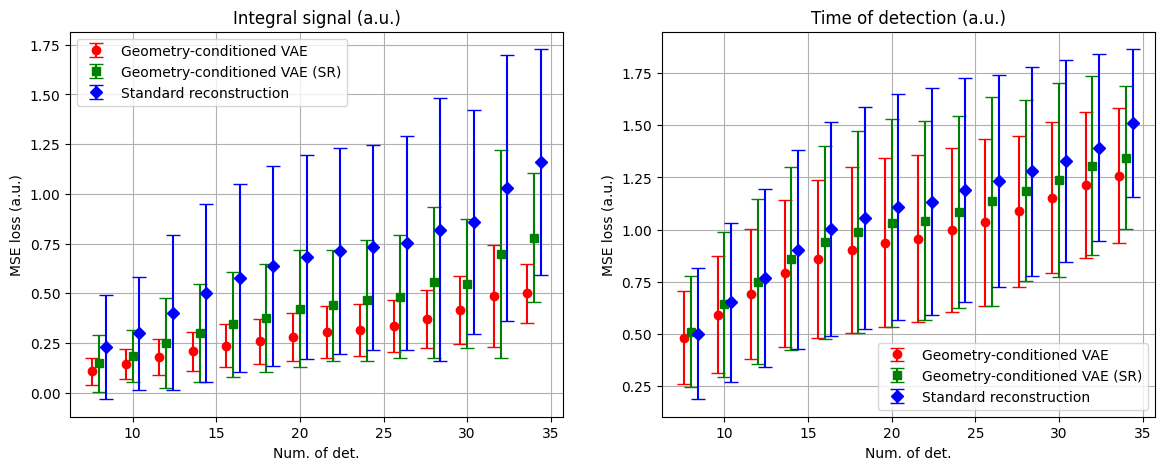

In [56]:
fig, ax = plt.subplots(1,2, figsize=(14, 5))
y_lim = [3,0.4,3]
names = ['Integral signal (a.u.)', 'Time of detection (a.u.)']
names_datasets = ['Geometry-conditioned VAE', 'Geometry-conditioned VAE (SR)', 'Standard reconstruction']
colors = ['r', 'g', 'b']
simbols = ['o', 's', 'D']
st =7
fn=35
# sorted(mean_losses_pr)
for d in mean_losses_pr.keys():
    # mean_losses_pr[j] - словарь с коль-вом сработавших детекторов и ошибкой поканальной
    num_det_list = np.array(list(mean_losses_pr[d].keys()))
    mean_lists = np.array(list(mean_losses_pr[d].values()))
    std_lists = np.array(list(std_losses_pr[d].values()))

    index = np.where(num_det_list % 2 == 0)[0]
    print(index, num_det_list)

    num_det_list = num_det_list[index]
    mean_lists = mean_lists[index]
    std_lists = std_lists[index]

    index = np.where((num_det_list>st) & (num_det_list<fn))[0]
    num_det_list = num_det_list[index]
    mean_lists = mean_lists[index]
    std_lists = std_lists[index]
    for i in range(2):
        # ax[i].plot(num_det_list, mean_lists[:,i+3], label=f'{d} pr')
        # ax[i].plot(num_det_list, mean_lists[:,i+3] + std_lists[:,i+3], label=f'{d} pr+ std')
        # ax[i].plot(num_det_list, mean_lists[:,i+3] - std_lists[:,i+3], label=f'{d} pr-std')
        print(mean_lists[:,i].shape, std_lists[:,i].shape, names_datasets[d])
        ax[i].errorbar(num_det_list + 0.4*(d-1), mean_lists[:,i], yerr=std_lists[:,i],
                       marker=simbols[d], color=colors[d], linestyle='none',capsize = 5, label=names_datasets[d])
        ax[i].legend()
        # ax[i].set_ylim(0, y_lim[i])
        ax[i].set_xlabel('Num. of det.')
        ax[i].set_ylabel('MSE loss (a.u.)')
        ax[i].set_title(names[i])
        # ax[i].set_ylim(0, y_lim[i])
# fig.suptitle("Protons", fontsize=16)
ax[0].grid()
ax[1].grid()
plt.show()


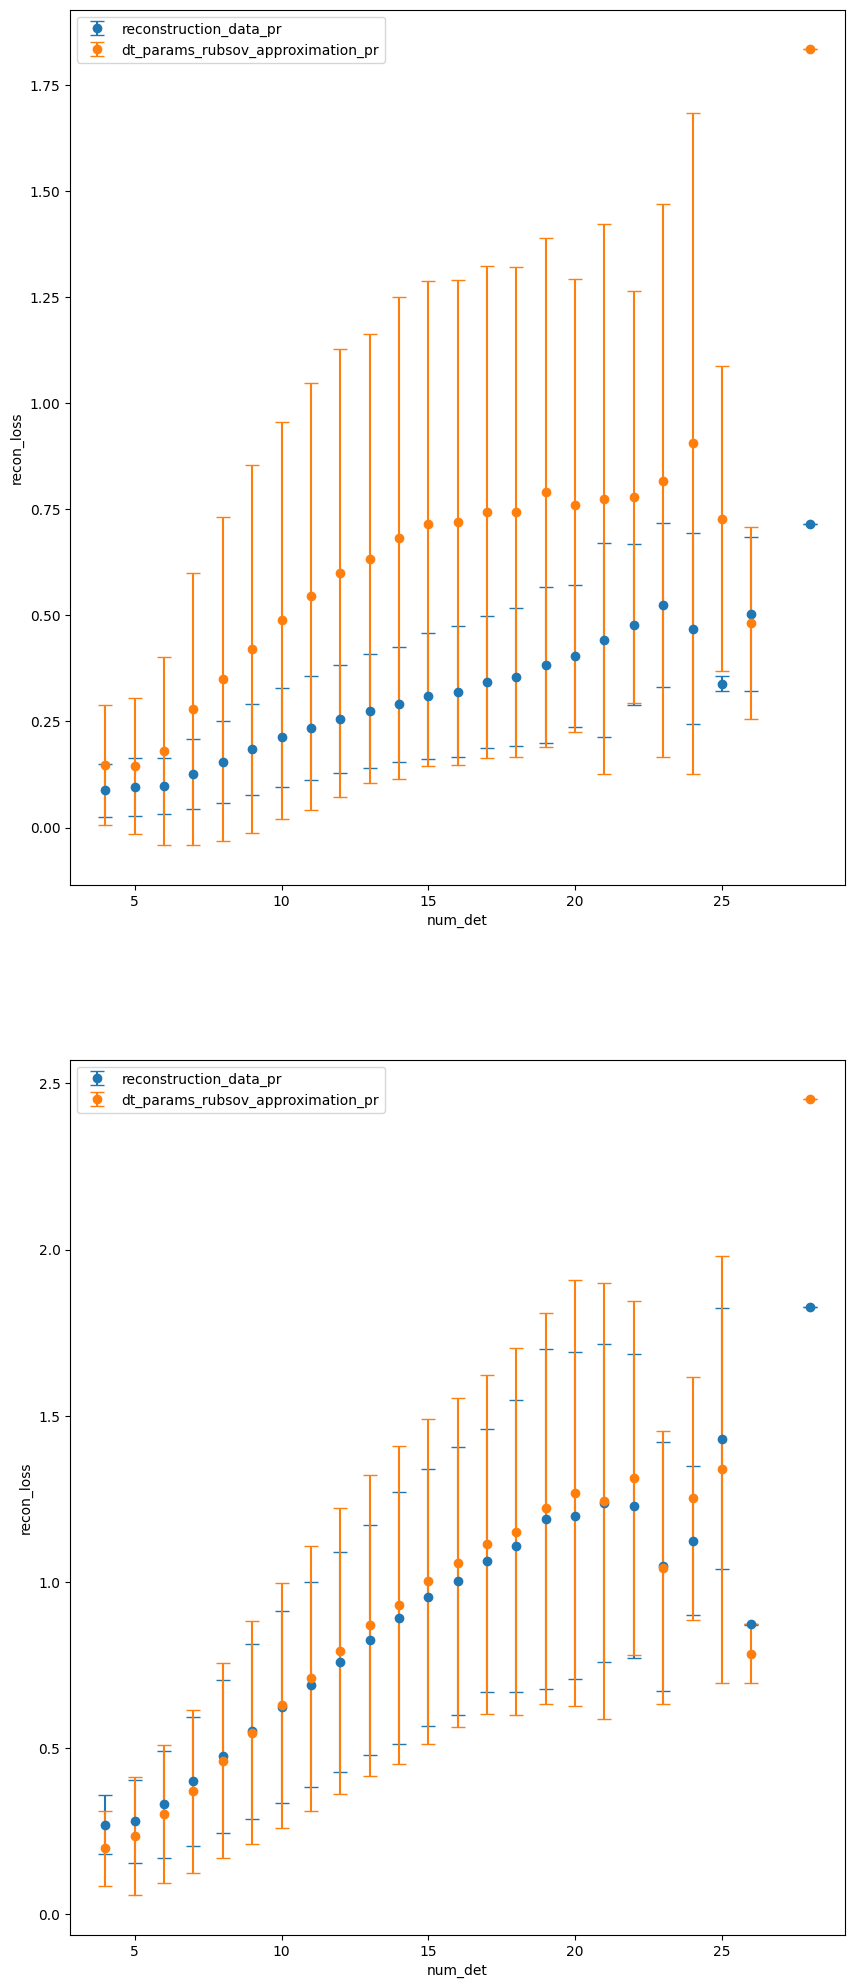

In [ ]:
fig, ax = plt.subplots(2,1, figsize=(10, 25))
y_lim = [3,0.4,3]
names_datasets = ['reconstruction_data_pr', 'dt_params_rubsov_approximation_pr']
for d in mean_losses_ph.keys():
    # mean_losses_pr[j] - словарь с коль-вом сработавших детекторов и ошибкой поканальной
    num_det_list = list(mean_losses_ph[d].keys())
    mean_lists = np.array(list(mean_losses_ph[d].values()))
    std_lists = np.array(list(std_losses_ph[d].values()))
    for i in range(2):
        # ax[i].plot(num_det_list, mean_lists[:,i+3], label=f'{d} pr')
        # ax[i].plot(num_det_list, mean_lists[:,i+3] + std_lists[:,i+3], label=f'{d} pr+ std')
        # ax[i].plot(num_det_list, mean_lists[:,i+3] - std_lists[:,i+3], label=f'{d} pr-std')
        ax[i].errorbar(num_det_list, mean_lists[:,i], yerr=std_lists[:,i],
                       marker='o', linestyle='none',capsize = 5, label=names_datasets[d])
        ax[i].legend()
        ax[i].set_xlabel('num_det')
        ax[i].set_ylabel('recon_loss')
        # ax[i].set_ylim(0, y_lim[i])
plt.show()


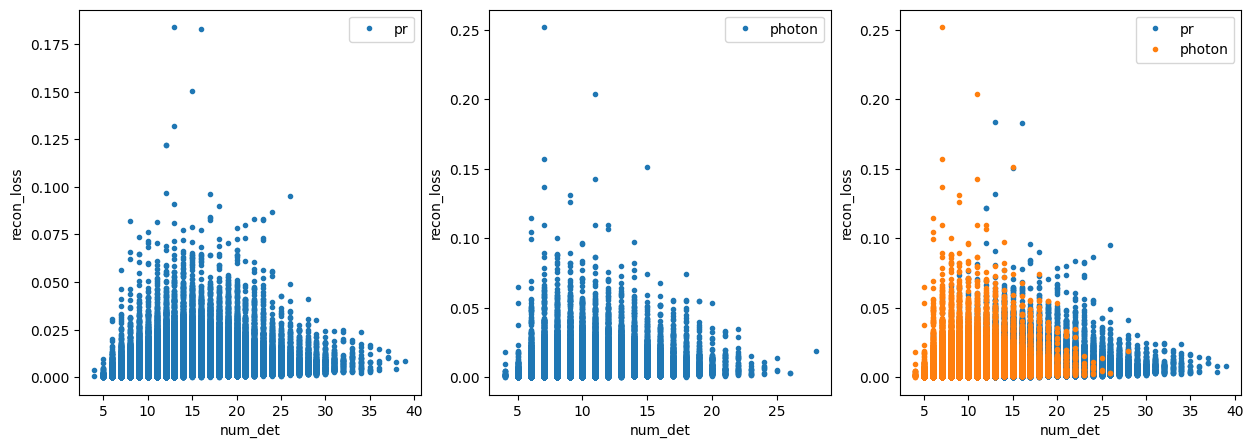

In [8]:
fig, ax = plt.subplots(1,3, figsize=(15, 5))
ax[0].plot(num_det_pr, recon_loss_pr, '.', label='pr')
ax[0].legend()
ax[1].plot(num_det_photon, recon_loss_photon, '.', label='photon')
ax[1].legend()
ax[2].plot(num_det_pr, recon_loss_pr, '.', label='pr')
ax[2].plot(num_det_photon, recon_loss_photon, '.', label='photon')
ax[2].legend()
for i in range(3):
    ax[i].set_xlabel('num_det')
    ax[i].set_ylabel('recon_loss')
plt.show()

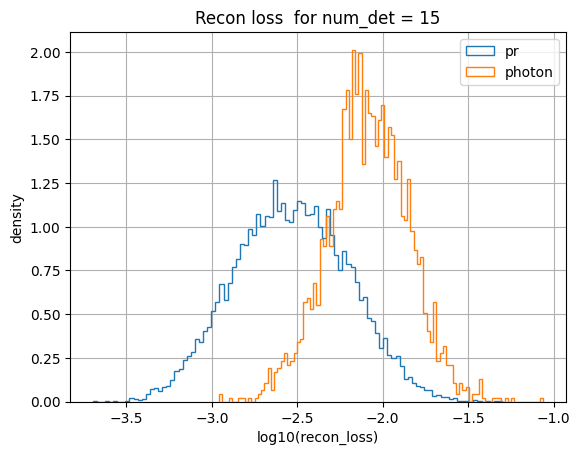

In [42]:
num=15
range_hist = None
plt.hist(np.log10(recon_loss_pr[num_det_pr == num]), density=True, bins=100, label='pr', histtype='step', range=range_hist)
plt.hist(np.log10(recon_loss_photon[num_det_photon == num]), density=True, bins=100, label='photon', histtype='step', range=range_hist)
plt.legend()
plt.title(f'Recon loss  for num_det = {num}')
plt.xlabel('log10(recon_loss)')
plt.ylabel('density')
plt.grid()
plt.show()

In [44]:
embading_pr = np.load(os.path.join(path_save, 'pr', 'embading.npy'))
embading_photon = np.load(os.path.join(path_save, 'photon', 'embading.npy'))
recos_pr = np.load(os.path.join(path_save, 'pr', 'recos.npy'))
recos_photon = np.load(os.path.join(path_save, 'photon', 'recos.npy'))

recos_norming_pr = recos_pr * std_recos + mean_recos
recos_norming_photon = recos_photon * std_recos + mean_recos

embading_pr.shape, embading_photon.shape, recos_pr.shape,




((210315, 6), (210851, 6), (210315, 15))


    recos (num_evs,15):
    0. theta
    1. phi
    2. S_800
    3. E_gamma
    4. d_border, km
    5. chi2/ndof for joint fit
    6. Linsley front curvature
    7. Area-over-peak (AOP) 1200
    8. AOP slope
    9. S_b parameter, b=2.5 (arXiv:1104.3399, arXiv:1305.7439)
    10. S_b parameter, b=4.0
    11. sum of all signals in all detectors
    12. asymmetry  of  the  summed signal  at  the  upper  and  lower layers of detectors
    13. total number of peaks in event
    14. number of peaks for the detector with the largest signal

In [45]:
# проверка физической информативности латентного пространства
from catboost import CatBoostRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm
train_latent_pr, test_latent_pr, train_recos_pr, test_recos_pr = train_test_split(embading_pr, recos_pr, test_size=0.2, random_state=42)

info = {}
for i in tqdm(range(recos_pr.shape[1])):
    regressor = CatBoostRegressor(n_estimators=1000, learning_rate=0.01, depth=10, random_seed=42,
        loss_function='RMSE', eval_metric='RMSE', early_stopping_rounds=20)

    regressor.fit(train_latent_pr, train_recos_pr[:,i], eval_set=(test_latent_pr, test_recos_pr[:,i]), use_best_model=True)
    # regressor = MLPRegressor(hidden_layer_sizes=(32,64), max_iter=1000, random_state=42,
    #     early_stopping=True, validation_fraction=0.2, solver='adam')
    # regressor.fit(train_latent_pr, train_recos_pr[:,i])
    score = regressor.score(test_latent_pr, test_recos_pr[:,i])
    info[i] = {'model': regressor, "metric": score}
    


  0%|          | 0/15 [00:00<?, ?it/s]

0:	learn: 1.0537418	test: 1.0512990	best: 1.0512990 (0)	total: 82ms	remaining: 1m 21s
1:	learn: 1.0482431	test: 1.0458413	best: 1.0458413 (1)	total: 105ms	remaining: 52.2s
2:	learn: 1.0427934	test: 1.0404369	best: 1.0404369 (2)	total: 123ms	remaining: 40.8s
3:	learn: 1.0374956	test: 1.0352188	best: 1.0352188 (3)	total: 140ms	remaining: 34.9s
4:	learn: 1.0321928	test: 1.0299676	best: 1.0299676 (4)	total: 157ms	remaining: 31.2s
5:	learn: 1.0269372	test: 1.0247440	best: 1.0247440 (5)	total: 172ms	remaining: 28.6s
6:	learn: 1.0216830	test: 1.0195711	best: 1.0195711 (6)	total: 187ms	remaining: 26.6s
7:	learn: 1.0165258	test: 1.0144621	best: 1.0144621 (7)	total: 203ms	remaining: 25.2s
8:	learn: 1.0114359	test: 1.0094036	best: 1.0094036 (8)	total: 219ms	remaining: 24.1s
9:	learn: 1.0063750	test: 1.0043963	best: 1.0043963 (9)	total: 235ms	remaining: 23.2s
10:	learn: 1.0013480	test: 0.9994050	best: 0.9994050 (10)	total: 250ms	remaining: 22.5s
11:	learn: 0.9963008	test: 0.9943867	best: 0.9943867

In [46]:

feaches_names = """
    0. theta
    1. phi
    2. S_800
    3. E_gamma
    4. d_border, km
    5. chi2/ndof for joint fit
    6. Linsley front curvature
    7. Area-over-peak (AOP) 1200
    8. AOP slope
    9. S_b parameter, b=2.5 (arXiv:1104.3399, arXiv:1305.7439)
    10. S_b parameter, b=4.0
    11. sum of all signals in all detectors
    12. asymmetry  of  the  summed signal  at  the  upper  and  lower layers of detectors
    13. total number of peaks in event
    14. number of peaks for the detector with the largest signal
"""
feaches_names = feaches_names.split('\n')[1:-1]
feaches_names = [i.replace(' ', '') for i in feaches_names]
feaches_names

['0.theta',
 '1.phi',
 '2.S_800',
 '3.E_gamma',
 '4.d_border,km',
 '5.chi2/ndofforjointfit',
 '6.Linsleyfrontcurvature',
 '7.Area-over-peak(AOP)1200',
 '8.AOPslope',
 '9.S_bparameter,b=2.5(arXiv:1104.3399,arXiv:1305.7439)',
 '10.S_bparameter,b=4.0',
 '11.sumofallsignalsinalldetectors',
 '12.asymmetryofthesummedsignalattheupperandlowerlayersofdetectors',
 '13.totalnumberofpeaksinevent',
 '14.numberofpeaksforthedetectorwiththelargestsignal']



In [47]:
fig, ax = plt.subplots(recos_pr.shape[1],1, figsize=(10, recos_pr.shape[1]*10))
for i in range(recos_pr.shape[1]):
    pred = info[i]['model'].predict(test_latent_pr)
    ax[i].scatter(test_recos_pr[:,i], pred, label=f'{i} feature')
    ax[i].plot([test_recos_pr[:,i].min(), test_recos_pr[:,i].min()], [test_recos_pr[:,i].max(), test_recos_pr[:,i].max()], color='k', linestyle='--', label='true')
    ax[i].legend()
    ax[i].set_title(feaches_names[i])
    ax[i].set_xlabel('true')
    ax[i].set_ylabel('pred')
plt.show()

In [ ]:
num =47000
ch_emb = 6
num_ph = 400

part of data 0.01
pr (210315, 6) ph (210851, 6)
(14480, 7)
pr 14456 ph 24
-6.246178657184084 -7.4418741097262755
0.6129654575034467 0.2828394065882752


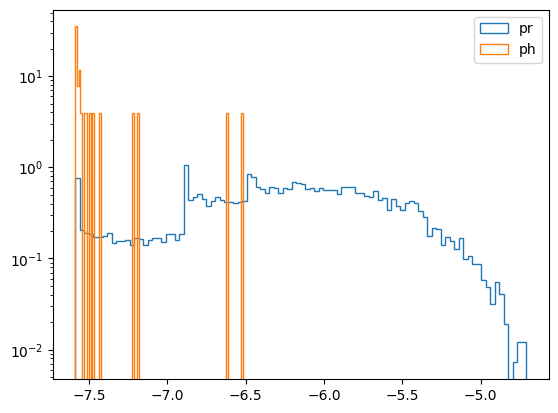

In [72]:

from sklearn.preprocessing import RobustScaler

from sklearn.neighbors import KernelDensity
ch_emb = 6
num =200000
num_ph = 2000
N = 15
bandwidth = 0.3
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

index_pr_N_det = np.where(num_det_pr == N)[0]
index_ph_N_det = np.where(num_det_photon == N)[0]

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,ch_emb]



X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:ch_emb], X[:,ch_emb+1:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())


num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

In [69]:
def show_del_by_score(pr, ph, use_ph=True, n_ph=1, density_ph = None, density_pr = None, th = 0.1):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    fig = plt.subplot()
    plt.hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    plt.hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    plt.axvline(th, color='k', linestyle='--', label=f'th')
    plt.legend()
    plt.show()
    fig, ax = plt.subplots(2,3, figsize=(12, 12))
    ax_1, ax_2, ax_3 = ax[0]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph[::n_ph]], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)

    X_all = np.vstack([X_pr, X_ph[::n_ph]])

    kde = gaussian_kde(X_all.T, )
    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    grid_x, grid_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    density = kde(np.vstack([grid_x.ravel(), grid_y.ravel()]))
    density = density.reshape(grid_x.shape)
    cmap = plt.colormaps['PiYG']
    # (1,0) - плотность для всех точек
    im = ax[0, 2].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[0, 2].set_title('Density (all)')
    fig.colorbar(im, ax=ax[0, 2], label='Density')

    im = ax[1, 2].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[1, 2].set_title('Density (all)')
    fig.colorbar(im, ax=ax[1, 2], label='Density')

    ax_1, ax_2, ax_3 = ax[0]
    ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    pr_index = density_pr<th
    ph_index = density_ph<th
    # print(len(density_pr), len(density_ph))
    # print(pr_index.sum(), ph_index.sum())
    # print(len(X_pr[pr_index, 0]), len(X_ph[ph_index, 0]))
    ax_1, ax_2, ax_3 = ax[1]
    ax_1.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=0.5, alpha=0.3, label='ph')
    
    # ax[1,1].hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    # ax[1,1].hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    # ax[1,1].legend()
    # ax[1,1].set_title('Density (ph and pr)')
    # ax[1,1].grid()
    print('ANOMALY RESULT')
    print(f'pr all : {len(density_pr)}, pr anlomal: {pr_index.sum()}, pr part: {pr_index.sum()/len(density_pr)}')
    print(f'ph all : {len(density_ph)}, ph anlomal: {ph_index.sum()}, ph part: {ph_index.sum()/len(density_ph)}')
    plt.tight_layout()
    plt.show()

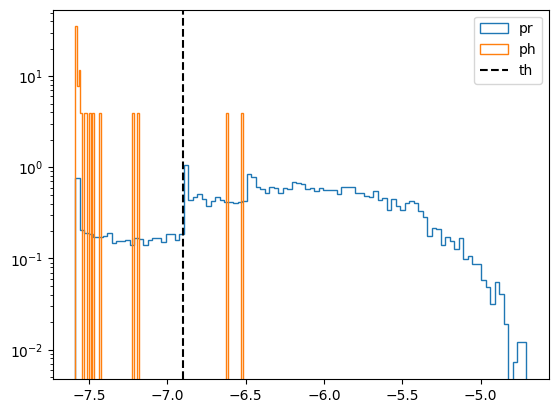

ANOMALY RESULT
pr all : 14456, pr anlomal: 1919, pr part: 0.13274764803541783
ph all : 24, ph anlomal: 22, ph part: 0.9166666666666666


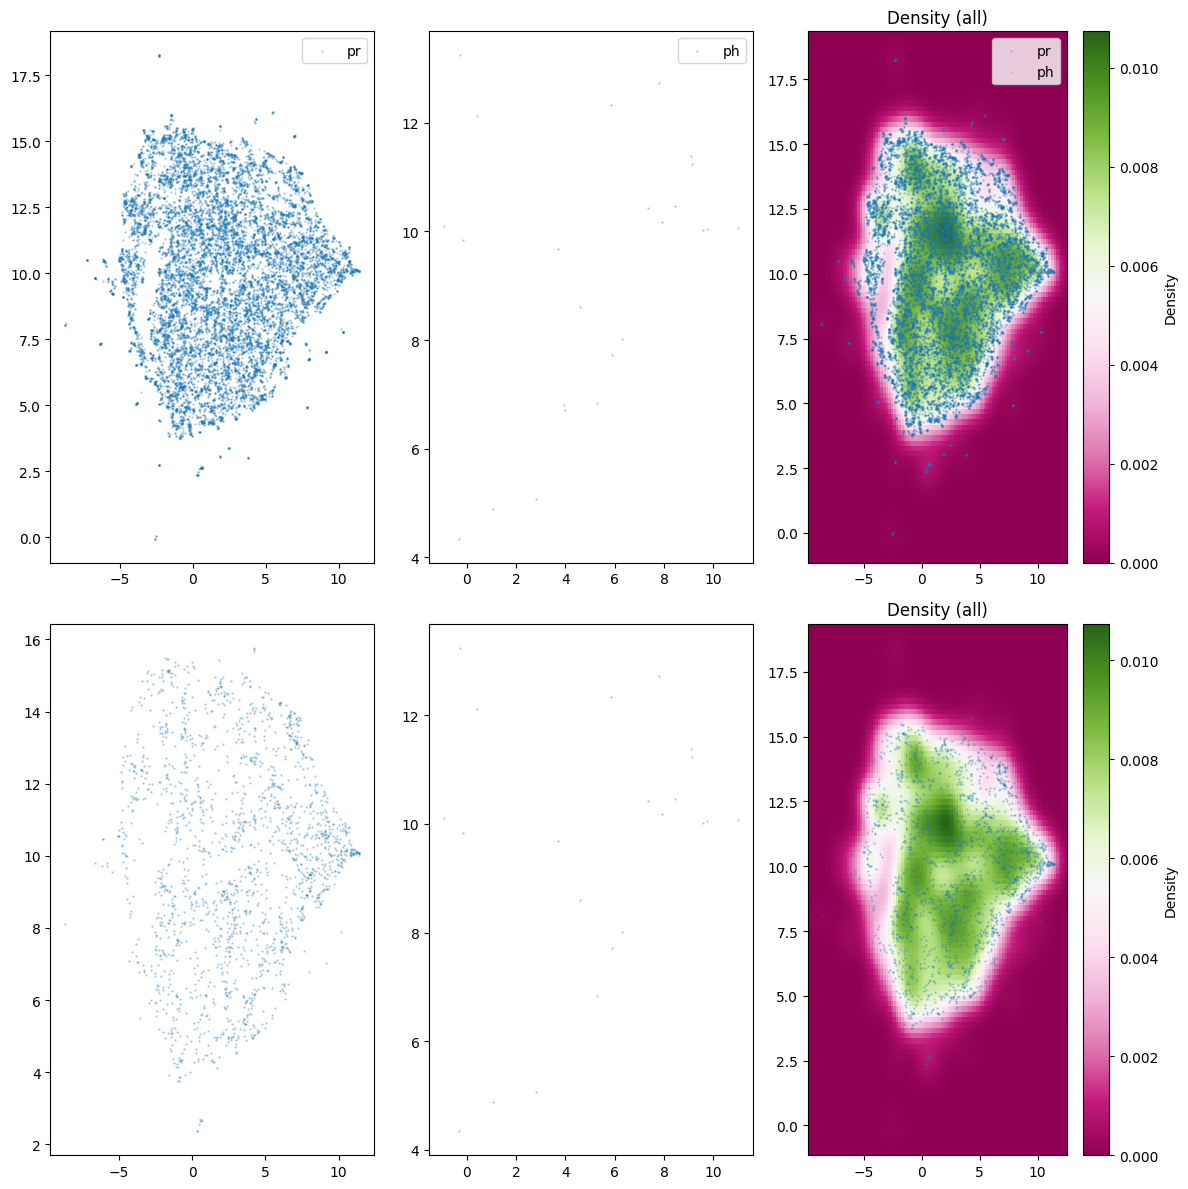

In [75]:
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=-6.9)

In [48]:
# В изначально ненормированных данных val*10^18

# После нормировки 
# 0- это 0
# 1.0 энергия 10^18
# 10.0 энергия 10^19

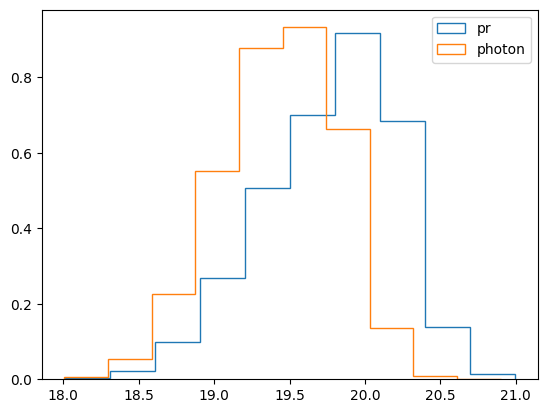

In [49]:
Energy_pr = np.log10(recos_norming_pr[:,3])+18
Energy_photon = np.log10(recos_norming_photon[:,3])+18
plt.hist(Energy_pr,histtype='step',density=True, label='pr')
plt.hist(Energy_photon,histtype='step',density=True, label='photon')
plt.legend()


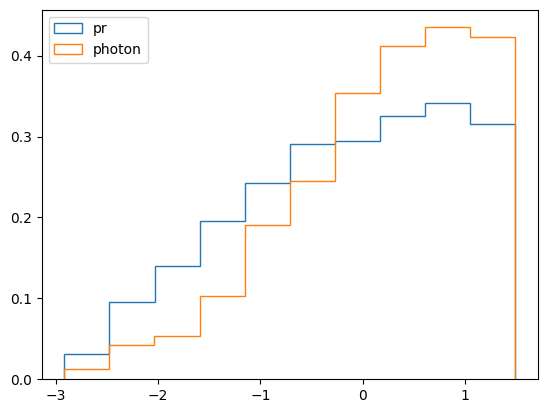

In [50]:
plt.hist(recos_pr[:,0],histtype='step',density=True, label='pr')
plt.hist(recos_photon[:,0],histtype='step',density=True, label='photon')
plt.legend()

In [51]:
def get_metrics(score_samples, score_samples_photon, th):
    FP_index = np.where(score_samples < th)[0]
    TP_index = np.where(score_samples_photon < th)[0]
    FN_index = np.where(score_samples_photon > th)[0]
    TN_index = np.where(score_samples > th)[0]
    part_anomalys_pr = len(FP_index)/len(score_samples)
    part_anomalys_ph = len(TP_index)/len(score_samples_photon)
    recall = len(TP_index) / (len(TP_index) + len(FN_index)+1e-10)
    precision = len(TP_index) / (len(TP_index) + len(FP_index)+1e-10)
    f1 = 2 * precision * recall / (precision + recall+1e-10)
    return recall, precision, f1, part_anomalys_pr, part_anomalys_ph

In [52]:
from sklearn.metrics import roc_curve, auc
from sklearn.neighbors import KernelDensity
def full_test_prob(feaches_pr, feaches_photon,feaches_pr_test = None,n_components=1, range_hist=(-20, 0)):
    fig, axs = plt.subplots(3, 1, figsize=(7, 15))
    # clf = mixture.GaussianMixture(n_components=n_components, covariance_type="full")
    clf = KernelDensity(kernel='gaussian', bandwidth=0.1)
    clf.fit(feaches_pr)
    if feaches_pr_test is None:
        score_samples = clf.score_samples(feaches_pr)
        score_samples_photon = clf.score_samples(feaches_photon)
    else:
        score_samples = clf.score_samples(feaches_pr_test)
        score_samples_photon = clf.score_samples(feaches_photon)
    print(score_samples)
    print(score_samples_photon)
    axs[0].hist(score_samples, bins=100, label='pr', histtype='step', density=True, range=range_hist)
    axs[0].hist(score_samples_photon, bins=100, label='ph', histtype='step', density=True, range=range_hist)
    axs[0].legend()
    axs[0].set_title('hist')
    axs[0].grid()

    recall_list = []    
    precision_list = []
    f1_list = []
    part_anomalys_pr_list = []
    part_anomalys_ph_list = []
    min_score = min(score_samples.min(), score_samples_photon.min())
    max_score = max(score_samples.max(), score_samples_photon.max())
    for th in np.linspace(min_score, max_score, 100):
        recall, precision, f1, part_anomalys_pr, part_anomalys_ph = get_metrics(score_samples, score_samples_photon, th)
        recall_list.append(recall)
        precision_list.append(precision)
        f1_list.append(f1)
        part_anomalys_pr_list.append(part_anomalys_pr)
        part_anomalys_ph_list.append(part_anomalys_ph)
    axs[1].plot(np.linspace(-20, 2, 100), recall_list, label='recall')
    axs[1].plot(np.linspace(-20, 2, 100), precision_list, label='precision')
    axs[1].plot(np.linspace(-20, 2, 100), f1_list, label='f1')
    axs[1].plot(np.linspace(-20, 2, 100), part_anomalys_pr_list, label='part_anomalys_pr')
    axs[1].plot(np.linspace(-20, 2, 100), part_anomalys_ph_list, label='part_anomalys_ph')
    axs[1].legend()
    axs[1].set_title('metrics')
    axs[1].grid()

    #roc curve
    label_pr = np.zeros_like(score_samples)
    label_ph = np.ones_like(score_samples_photon)
    label = np.concatenate((label_pr, label_ph))
    loss = np.concatenate((-score_samples, -score_samples_photon))
    fpr, tpr, thresholds = roc_curve(label, loss)
    auc_ = auc(fpr, tpr)
    axs[2].plot(fpr, tpr)
    axs[2].text(0.5, 0.5, f'auc: {auc_:.2f}', fontsize=12, ha='center', va='center')
    axs[2].set_title(f'roc curve')
    axs[2].grid()
    print(thresholds.min(), thresholds.max())
    plt.show()

    
    

In [53]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest

num =47000
num_ph = 400
print(f'part of data {num_ph/num}')
test_num = 10000
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1), recos_pr[index]], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1), recos_photon[index_ph]], axis=1)

feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)
# label_pr = np.zeros(num)
# label_ph = np.ones(num_ph)
# label = np.concatenate((label_pr, label_ph))
# feaches_pr_test = np.concatenate([embading_pr[-test_num:], num_det_pr[-test_num:].reshape(-1,1), recon_loss_pr[-test_num:].reshape(-1,1)], axis=1)

# feaches_photon_test = np.concatenate([embading_photon[-test_num:], num_det_photon[-test_num:].reshape(-1,1), recon_loss_photon[-test_num:].reshape(-1,1)], axis=1)
# feaches: твой массив shape [N, D]
X = feaches.copy()
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

part of data 0.00851063829787234
pr (210315, 6) ph (210851, 6)
(47400, 23)


In [54]:
# embading, num_det, recon_loss, recos
print(feaches.shape)

(47400, 23)


In [55]:
def show_2d(pr, ph, use_ph=True):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)


    fig, ax = plt.subplots(2,3, figsize=(12, 12))
    ax_1, ax_2, ax_3 = ax[0]
    ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    # tsne = sklearn.manifold.TSNE(n_components=2)
    # if use_ph:
    #     X_tsne = tsne.fit_transform(np.concatenate([pr, ph], axis=0))
    #     X_tsne_pr = X_tsne[:pr.shape[0]]
    #     X_tsne_ph = X_tsne[pr.shape[0]:]
    # else:
    #     X_tsne = tsne.fit_transform(pr)
    #     X_tsne_pr = X_tsne

    # ax_1, ax_2, ax_3 = ax[1]
    # ax_1.scatter(X_tsne_pr[:, 0], X_tsne_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    # ax_2.scatter(X_tsne_ph[:, 0], X_tsne_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    # ax_3.scatter(X_tsne_pr[:, 0], X_tsne_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    # ax_3.scatter(X_tsne_ph[:, 0], X_tsne_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    # ax_1.legend()
    # ax_2.legend()
    # ax_3.legend()
    plt.show()

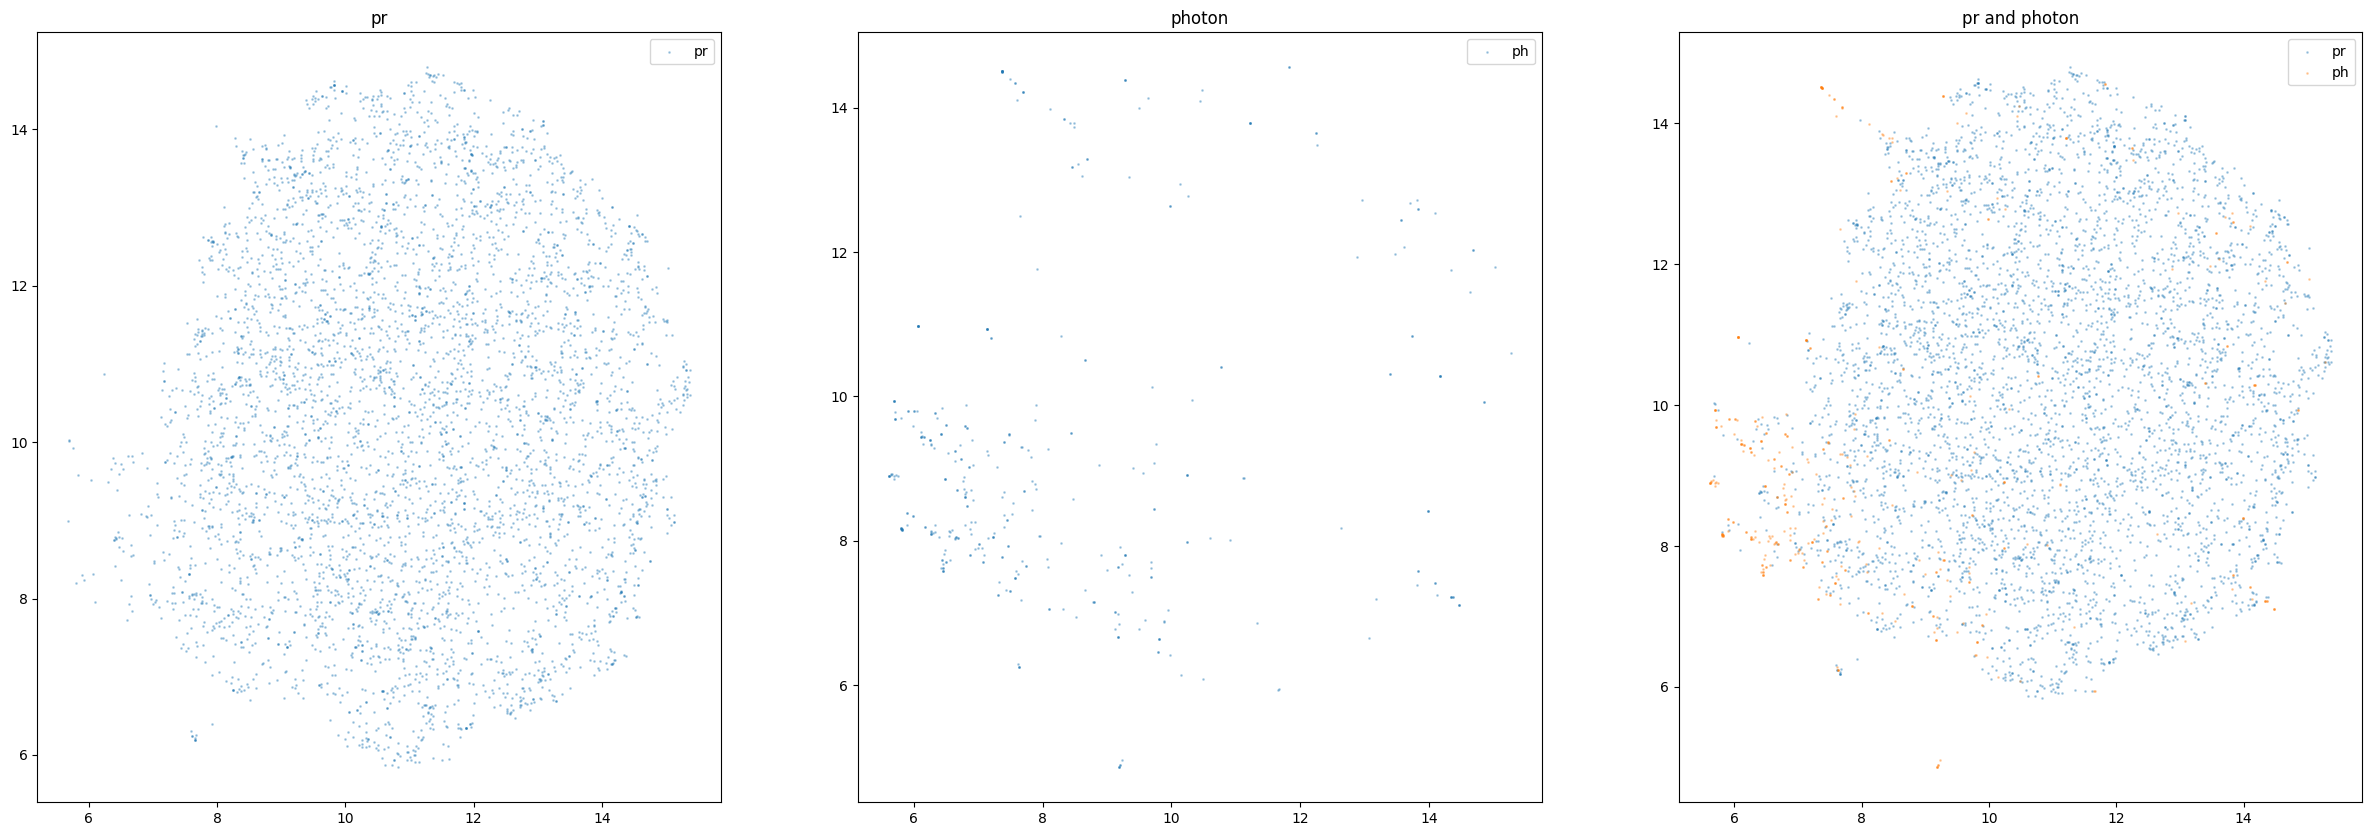

In [56]:
pr = feaches_pr[np.random.randint(0, feaches_pr.shape[0], size=5000)][:,:6]
ph = feaches_photon[np.random.randint(0, feaches_photon.shape[0], size=400)][:,:6]
use_ph = True
fig, ax = plt.subplots(1,3, figsize=(30, 10))

reducer = umap.UMAP(n_components=2)
if use_ph:
    manifold = reducer.fit(np.concatenate([pr, ph], axis=0))
else:
    manifold = reducer.fit(pr)
X_pr = manifold.transform(pr)
X_ph = manifold.transform(ph)

ax_1, ax_2, ax_3 = ax
ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=1, alpha=0.3, label='pr')
ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=1, alpha=0.3, label='ph')
ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=1, alpha=0.3, label='pr')
ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=1, alpha=0.3, label='ph')
ax_1.set_title('pr')
ax_2.set_title('photon')
ax_3.set_title('pr and photon')
ax_1.legend()
ax_2.legend()
ax_3.legend()


In [57]:
from scipy.stats import gaussian_kde
def show_2d_density(pr, ph, use_ph=True, n_ph=1, density_ph = None, density_pr = None):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph[::n_ph]], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)

    fig, ax = plt.subplots(2,3, figsize=(12, 12))
    ax_1, ax_2, ax_3 = ax[0]
    ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    X_all = np.vstack([X_pr, X_ph[::n_ph]])
    kde = gaussian_kde(X_all.T, )
    density = kde(X_all.T)  # shape: (N,)


    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    grid_x, grid_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    density = kde(np.vstack([grid_x.ravel(), grid_y.ravel()]))
    density = density.reshape(grid_x.shape)

    ax_1, ax_2, ax_3 = ax[1]
    # Отображение плотности
    cmap = plt.colormaps['PiYG']
    # (1,0) - плотность для всех точек
    im = ax[1, 0].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[1, 0].set_title('Density (all)')
    fig.colorbar(im, ax=ax[1, 0], label='Density')
    
    ax[1,0].scatter(X_ph[:, 0], X_ph[:, 1],s=1, label='ph')
    # (1,1) и (1,2) можно оставить пустыми или повторить для pr и ph отдельно
    if density_ph is None:
        density_ph = kde(X_ph.T)
    if density_pr is None:
        density_pr = kde(X_pr.T)
    
    im = ax[1, 2].scatter(X_ph[:, 0], X_ph[:, 1], s=1, label='ph', c=density_ph, cmap='viridis')
    ax[1, 2].set_title('Density (ph)')
    fig.colorbar(im, ax=ax[1, 2], label='Density')
    
    ax[1,1].hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    ax[1,1].hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    ax[1,1].legend()
    ax[1,1].set_title('Density (ph and pr)')
    ax[1,1].grid()

    plt.tight_layout()
    plt.show()

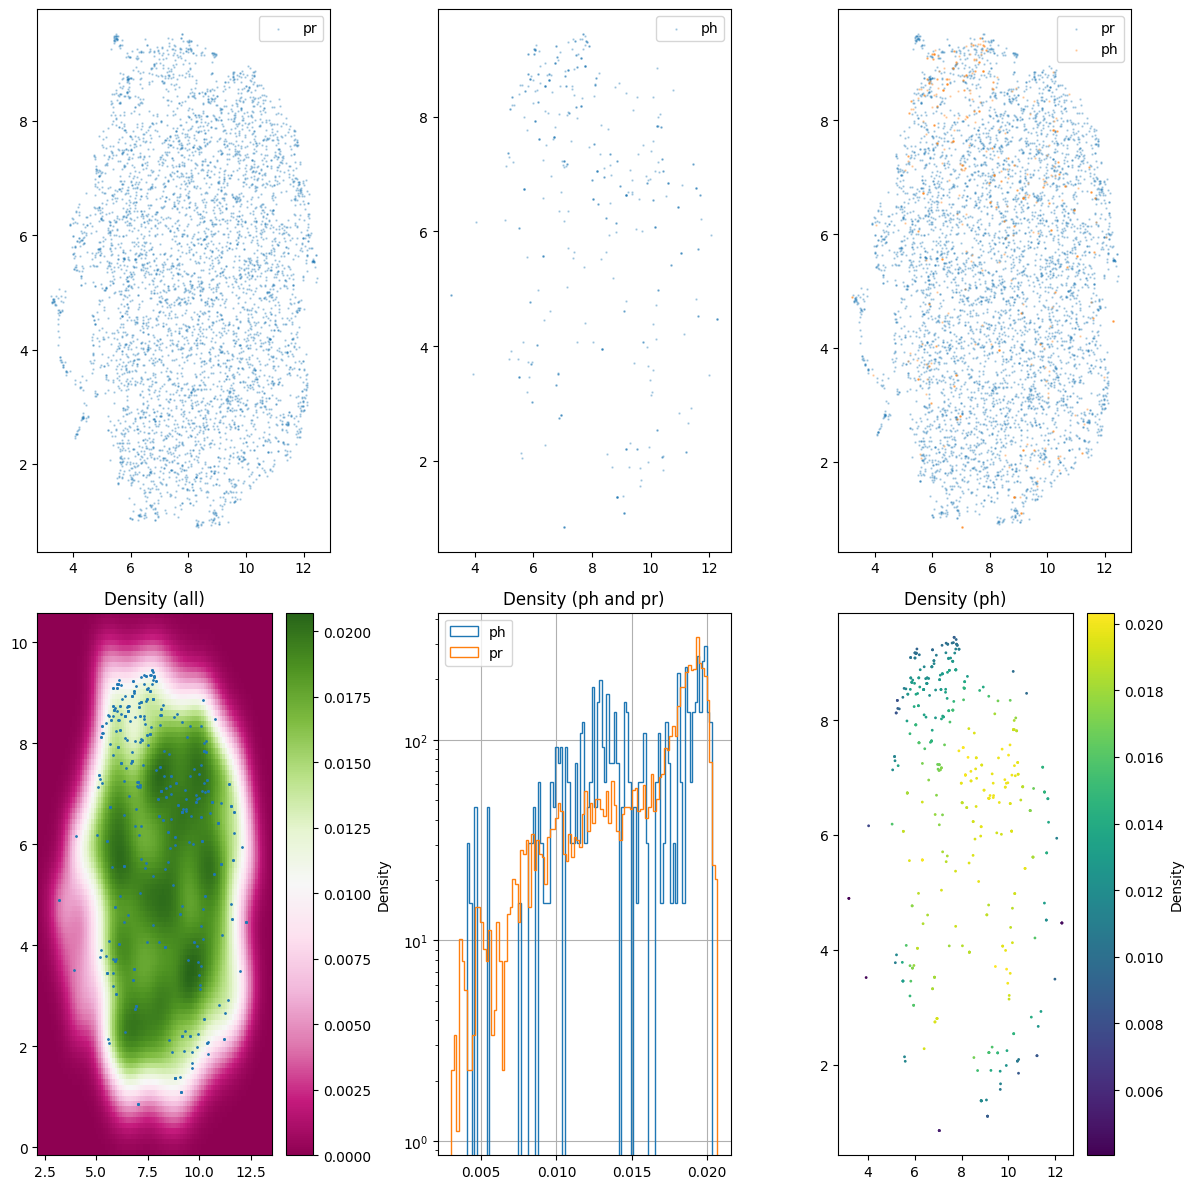

In [38]:
show_2d_density(pr[:10000],ph[:1000], n_ph=10)

In [58]:
def get_metrics(score_samples, score_samples_photon, th):
    FP_index = np.where(score_samples > th)[0]
    TP_index = np.where(score_samples_photon > th)[0]
    FN_index = np.where(score_samples_photon > th)[0]
    TN_index = np.where(score_samples < th)[0]
    part_anomalys_pr = len(FP_index)/len(score_samples)
    part_anomalys_ph = len(TP_index)/len(score_samples_photon)
    recall = len(TP_index) / (len(TP_index) + len(FN_index)+1e-10)
    precision = len(TP_index) / (len(TP_index) + len(FP_index)+1e-10)
    f1 = 2 * precision * recall / (precision + recall+1e-10)
    return recall, precision, f1, part_anomalys_pr, part_anomalys_ph
def get_top_anomalies(scores, top_percent=1.0):
    """
    Возвращает индексы top_percent самых аномальных точек.
    Чем больше score, тем более аномальна точка.
    """
    n_top = max(1, int(len(scores) * top_percent / 100.0))
    idx_sorted = np.argsort(scores)[::-1]   # по убыванию anomaly score
    top_idx = idx_sorted[:n_top]
    return top_idx, scores[top_idx]

def make_result_df(scores, name="score"):
    df = pd.DataFrame({
        "index": np.arange(len(scores)),
        name: scores
    })
    df = df.sort_values(name, ascending=False).reset_index(drop=True)
    return df

In [59]:
def iforest_anomaly_score(X_scaled, n_estimators=300, max_samples="auto", random_state=42):
    """
    Isolation Forest.
    Чем больше score, тем более аномальна точка.
    """
    clf = IsolationForest(
        n_estimators=n_estimators,
        max_samples=max_samples,
        contamination=0.025,
        random_state=random_state,
        n_jobs=-1
    )

    clf.fit(X_scaled)

    # score_samples: больше = более нормальная точка
    # берем минус, чтобы больше = более аномальная
    scores = -clf.score_samples(X_scaled)

    return scores

iforest_scores = iforest_anomaly_score(X_scaled[:,:8], n_estimators=100, random_state=42)
df_iforest = make_result_df(iforest_scores, name="iforest_score")


    index  iforest_score particle
0   32532       0.700686       pr
1    5359       0.684411       pr
2   13980       0.684095       pr
3    5258       0.683557       pr
4   17244       0.683557       pr
5   31760       0.682809       pr
6    3102       0.682809       pr
7   26741       0.682242       pr
8   14195       0.676200       pr
9   25853       0.666233       pr
10  42146       0.662205       pr
11  18283       0.659270       pr
12  36506       0.658127       pr
13  12238       0.656993       pr
14  28177       0.655753       pr
15  22077       0.655413       pr
16  19072       0.654894       pr
17  35830       0.654882       pr
18   8413       0.654435       pr
19  12075       0.653742       pr
       index  iforest_score particle
47380  24761       0.374219       pr
47381  42350       0.374213       pr
47382  18759       0.374096       pr
47383  15206       0.374096       pr
47384  24201       0.374055       pr
47385  39141       0.374055       pr
47386   7676       0.373918

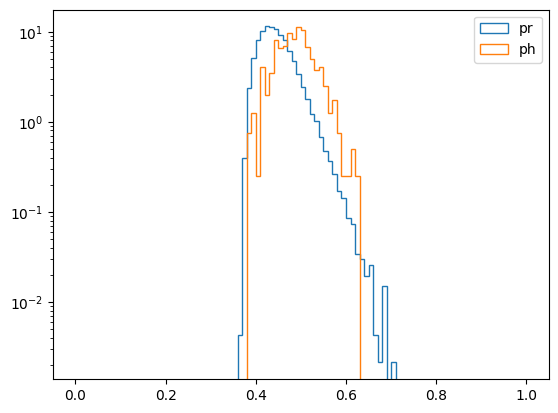

In [60]:
df_iforest['particle'] = np.where(df_iforest['index'] < num, 'pr', 'ph')
print(df_iforest.head(20))
print(df_iforest.tail(20))
print(len(df_iforest[df_iforest['particle'] == 'pr']))
print(len(df_iforest[df_iforest['particle'] == 'ph']))
print(len(df_iforest))
plt.hist(df_iforest[df_iforest['particle'] == 'pr']['iforest_score'], bins=100, label='pr', log=True, density=True, histtype='step', range=(0, 1))
plt.hist(df_iforest[df_iforest['particle'] == 'ph']['iforest_score'], bins=100, label='ph', log=True, density=True, histtype='step', range=(0, 1))
plt.legend()
plt.show()

(47000,) (400,)


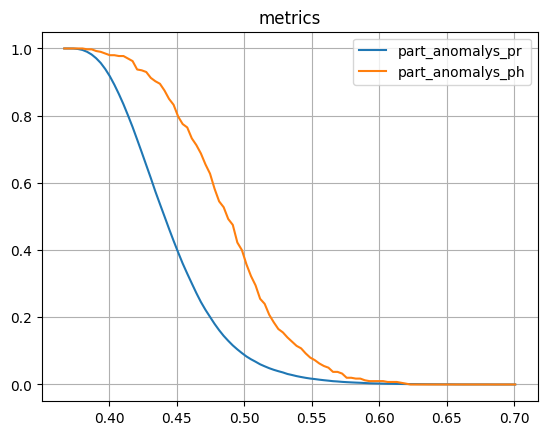

In [61]:
value = np.array(df_iforest['iforest_score'])
label_df = np.where(df_iforest['particle'] == 'pr', 0, 1)
score_samples = value[label_df == 0]
score_samples_photon = value[label_df == 1]
print(score_samples.shape, score_samples_photon.shape)
recall_list = []    
precision_list = []
f1_list = []
part_anomalys_pr_list = []
part_anomalys_ph_list = []
min_score = min(score_samples.min(), score_samples_photon.min())
max_score = max(score_samples.max(), score_samples_photon.max())
for th in np.linspace(min_score, max_score, 100):
    recall, precision, f1, part_anomalys_pr, part_anomalys_ph = get_metrics(score_samples, score_samples_photon, th)
    recall_list.append(recall)
    precision_list.append(precision)
    f1_list.append(f1)
    part_anomalys_pr_list.append(part_anomalys_pr)
    part_anomalys_ph_list.append(part_anomalys_ph)
# plt.plot(np.linspace(min_score, max_score, 100), recall_list, label='recall')
# plt.plot(np.linspace(min_score, max_score, 100), precision_list, label='precision')
# plt.plot(np.linspace(min_score, max_score, 100), f1_list, label='f1')
plt.plot(np.linspace(min_score, max_score, 100), part_anomalys_pr_list, label='part_anomalys_pr')
plt.plot(np.linspace(min_score, max_score, 100), part_anomalys_ph_list, label='part_anomalys_ph')
plt.legend()
plt.title('metrics')
plt.grid()

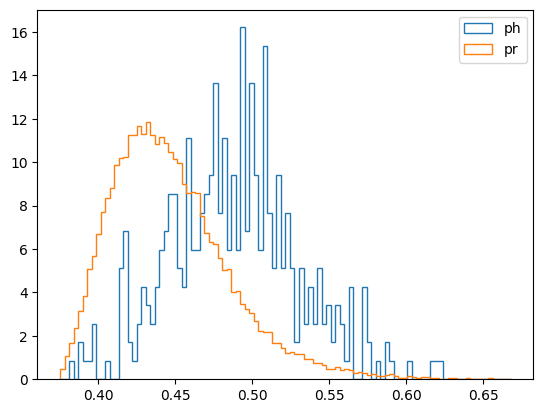

array([0.70068594, 0.68441061, 0.68409451, ..., 0.37068233, 0.36985373,
       0.36678755])

In [62]:
plt.hist(score_samples_photon, bins=100, label='ph', histtype='step', density=True, range=(0.375, 0.668))
plt.hist(score_samples, bins=100, label='pr', histtype='step', density=True, range=(0.375, 0.668))
plt.legend()
plt.show()
value


(array([ 0.        ,  0.        ,  0.85324232,  0.        ,  1.70648464,
         0.85324232,  0.85324232,  2.55972696,  0.        ,  0.        ,
         0.85324232,  0.        ,  0.        ,  5.11945392,  6.82593857,
         1.70648464,  0.85324232,  2.55972696,  4.2662116 ,  3.41296928,
         2.55972696,  4.2662116 ,  5.97269625,  6.82593857,  8.53242321,
         8.53242321,  5.11945392,  4.2662116 , 11.09215017,  5.97269625,
         5.97269625,  7.67918089,  8.53242321,  9.38566553, 13.65187713,
         7.67918089, 11.09215017,  5.97269625,  9.38566553,  5.97269625,
        16.2116041 ,  6.82593857, 13.65187713,  9.38566553,  5.97269625,
        15.35836177,  7.67918089,  5.11945392,  9.38566553,  5.11945392,
         7.67918089,  5.11945392,  1.70648464,  5.11945392,  2.55972696,
         4.2662116 ,  2.55972696,  5.11945392,  2.55972696,  3.41296928,
         1.70648464,  3.41296928,  2.55972696,  0.85324232,  4.2662116 ,
         0.        ,  0.        ,  4.2662116 ,  1.7

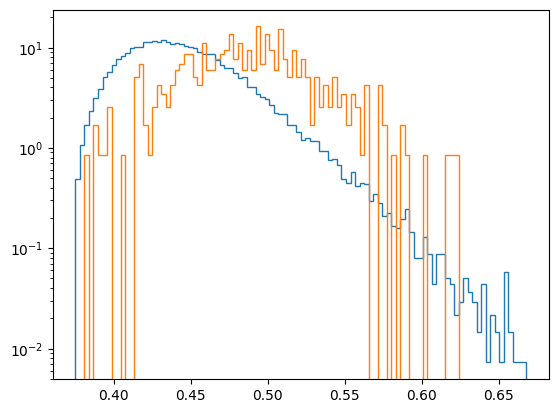

In [63]:
plt.hist(df_iforest[df_iforest['particle'] == 'pr']['iforest_score'], bins=100, label='pr', log=True, density=True, histtype='step', range=(0.375, 0.668))
plt.hist(df_iforest[df_iforest['particle'] == 'ph']['iforest_score'], bins=100, label='ph', log=True, density=True, histtype='step', range=(0.375, 0.668))


In [64]:
# KDE

In [65]:
from sklearn.neighbors import KernelDensity

In [47]:
num =47000
ch_emb = 6
num_ph = 400
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

#feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1), recos_pr[index]], axis=1)

#feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1), recos_photon[index_ph]], axis=1)

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,ch_emb]

print(feaches[:10], label[:10])

part of data 0.00851063829787234
pr (210315, 6) ph (210851, 6)
[[ 2.02569887e-01  3.52062076e-01 -1.01944661e+00  1.36310351e+00
   1.03550673e-01  1.02803397e+00  1.50000000e+01  5.87102911e-03]
 [ 1.72811604e+00  6.67437077e-01  8.32756281e-01 -9.10253346e-01
   1.83107138e-01  2.28093788e-01  8.00000000e+00  9.83920414e-04]
 [-3.31793427e-01  2.57853031e-01  8.53314936e-01 -4.22157049e-01
   1.08234835e+00  1.27239454e+00  1.20000000e+01  2.58577336e-03]
 [ 3.42081904e-01 -2.08956432e+00 -3.84841353e-01  4.73867744e-01
  -1.01573110e+00  1.18268418e+00  1.40000000e+01  1.59378012e-03]
 [ 8.88173580e-01  2.09860086e-01 -6.72657251e-01  1.83035463e-01
   6.71072721e-01 -9.13895249e-01  1.20000000e+01  4.28161211e-03]
 [ 2.16639042e+00  2.66503021e-02 -1.40878105e+00 -1.59441698e+00
   9.63510633e-01  1.24480598e-01  1.50000000e+01  9.20029765e-04]
 [ 7.58393705e-01 -1.18160772e+00 -2.38379277e-03  8.35139930e-01
   6.30963326e-01 -1.48021713e-01  1.10000000e+01  3.92144267e-03]
 [ 9.1

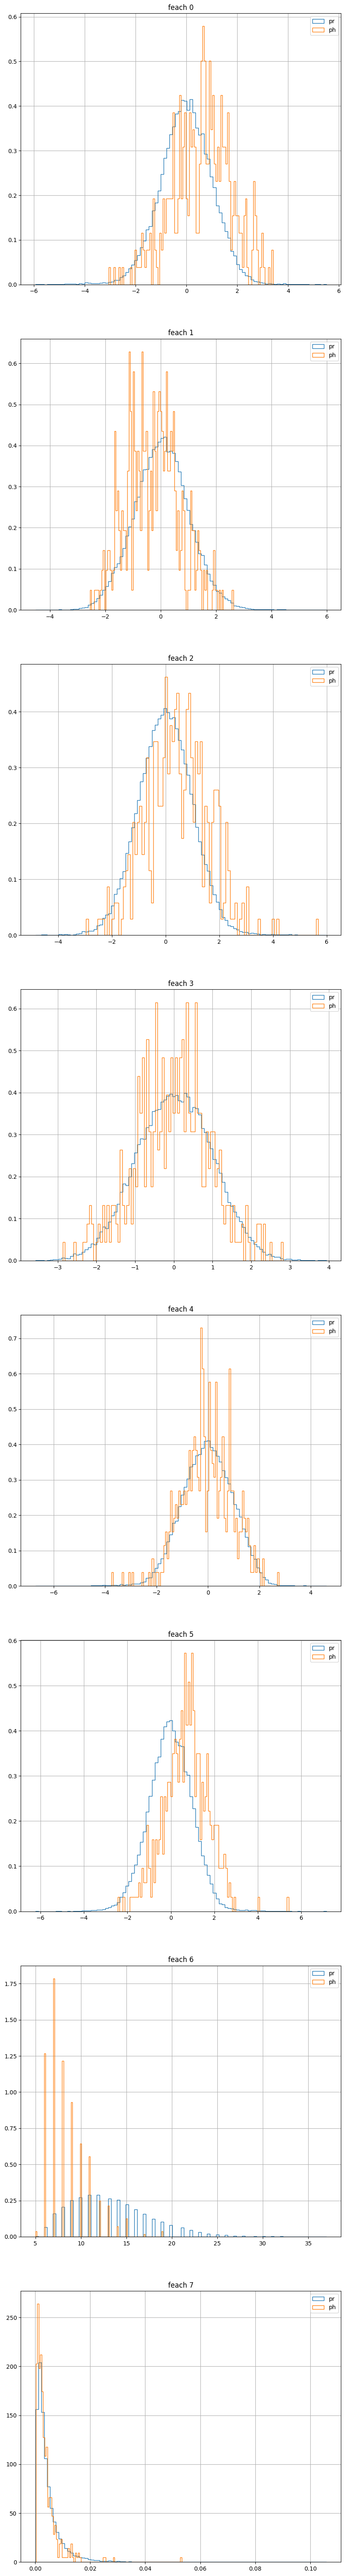

In [48]:

fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].legend()
    ax[i].set_title(f'feach {i}')
    ax[i].grid()
plt.show()



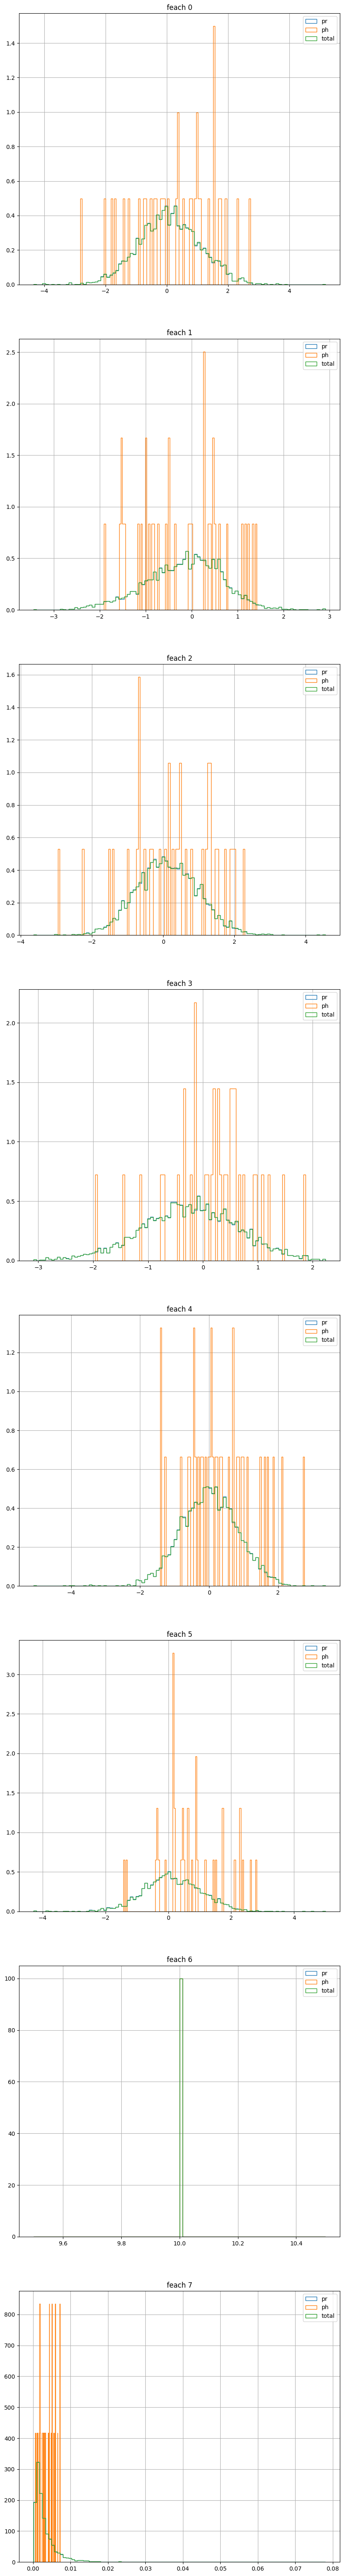

In [49]:
N=10
fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i][num_det_feaches[label == 0] == N], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i][num_det_feaches[label == 1] == N], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].hist(feaches[:,i][num_det_feaches == N], bins=100, label=f'total', histtype='step', density=True)
    ax[i].legend()
    ax[i].set_title(f'feach {i}')
    ax[i].grid()
plt.show()

In [51]:
feaches_pr[feaches_pr[:,6] == N, 7].shape

(4095,)

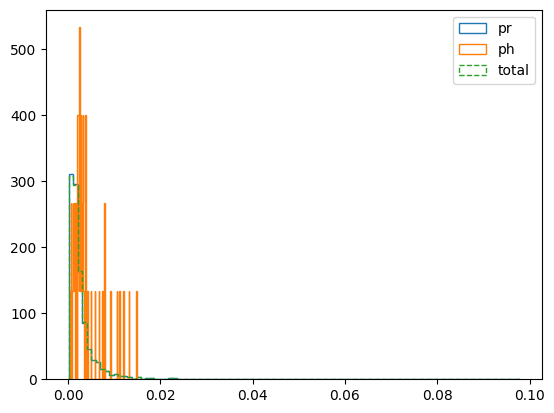

In [52]:
N = 9
plt.hist(feaches_pr[feaches_pr[:,ch_emb] == N, 7], bins=100, label='pr', histtype='step', density=True)
plt.hist(feaches_photon[feaches_photon[:,ch_emb] == N, 7], bins=100, label='ph', histtype='step', density=True)
plt.hist(feaches[feaches[:,ch_emb] == N, 7], bins=100, label='total', histtype='step', density=True, linestyle='--')
plt.legend()
plt.show()

(4095, 8) (36, 8)


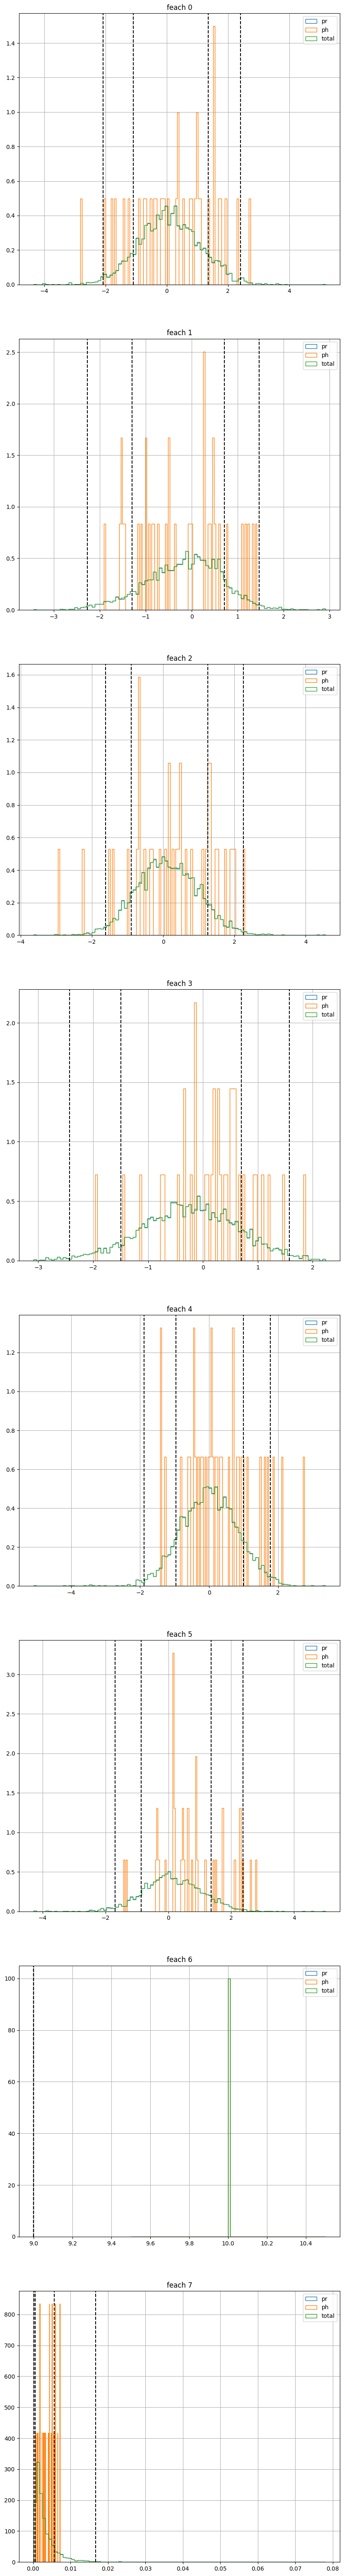

In [53]:
# quantile
quan_list = [0.01, 0.1, 0.9, 0.99]
quantile_feaches = np.quantile(feaches[num_det_feaches == N], quan_list, axis=0)
N=10
fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i][num_det_feaches[label == 0] == N], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i][num_det_feaches[label == 1] == N], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].hist(feaches[:,i][num_det_feaches == N], bins=100, label=f'total', histtype='step', density=True)
    ax[i].legend()
    for j in range(quantile_feaches.shape[0]):
        ax[i].axvline(quantile_feaches[j,i], color='k', linestyle='--', label=f'quan {quan_list[j]}')
    ax[i].set_title(f'feach {i}')
    
    ax[i].grid()
pr = feaches[label == 0,:][num_det_feaches[label == 0] == N]
ph = feaches[label == 1,:][num_det_feaches[label == 1] == N]
print(pr.shape, ph.shape)


In [60]:
ch_emb= 6
X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:ch_emb], X[:,ch_emb+1:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())
# feaches = X_scaled

(4131, 7)
pr 4095 ph 36


-6.421288613981038 -7.100118406303867
0.6545787527641499 0.0


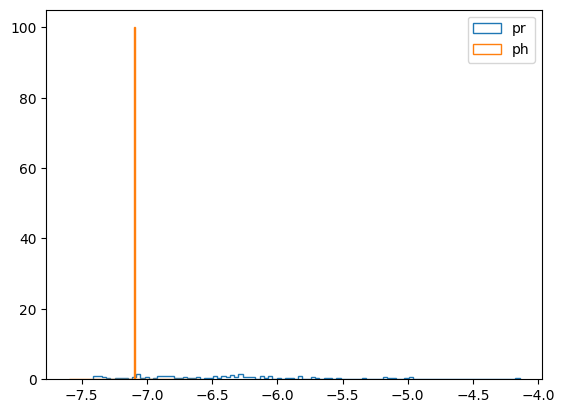

In [68]:
# kde

bandwidth = 0.35

num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

plt.hist(scores[label_scores == 0], bins=100, label='pr', histtype='step', density=True,)
plt.hist(scores[label_scores == 1], bins=100, label='ph', histtype='step', density=True,)
print(scores[label_scores == 0].mean(), scores[label_scores == 1].mean())
print(scores[label_scores == 0].std(), scores[label_scores == 1].std())
plt.legend()
plt.show()




-6.420877686646742 -7.145980514357419
0.6557217163877522 0.3187303447285529


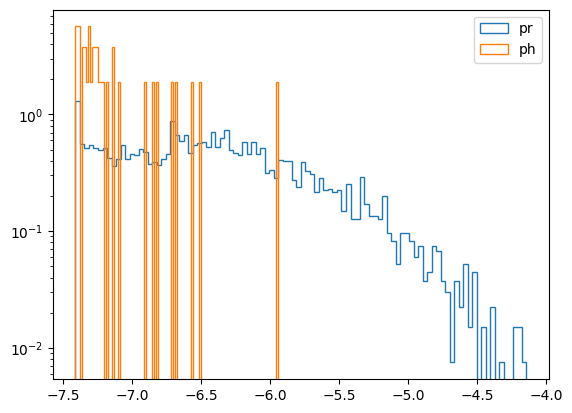

In [69]:
scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

-6.420877686646742 -7.145980514357419
0.6557217163877522 0.3187303447285529


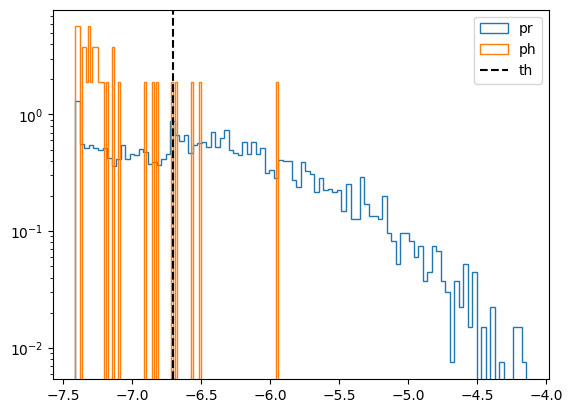

In [71]:
th=-6.7
scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.axvline(th, color='k', linestyle='--', label=f'th')
plt.legend()

In [72]:
def show_del_by_score(pr, ph, use_ph=True, n_ph=1, density_ph = None, density_pr = None, th = 0.1):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    fig = plt.subplot()
    plt.hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    plt.hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    plt.axvline(th, color='k', linestyle='--', label=f'th')
    plt.legend()
    plt.show()
    fig, ax = plt.subplots(2,3, figsize=(12, 12))
    ax_1, ax_2, ax_3 = ax[0]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph[::n_ph]], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)

    X_all = np.vstack([X_pr, X_ph[::n_ph]])

    kde = gaussian_kde(X_all.T, )
    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    grid_x, grid_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    density = kde(np.vstack([grid_x.ravel(), grid_y.ravel()]))
    density = density.reshape(grid_x.shape)
    cmap = plt.colormaps['PiYG']
    # (1,0) - плотность для всех точек
    im = ax[0, 2].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[0, 2].set_title('Density (all)')
    fig.colorbar(im, ax=ax[0, 2], label='Density')

    im = ax[1, 2].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[1, 2].set_title('Density (all)')
    fig.colorbar(im, ax=ax[1, 2], label='Density')

    ax_1, ax_2, ax_3 = ax[0]
    ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    pr_index = density_pr<th
    ph_index = density_ph<th
    print(len(density_pr), len(density_ph))
    print(pr_index.sum(), ph_index.sum())
    print(len(X_pr[pr_index, 0]), len(X_ph[ph_index, 0]))
    ax_1, ax_2, ax_3 = ax[1]
    ax_1.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=0.5, alpha=0.3, label='ph')
    
    # ax[1,1].hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    # ax[1,1].hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    # ax[1,1].legend()
    # ax[1,1].set_title('Density (ph and pr)')
    # ax[1,1].grid()

    plt.tight_layout()
    plt.show()

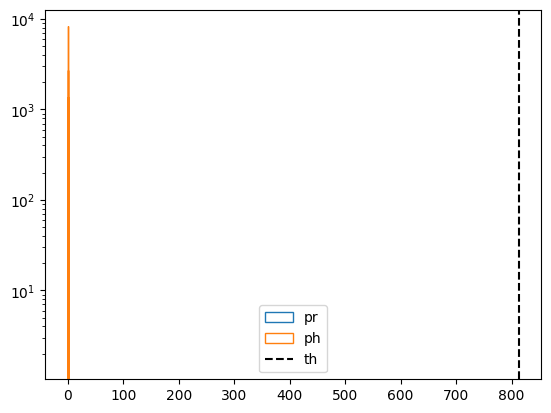

4095 36
4095 36
4095 36


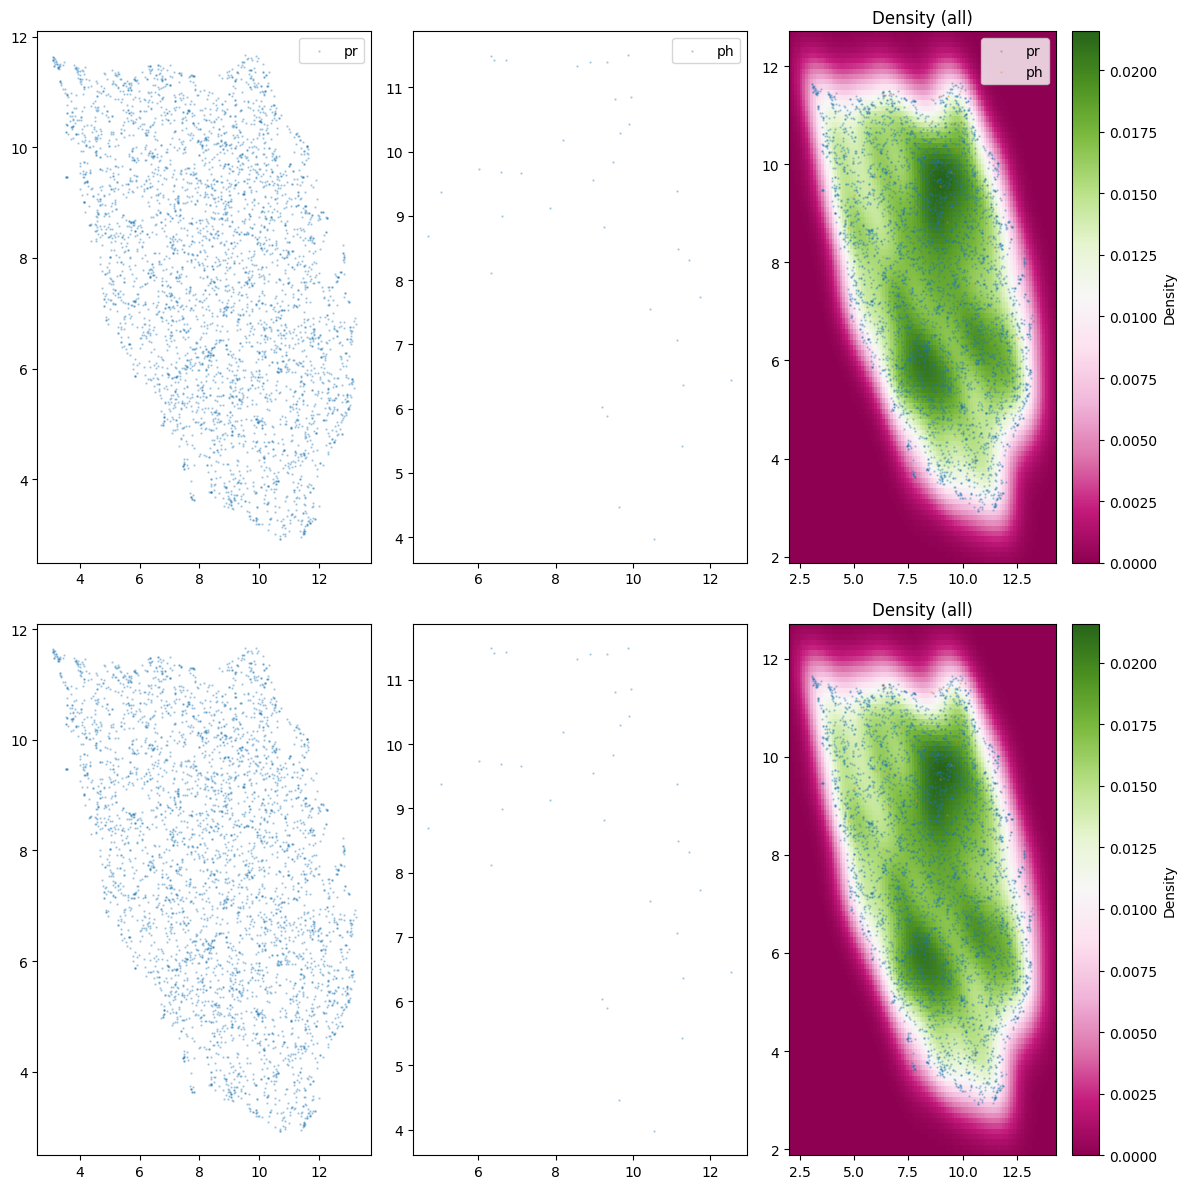

In [73]:
th = -6.7
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=np.exp(scores_ph), density_pr=np.exp(scores_pr), th=np.exp(-th))

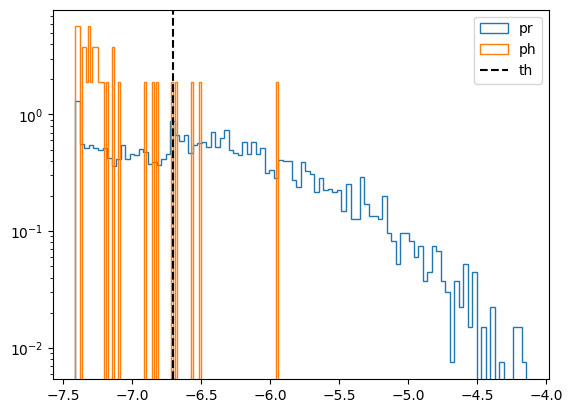

4095 36
1504 32
1504 32


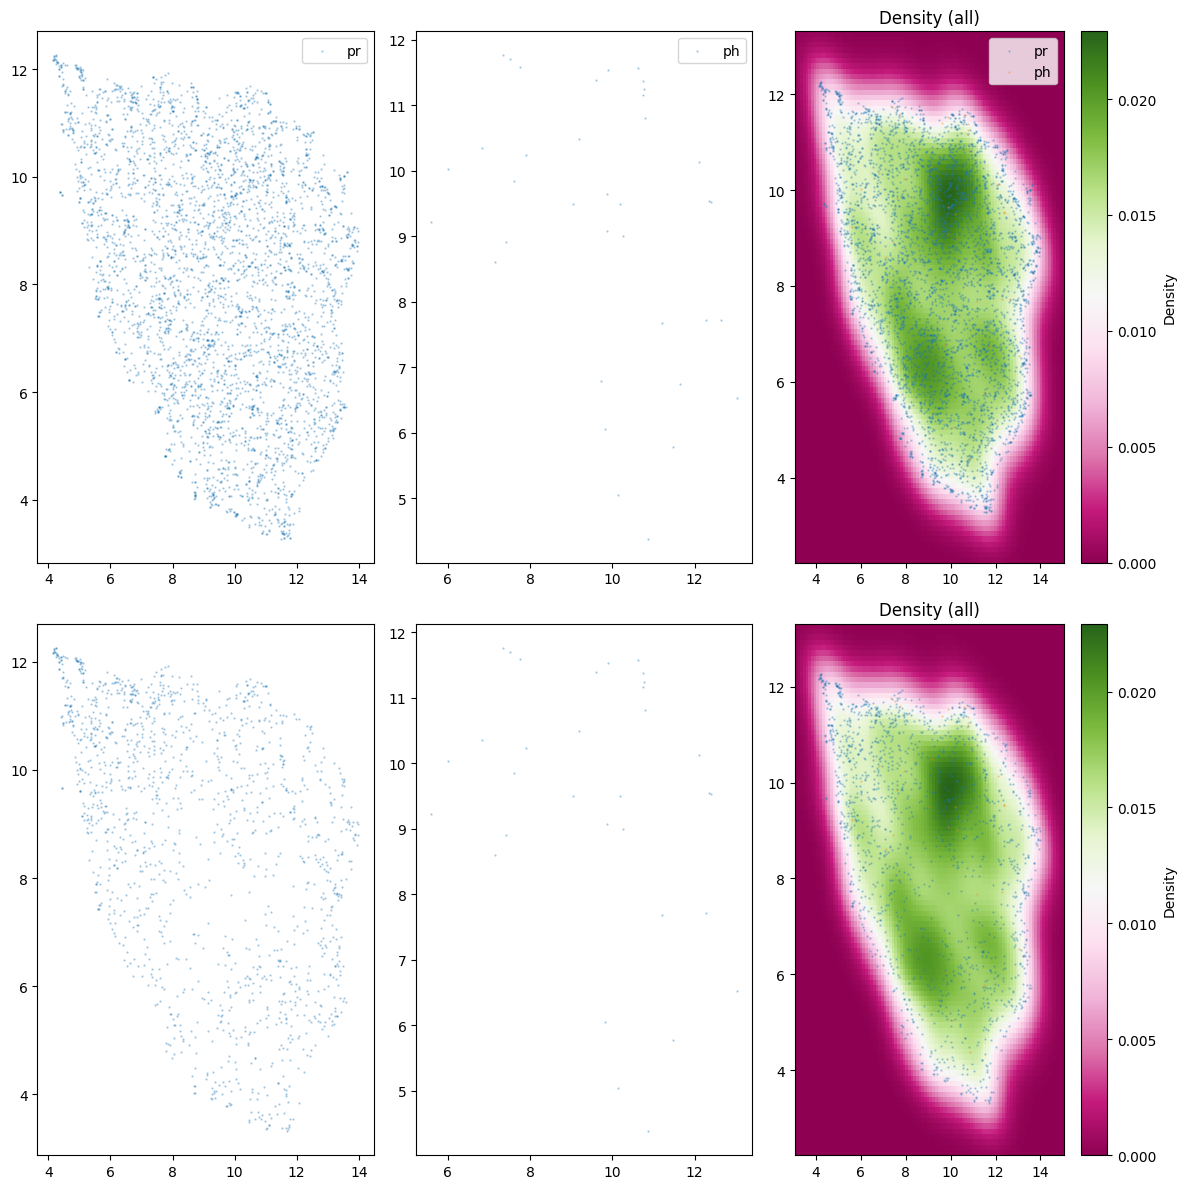

In [74]:
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=-6.7)

In [182]:
# Полный прогоне KDE 

# Полный прогоне KDE 

In [75]:
print(len(embading_pr), len(embading_photon))

210315 210851


In [76]:
np.where(num_det_pr == N)[0].shape

(18391,)

part of data 0.01
pr (210315, 6) ph (210851, 6)
(10939, 7)
pr 10476 ph 463
-6.03973793402203 -6.976157430333174
0.7080336563713638 0.44979514717048596


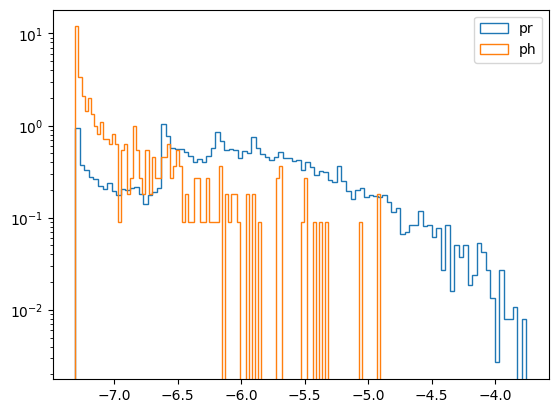

In [82]:

num =200000
num_ph = 2000
N = 7
bandwidth = 0.3
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

index_pr_N_det = np.where(num_det_pr == N)[0]
index_ph_N_det = np.where(num_det_photon == N)[0]

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,ch_emb]



X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:ch_emb], X[:,ch_emb+1:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())


num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

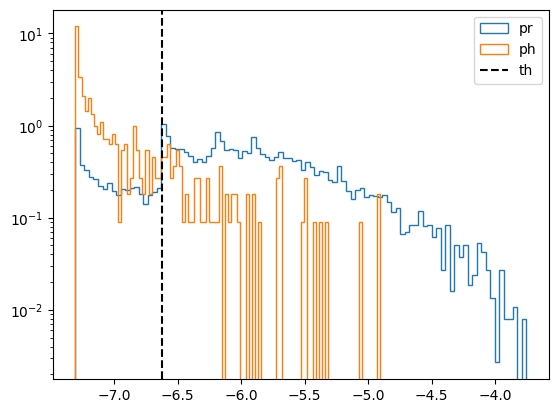

In [86]:
th=-6.62
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.axvline(th, color='k', linestyle='--', label=f'th')
plt.legend()

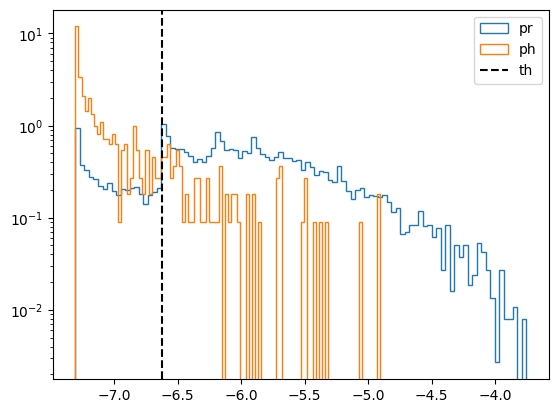

10476 463
1858 377
1858 377


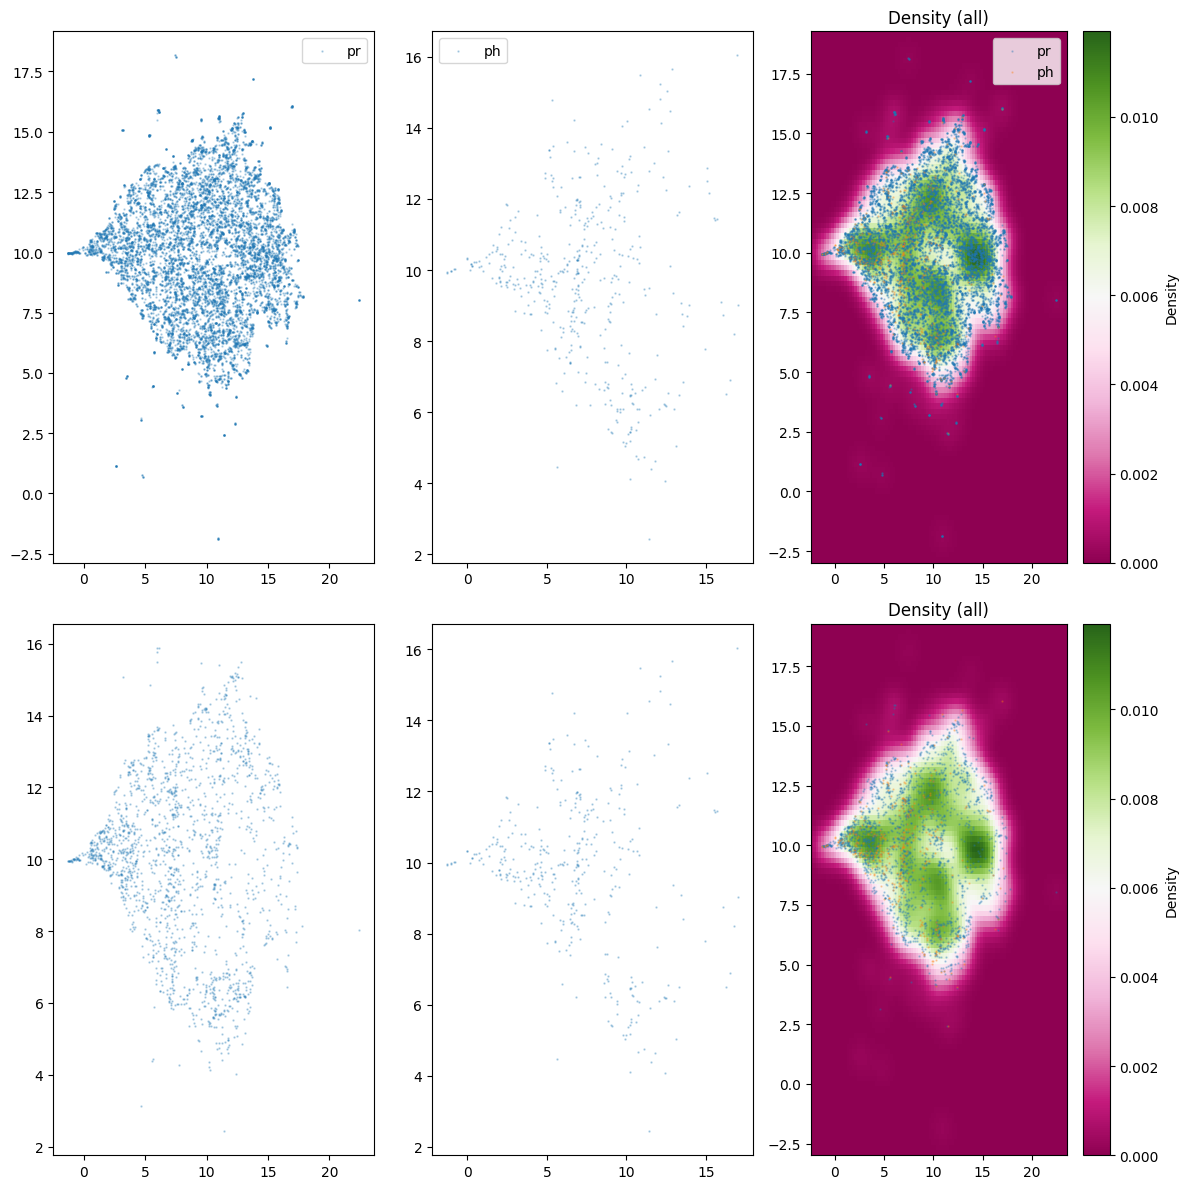

In [87]:
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=-6.62)

# 17.7% protons
# 81.4% photons

In [ ]:
th=-8.9
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=th)

10376 458
2684 304
2684 304

10357 484
1449 212
1449 212

In [92]:
# Проверка на востановление recos из латентного пространства
from catboost import CatBoostRegressor
latent_pr = embading_pr.copy()
latent_photon = embading_photon.copy()
print(latent_pr.shape, latent_photon.shape, recos_pr.shape, recos_photon.shape)

(210315, 6) (210851, 6) (210315, 15) (210851, 15)


In [93]:
#test-train split
import sklearn
from sklearn.model_selection import train_test_split
latent_pr_train, latent_pr_test, recos_pr_train, recos_pr_test = train_test_split(latent_pr, recos_pr, test_size=0.2, random_state=42)
latent_photon_train, latent_photon_test, recos_photon_train, recos_photon_test = train_test_split(latent_photon, recos_photon, test_size=0.2, random_state=42)



In [97]:
regressor = CatBoostRegressor(n_estimators=1000, learning_rate=0.05, depth=10, random_seed=42,
loss_function='MultiRMSE', eval_metric='MultiRMSE', early_stopping_rounds=20)
regressor.fit(latent_pr_train, recos_pr_train, eval_set=(latent_pr_test, recos_pr_test), use_best_model=True)




0:	learn: 3.8767503	test: 3.8668457	best: 3.8668457 (0)	total: 245ms	remaining: 4m 4s
1:	learn: 3.8764072	test: 3.8668856	best: 3.8668457 (0)	total: 509ms	remaining: 4m 13s
2:	learn: 3.8761535	test: 3.8668897	best: 3.8668457 (0)	total: 763ms	remaining: 4m 13s
3:	learn: 3.8758908	test: 3.8669248	best: 3.8668457 (0)	total: 997ms	remaining: 4m 8s
4:	learn: 3.8755514	test: 3.8669188	best: 3.8668457 (0)	total: 1.24s	remaining: 4m 7s
5:	learn: 3.8752395	test: 3.8669281	best: 3.8668457 (0)	total: 1.5s	remaining: 4m 8s
6:	learn: 3.8750008	test: 3.8669561	best: 3.8668457 (0)	total: 1.77s	remaining: 4m 11s
7:	learn: 3.8746971	test: 3.8669702	best: 3.8668457 (0)	total: 2.04s	remaining: 4m 13s
8:	learn: 3.8743731	test: 3.8670063	best: 3.8668457 (0)	total: 2.28s	remaining: 4m 10s
9:	learn: 3.8740308	test: 3.8670228	best: 3.8668457 (0)	total: 2.52s	remaining: 4m 9s
10:	learn: 3.8737628	test: 3.8670227	best: 3.8668457 (0)	total: 2.74s	remaining: 4m 6s
11:	learn: 3.8734312	test: 3.8670451	best: 3.8668

In [ ]:
regressor.

## ПРогон KDE с recos

part of data 0.01
pr (210315, 6) ph (210851, 6)
(202000, 23)




In [89]:

num =200000
num_ph = 2000
N = 7
bandwidth = 0.41
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

# add recos
feaches_pr = np.concatenate([feaches_pr, recos_pr[index]], axis=1)
feaches_photon = np.concatenate([feaches_photon, recos_photon[index_ph]], axis=1)


feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,ch_emb]

print(feaches.shape)
fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].legend()
    ax[i].set_title(f'feach {i}')
    ax[i].grid()
plt.show()

part of data 0.01
pr (210315, 8) ph (210851, 8)
[[ 4.34671849e-01  4.49277103e-01  2.28105724e-01  5.41433513e-01
  -1.10380065e+00 -1.11490464e+00 -8.64692450e-01 -1.02637076e+00
   9.00000000e+00  6.66710315e-03  1.38128757e+00  6.84225783e-02
  -1.02817282e-01  7.56021500e-01]
 [-5.85101843e-01  1.77080691e+00  8.62918913e-01 -4.14451182e-01
   1.68913400e+00  1.31564379e+00 -7.44193077e-01  1.19321674e-01
   1.00000000e+01  6.87978324e-03 -7.46476114e-01 -1.29246199e+00
   1.16859007e+00  8.00965905e-01]
 [-2.49369711e-01  8.18214774e-01 -3.97974439e-03  3.63665879e-01
   1.54659307e+00  3.77776682e-01 -1.55828297e+00  9.90129590e-01
   1.10000000e+01  4.79980884e-03  8.86704445e-01  2.63838738e-01
  -4.11055982e-01 -3.48720312e-01]
 [-1.95486927e+00 -1.07884419e+00 -1.34793437e+00  2.75565922e-01
   7.06481695e-01 -1.16176713e+00  1.46287382e-01 -1.04862607e+00
   1.70000000e+01  7.17344414e-03  8.79210755e-02 -7.15842903e-01
   1.56210721e+00  1.28701925e+00]
 [ 1.71147394e+00  3

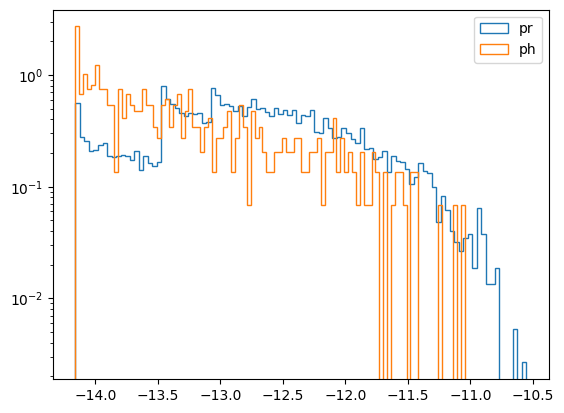

In [59]:
num =200000
num_ph = 2000
N = 7
recos_last = -4
bandwidth = 0.58
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

index_pr_N_det = np.where(num_det_pr == N)[0]
index_ph_N_det = np.where(num_det_photon == N)[0]

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

# add recos
feaches_pr = np.concatenate([feaches_pr, recos_pr[index, :-recos_last]], axis=1)
feaches_photon = np.concatenate([feaches_photon, recos_photon[index_ph, :-recos_last]], axis=1)



feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,8]

print(feaches[:10], label[:10])


X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:8], X[:,9:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())


num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

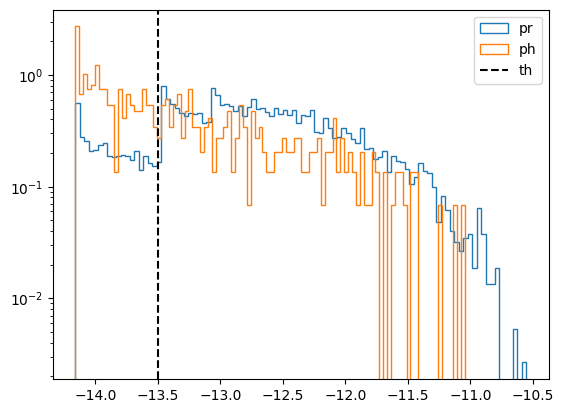

10407 472
1509 227
1509 227


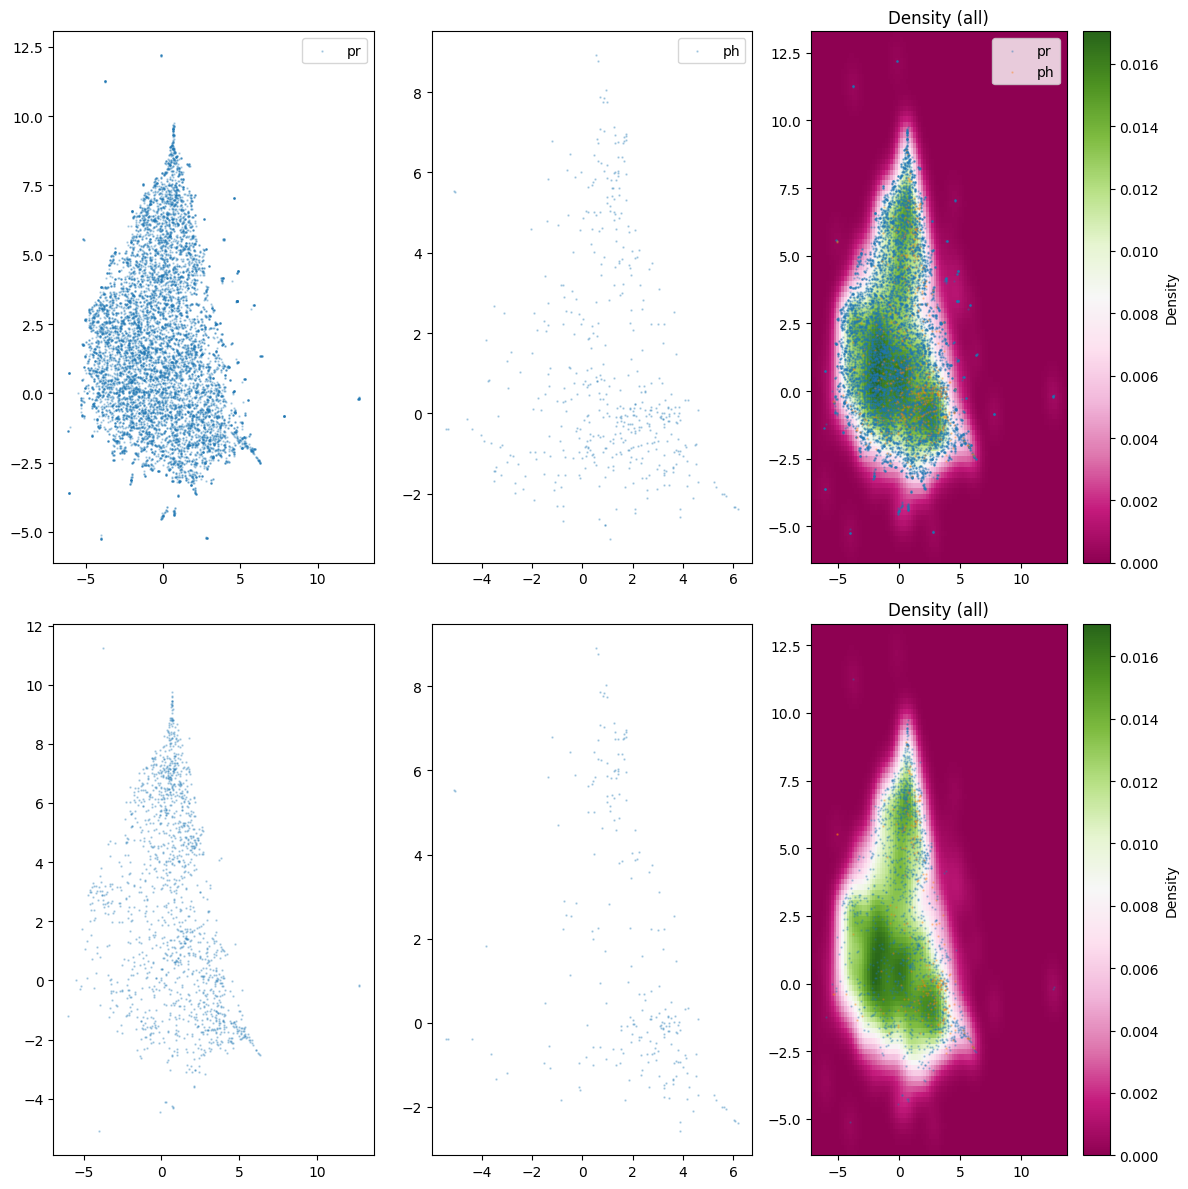

In [60]:
th=-13.5
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=th)

In [70]:
def show_del_by_score_only_KDE_MAP(pr, ph, use_ph=True, n_ph=1, density_ph = None, density_pr = None, th = 0.1):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    fig = plt.subplot()
    plt.hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    plt.hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    plt.axvline(th, color='k', linestyle='--', label=f'th')
    plt.legend()
    plt.title('Density (pr and ph)')
    plt.xlabel('log probability')
    plt.ylabel('log density')
    plt.show()
    fig, ax = plt.subplots(1,2, figsize=(12, 12))
    ax_3 = ax[0]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph[::n_ph]], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)

    X_all = np.vstack([X_pr, X_ph[::n_ph]])

    kde = gaussian_kde(X_all.T, )
    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    grid_x, grid_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    density = kde(np.vstack([grid_x.ravel(), grid_y.ravel()]))
    density = density.reshape(grid_x.shape)
    cmap = plt.colormaps['PiYG']
    # (1,0) - плотность для всех точек
    im = ax[0].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[0].set_title('All Data')
    fig.colorbar(im, ax=ax[0], label='Density')

    im = ax[1].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[1].set_title('Anomaly Data')
    fig.colorbar(im, ax=ax[1], label='Density')

    ax_3 = ax[0]
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=1, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=1, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    pr_index = density_pr<th
    ph_index = density_ph<th
    print(len(density_pr), len(density_ph))
    print(pr_index.sum(), ph_index.sum())
    print(len(X_pr[pr_index, 0]), len(X_ph[ph_index, 0]))
    ax_3 = ax[1]
    ax_3.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=3, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=3, alpha=0.3, label='ph')
    
    # ax[1,1].hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    # ax[1,1].hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    # ax[1,1].legend()
    # ax[1,1].set_title('Density (ph and pr)')
    # ax[1,1].grid()

    plt.tight_layout()
    plt.show()

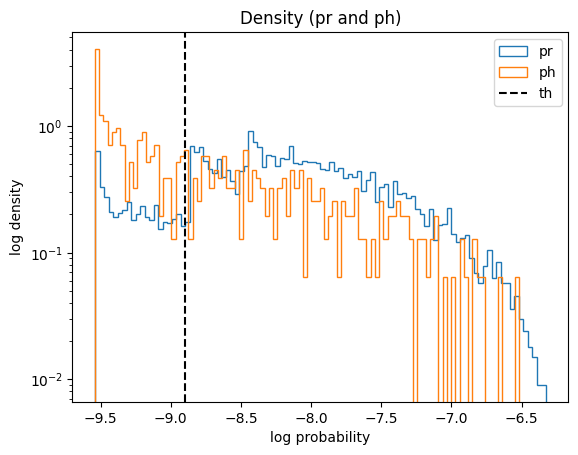

10358 514
1516 257
1516 257


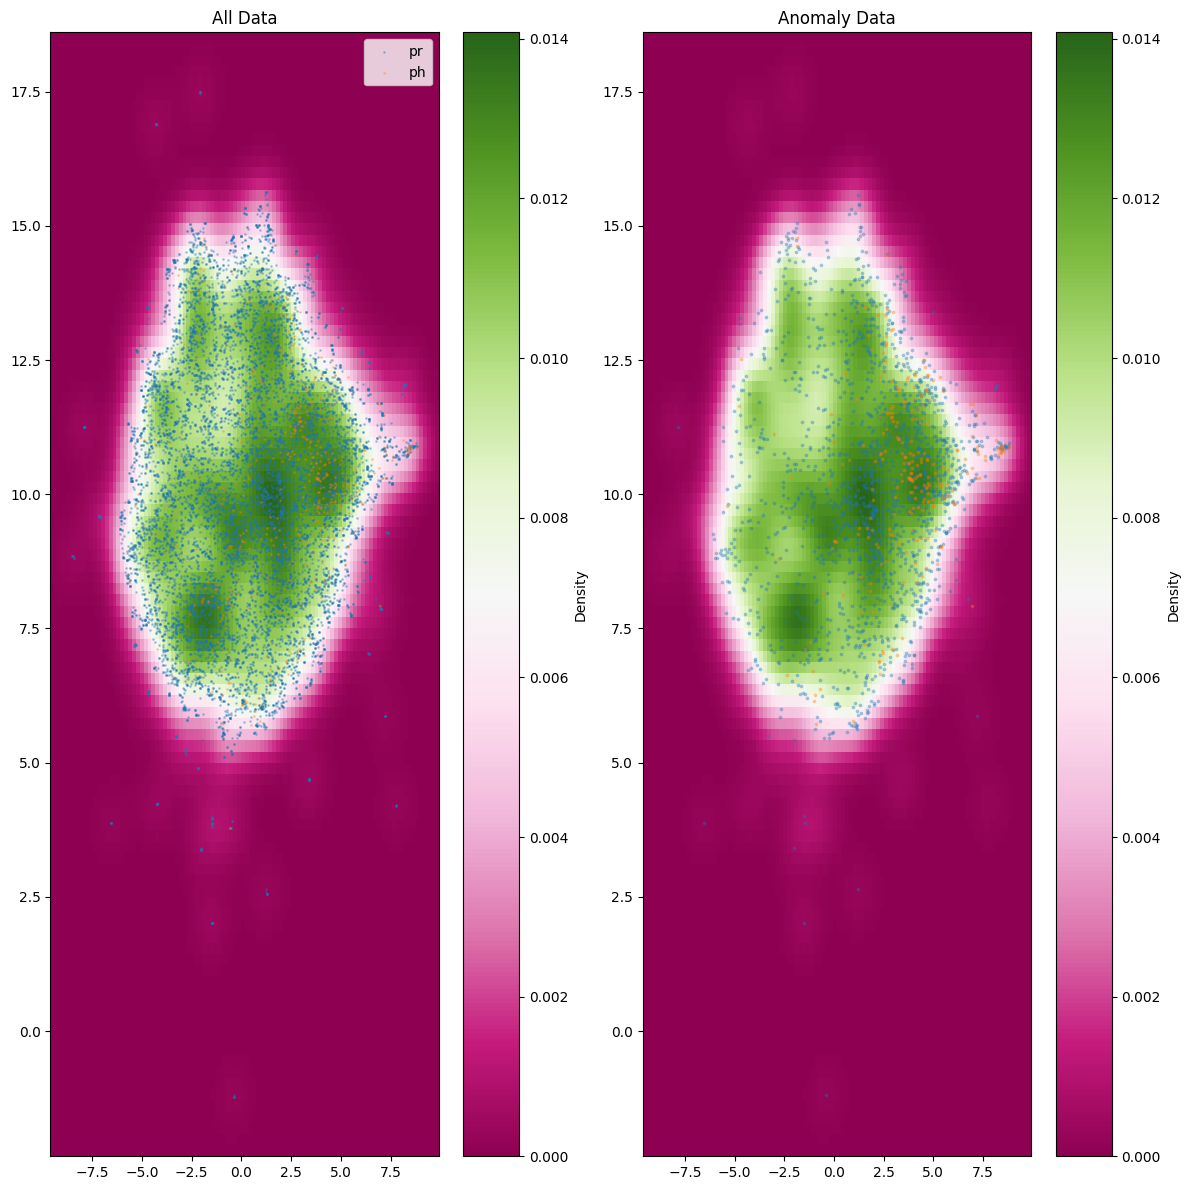

In [71]:
show_del_by_score_only_KDE_MAP(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=th)

Было 
```
10440 485
1540 263
1540 263
```

СТало
```
10407 472
1509 227
1509 227
```

## по бинам анализ

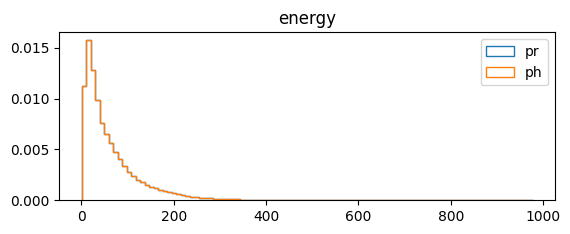

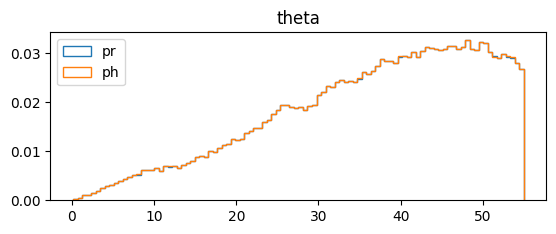

In [124]:
# plt.subplots(2,1, figsize=(10, 10))
plt.subplot(2,1,1)
plt.hist(recos_norming_pr[:,3], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_norming_photon[:,3], bins=100, label='ph', histtype='step', density=True)
plt.title('energy')
plt.legend()
plt.show()
plt.subplot(2,1,2)
plt.hist(recos_norming_pr[:,0], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_norming_photon[:,0], bins=100, label='ph', histtype='step', density=True)
plt.title('theta')
plt.legend()
plt.show()


[     0  30045  60090  90135 120180 150225 180270 210314] 8


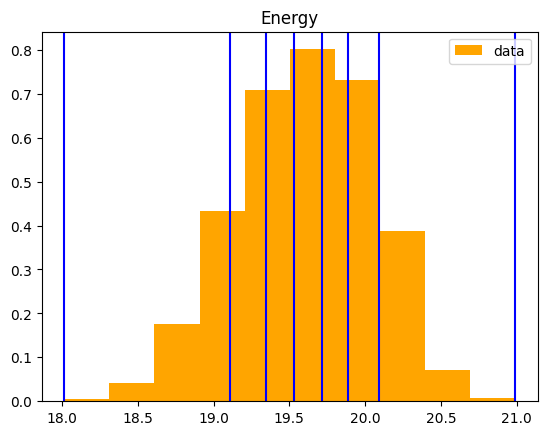

данных в одном бине 30045.0


In [125]:
Energy_pr = np.log10(recos_norming_pr[:,3])+18
Energy_photon = np.log10(recos_norming_photon[:,3])+18
indices_pr_E = np.argsort(recos_norming_pr[:,3])
indices_photon_E = np.argsort(recos_norming_photon[:,3])
num_bins = 7

indices_bin_E = np.linspace(0, len(indices_pr_E), num_bins,endpoint=False).astype(int)
indices_bin_E = np.append(indices_bin_E, len(indices_pr_E)-1)
print(indices_bin_E, len(indices_bin_E))

plt.hist(Energy_pr, density=True, label='data', color='orange')
# plt.hist(Energy_photon, density=True, label='photon')
for i in range(num_bins+1):
    v = indices_pr_E[indices_bin_E[i]]
    # plt.axvline(Energy_pr[v], color='red')
    plt.axvline(Energy_photon[v], color='blue')
plt.legend()
plt.title('Energy')
plt.show()

print(f'данных в одном бине {len(indices_pr_E)/num_bins}')

-0.44057262 -0.18435791


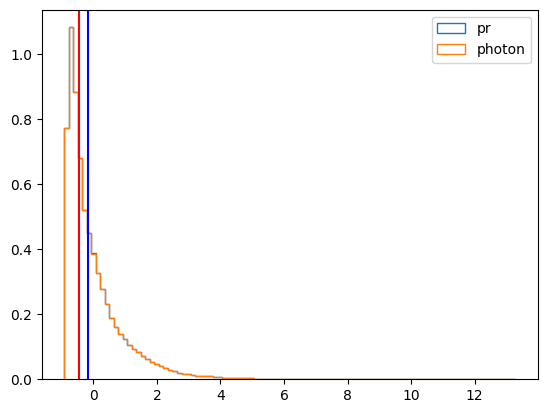

In [127]:
n_bin = 3

v_min = indices_pr_E[indices_bin_E[n_bin]]
v_max = indices_pr_E[indices_bin_E[n_bin+1]]

E_min = recos_norming_pr[:,3][v_min]
E_max = recos_norming_pr[:,3][v_max]

norm_E_min = (E_min  - mean_recos[3])/std_recos[3]
norm_E_max = (E_max  - mean_recos[3])/std_recos[3]

print(norm_E_min, norm_E_max)



plt.hist(recos_pr[:,3], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_photon[:,3], bins=100, label='photon', histtype='step', density=True)
plt.axvline(norm_E_min, color='red')
plt.axvline(norm_E_max, color='blue')
plt.legend()
plt.show()

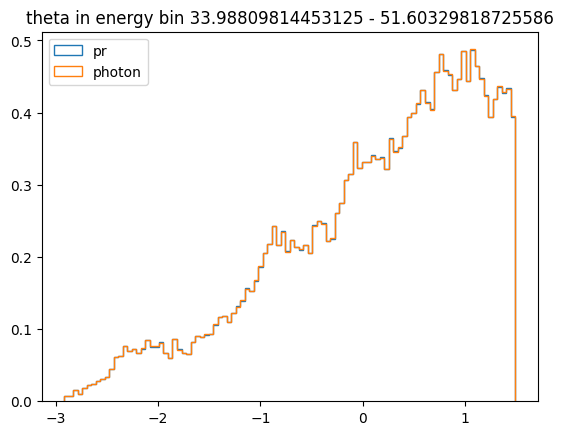

In [128]:
indexby_ener_pr = np.where(np.logical_and(recos_pr[:,3] > norm_E_min, recos_pr[:,3] < norm_E_max))[0]
indexby_ener_photon = np.where(np.logical_and(recos_photon[:,3] > norm_E_min, recos_photon[:,3] < norm_E_max))[0]

plt.hist(recos_pr[indexby_ener_pr,0], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_photon[indexby_ener_photon,0], bins=100, label='photon', histtype='step', density=True)
plt.legend()
plt.title(f'theta in energy bin {E_min} - {E_max}')
plt.show()





In [129]:
recos_pr[indexby_ener_pr,0].shape

(30044,)

[    0  4292  8584 12876 17168 21460 25752 30043] 8


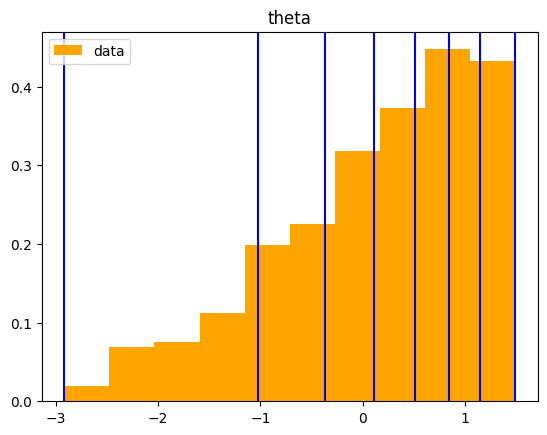

данных в одном бине 4292.0


In [130]:
indices_pr_theta = np.argsort(recos_pr[indexby_ener_pr,0])
indices_photon_theta = np.argsort(recos_photon[indexby_ener_photon,0])
num_bins = 7

indices_bin_theta = np.linspace(0, len(recos_pr[indexby_ener_pr,0]), num_bins,endpoint=False).astype(int)
indices_bin_theta = np.append(indices_bin_theta, len(recos_pr[indexby_ener_pr,0])-1)
print(indices_bin_theta, len(indices_bin_theta))

plt.hist(recos_pr[indexby_ener_pr,0], density=True, label='data', color='orange')
# plt.hist(Energy_photon, density=True, label='photon')
for i in range(num_bins+1):
    v = indices_pr_theta[indices_bin_theta[i]]
    # plt.axvline(Energy_pr[v], color='red')
    plt.axvline(recos_pr[indexby_ener_pr,0][v], color='blue')
plt.legend()
plt.title('theta')
plt.show()

print(f'данных в одном бине {len(indices_pr_theta)/num_bins}')

-0.44057262 -0.18435791 0.10912752 0.50777656


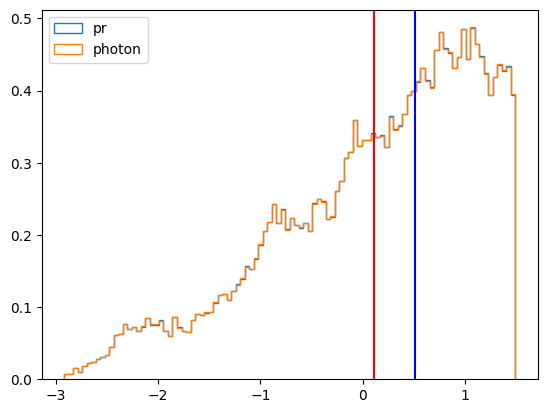

In [131]:
n_bin_theta = 3

v_min = indices_pr_theta[indices_bin_theta[n_bin_theta]]
v_max = indices_pr_theta[indices_bin_theta[n_bin_theta+1]]

theta_min = recos_pr[indexby_ener_pr,0][v_min]
theta_max = recos_pr[indexby_ener_pr,0][v_max]

norm_theta_min = theta_min#(theta_min  - mean_recos[0])/std_recos[0]
norm_theta_max = theta_max#(theta_max  - mean_recos[0])/std_recos[0]

print(norm_E_min, norm_E_max, norm_theta_min, norm_theta_max)


plt.hist(recos_pr[indexby_ener_pr,0], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_photon[indexby_ener_photon,0], bins=100, label='photon', histtype='step', density=True)
plt.axvline(norm_theta_min, color='red')
plt.axvline(norm_theta_max, color='blue')
plt.legend()
plt.show()

(210315, 15) (30044,) (4291,)


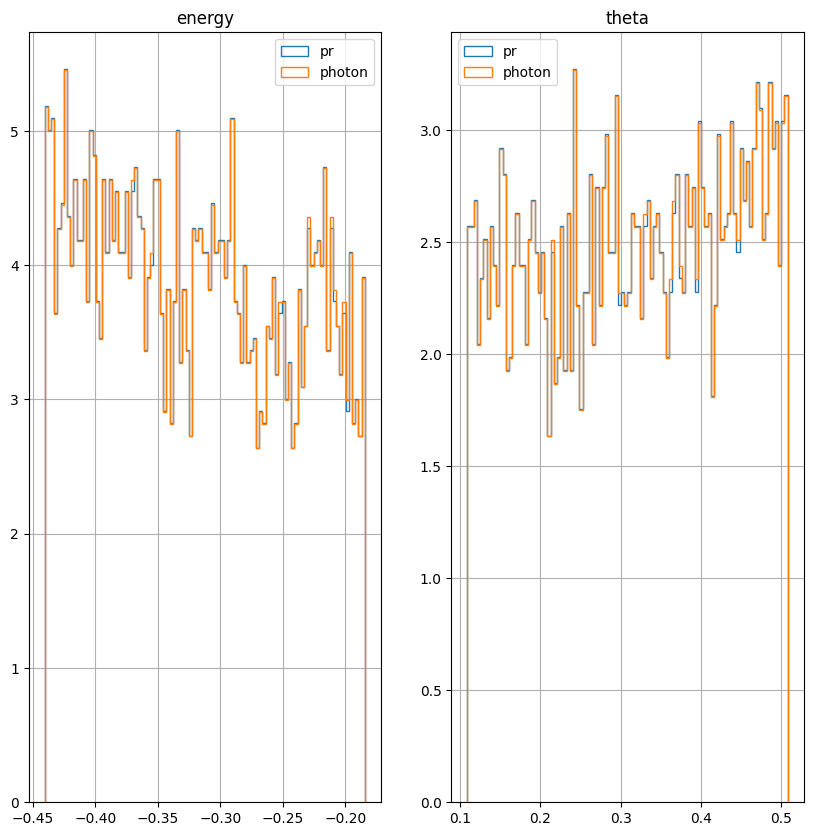

(4291,) (4299,)
0.10917559 0.5077444 0.10912752 0.50777656


In [132]:
index_for_2_bins_pr = np.where(np.logical_and(recos_pr[indexby_ener_pr,0] > norm_theta_min, recos_pr[indexby_ener_pr,0] < norm_theta_max))[0]
index_for_2_bins_photon = np.where(np.logical_and(recos_photon[indexby_ener_photon,0] > norm_theta_min, recos_photon[indexby_ener_photon,0] < norm_theta_max))[0]

index_for_2_bins_pr = indexby_ener_pr[index_for_2_bins_pr]
index_for_2_bins_photon = indexby_ener_photon[index_for_2_bins_photon]
print(recos_pr.shape, indexby_ener_pr.shape, index_for_2_bins_pr.shape)
fig, ax = plt.subplots(1,2, figsize=(10, 10))
ax[0].hist(recos_pr[index_for_2_bins_pr,3], bins=100, label='pr', histtype='step', density=True)
ax[0].hist(recos_photon[index_for_2_bins_photon,3], bins=100, label='photon', histtype='step', density=True)


ax[1].hist(recos_pr[index_for_2_bins_pr,0], bins=100, label='pr', histtype='step', density=True)
ax[1].hist(recos_photon[index_for_2_bins_photon,0], bins=100, label='photon', histtype='step', density=True)

ax[0].legend()
ax[1].legend()

ax[0].set_title('energy')
ax[1].set_title('theta')
ax[0].grid()
ax[1].grid()
plt.show()
print(recos_pr[index_for_2_bins_pr,0].shape, recos_photon[index_for_2_bins_photon,0].shape)
print(recos_pr[index_for_2_bins_pr,0].min(), recos_pr[index_for_2_bins_pr,0].max(), norm_theta_min, norm_theta_max)

In [136]:
# по бинам анализ


N = 10
recos_last = -4
bandwidth = 0.58
part = 0.1
print(f'part of data {part}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
# cut by energy bin and theta bin
index = index_for_2_bins_pr.copy()
index_ph = index_for_2_bins_photon.copy()
index_ph = np.random.choice(index_ph, int(len(index_ph)*part))
print('index_ph', index_ph.shape, 'index', index.shape)

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

# add recos
feaches_pr = np.concatenate([feaches_pr, recos_pr[index, :-recos_last]], axis=1)
feaches_photon = np.concatenate([feaches_photon, recos_photon[index_ph, :-recos_last]], axis=1)


print('feaches_pr', feaches_pr.shape, 'feaches_photon', feaches_photon.shape)

print('with detecor constant',np.sum(feaches_pr[:,8] == N), np.sum(feaches_photon[:,8] == N))


part of data 0.1
pr (210315, 8) ph (210851, 8)
index_ph (429,) index (4291,)
feaches_pr (4291, 14) feaches_photon (429, 14)
with detecor constant 397 35


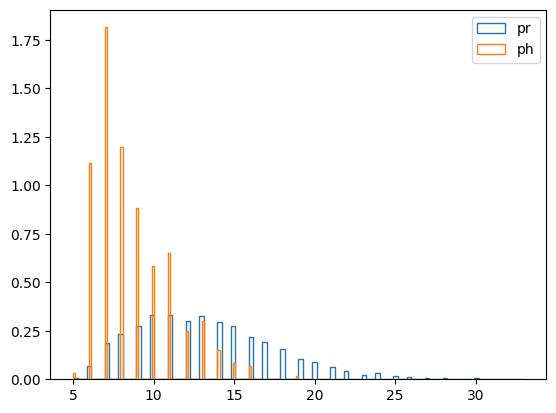

((2123,), (4291, 14), (429, 14))

In [137]:
plt.hist(feaches_pr[:,8], bins=100, label='pr', histtype='step', density=True)
plt.hist(feaches_photon[:,8], bins=100, label='ph', histtype='step', density=True)
plt.legend()
plt.show()
num_det_feaches.shape, feaches_pr.shape, feaches_photon.shape

[[ 2.82276899e-01 -3.06957185e-01  6.13448441e-01 -6.10881150e-01
   1.27034798e-01 -1.07521743e-01 -1.22371924e+00  4.84812647e-01
   1.30000000e+01  7.11033773e-03  4.46862698e-01 -8.30664784e-02
  -3.45073342e-01 -4.20215279e-01]
 [-7.29734182e-01 -1.05972745e-01  8.98605883e-01  1.17789829e+00
   1.05351675e+00 -8.58903468e-01  5.37993386e-02  1.40717298e-01
   1.70000000e+01  9.28837340e-03  2.28627563e-01 -1.34669805e+00
  -1.40255122e-02 -1.85934573e-01]
 [-1.24646568e+00 -6.38287067e-01  1.15432358e+00 -9.88465995e-02
   9.22059536e-01 -3.05995643e-01  6.69436514e-01 -1.00423253e+00
   1.80000000e+01  1.34291090e-02  1.55015677e-01 -8.61243129e-01
  -2.97209501e-01 -4.23903883e-01]
 [ 8.58165979e-01  3.65336448e-01 -2.95471728e-01 -2.28258297e-01
  -1.03493667e+00 -1.38607574e+00 -6.24120712e-01 -8.89965296e-01
   1.00000000e+01  2.86129210e-03  2.94477820e-01 -5.17341018e-01
  -2.23230749e-01 -3.47735614e-01]
 [ 9.60003495e-01 -5.12816787e-01 -1.58817935e+00  3.67598057e-01
  

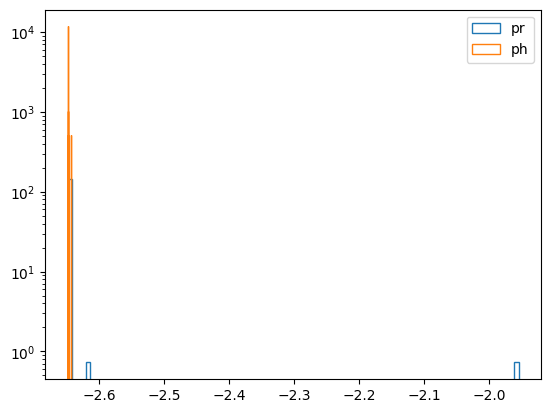

In [139]:
bandwidth = 0.3
feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(len(feaches_pr)), np.ones(len(feaches_photon))])

# # shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,8]

print(feaches[:10], label[:10])


# X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:8], X[:,9:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())


num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()